In [1]:
import subprocess, sys, os
if "COLAB_RELEASE_TAG" in os.environ or "COLAB_GPU" in os.environ:          # as the original notebooks' cell 1
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xarray", "netcdf4", "global-land-mask", "psutil"],
                   check=False)
print("deps ready")

deps ready


In [2]:
import os, sys, gc, json, time, math, re, warnings, datetime, hashlib
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    pass

# BASE is the folder holding the original artefacts (read-only for this notebook).
BASE = Path("/content/drive/MyDrive/MSc Dissertation") if IN_COLAB else Path(os.environ.get("NB05_BASE", "."))
OUT = BASE / "results" / "revision"
OUT.mkdir(parents=True, exist_ok=True)
RESULTS_JSON = OUT / "revision_results.json"
SEED = 0                                               # Bootstrap_v2 cell 1
B = 2000                                               # replicates, as Section 3.12
BLOCK_DAYS = 14
CI = (2.5, 97.5)
NTHREADS = os.cpu_count() or 4
print("BASE =", BASE.resolve(), "| OUT =", OUT, "| threads", NTHREADS)

try:
    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")
except Exception:
    print("torch not importable")

def _jsonable(x):
    if isinstance(x, dict):
        return {str(k): _jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, float):
        return None if not math.isfinite(x) else x
    if isinstance(x, np.ndarray):
        return _jsonable(x.tolist())
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x

def save_section(name, payload):
    """Write one section's results immediately, and merge them into revision_results.json."""
    payload = _jsonable(dict(payload, _saved_utc=datetime.datetime.utcnow().isoformat(timespec="seconds")))
    (OUT / f"{name}.json").write_text(json.dumps(payload, indent=1))
    allr = json.loads(RESULTS_JSON.read_text()) if RESULTS_JSON.exists() else {}
    allr[name] = payload
    RESULTS_JSON.write_text(json.dumps(allr, indent=1))
    print(f"\n>>> saved {name} -> {OUT / (name + '.json')} and merged into {RESULTS_JSON.name}")

def banner(title, gpu, minutes):
    print("=" * 96)
    print(f"{title}\n  needs GPU: {gpu} | estimated time: {minutes} | started {time.strftime('%H:%M:%S')}")
    print("=" * 96)

# Published values that each gate must reproduce, at the precision printed in the dissertation.
EXPECTED = {
    "occ_pr": {"CIEW_v5b": "0.623", "CIGB_v3": "0.581", "HEICH_CR_v2": "0.570", "HEICH_v3": "0.543"},
    "storm_type_auc": "0.660",
    "surv_sev": {"skill": "8.9", "cov": "0.799"},
    "hyb_sev": {"skill": "5.9", "cov": "0.813"},
    "gbt_sev": {"skill": "9.5", "mae": "1.73", "cov": "0.777"},
    "gbt_pr_seed42": "0.581",
    "table42": {"Persistence": ["0.807", "0.476", "0.184"], "Logistic Reg": ["0.893", "0.524", "-0.713"]},
}

Mounted at /content/drive
BASE = /content/drive/MyDrive/MSc Dissertation | OUT = /content/drive/MyDrive/MSc Dissertation/results/revision | threads 12
GPU: NVIDIA A100-SXM4-80GB


In [3]:
SRC = json.loads(r"""{"GBT": {"2": "import os, gc, json, math, time, random, warnings\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nimport matplotlib as mpl\nwarnings.filterwarnings(\"ignore\")\n\nimport lightgbm as lgb\nfrom scipy.stats import genpareto\nfrom sklearn.metrics import (roc_auc_score, average_precision_score,\n                             brier_score_loss, f1_score, mean_absolute_error)\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.isotonic import IsotonicRegression\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.pipeline import make_pipeline\n\nSEED = 42\nrandom.seed(SEED); np.random.seed(SEED)\n\nmpl.rcParams.update({\n    \"figure.dpi\": 120, \"font.family\": \"serif\", \"font.size\": 11,\n    \"axes.titlesize\": 12.5, \"axes.labelsize\": 11,\n    \"axes.spines.top\": False, \"axes.spines.right\": False, \"figure.autolayout\": False,\n})\nprint(\"LightGBM\", lgb.__version__, \"| NumPy\", np.__version__, \"| Pandas\", pd.__version__)", "4": "@dataclass\nclass Config:\n    # ---- run control ----\n    RUN_MODE: str = \"auto\"           # \"auto\" | \"smoke\"\n    # ---- ERA5 domain (identical to CIEW) ----\n    AREA: tuple = (56.0, -6.0, 50.0, 2.0)   # N, W, S, E\n    GRID: float = 0.25\n    YEARS: tuple = tuple(range(2015, 2027))\n    # ---- paths (same folder as CIEW) ----\n    RAW_DIR: Path = field(default_factory=lambda: BASE / \"era5_england_raw_full\")\n    # ---- processing knobs ----\n    TIME_STRIDE: int = 1             # 1 = hourly; 3 => 3-hourly (cuts RAM 3x)\n    MAX_CELLS: int = 0               # 0 = all land/coastal cells; else cap\n    LAND_ONLY: bool = True\n    # ---- extreme-event definition (identical to CIEW) ----\n    POT_Q: float = 0.98\n    DECLUS_HRS: int = 24\n    # ---- forecasting task (identical to CIEW) ----\n    HIST: int = 48                   # history window for rolling aggregates\n    LEAD: int = 24                   # exceedance anywhere in (t, t+LEAD]\n    SAMPLE_STRIDE: int = 3\n    # ---- chronological split (identical to CIEW) ----\n    TRAIN_FRAC: float = 0.70\n    VAL_FRAC: float = 0.15\n    # ---- LightGBM occurrence model ----\n    N_EST: int = 6000            # v2\n    LR: float = 0.02             # v2 (was 0.05)\n    NUM_LEAVES: int = 31         # v2 (was 127: weaker trees)\n    MIN_CHILD: int = 500         # v2 (was 200)\n    FEAT_FRAC: float = 0.8\n    BAG_FRAC: float = 0.8\n    EARLY: int = 300             # v2 (was 150)\n    # ---- v3: physics constraints ----\n    USE_MONOTONE: bool = True        # monotone physical priors on the tree shape\n    RUN_ADV_ABLATION: bool = True    # measure the contribution of the advective term\n    TRAIN_CAP: int = 6_000_000       # max training rows fed to LightGBM\n    VAL_CAP: int = 1_500_000\n    # ---- magnitude model ----\n    QUANTILES: tuple = (0.1, 0.25, 0.5, 0.75, 0.9)\n    # ---- smoke-test synthetic sizing ----\n    SMOKE_DAYS: int = 420\n    SMOKE_NLAT: int = 6\n    SMOKE_NLON: int = 8\n\nCFG = Config()\nCFG.RAW_DIR.mkdir(parents=True, exist_ok=True)\nQLEVELS = np.array(CFG.QUANTILES, dtype=np.float32)\nMEDIAN_IDX = int(np.where(QLEVELS == 0.5)[0][0])\nprint(\"Config ready. RUN_MODE =\", CFG.RUN_MODE)\nprint(\"RAW_DIR =\", CFG.RAW_DIR)\nprint(\"Tip: on a low-RAM runtime set CFG.TIME_STRIDE=3 and CFG.MAX_CELLS=250 before running on.\")", "6": "# ---- canonical short-name mapping & robust ERA5 loader (identical to CIEW) ----\nRENAME = {\n    \"u10\": \"u10\", \"v10\": \"v10\", \"u100\": \"u100\", \"v100\": \"v100\",\n    \"i10fg\": \"i10fg\", \"fg10\": \"fg10\", \"cape\": \"cape\",\n    \"kx\": \"kx\", \"tcwv\": \"tcwv\", \"blh\": \"blh\", \"msl\": \"msl\", \"sp\": \"sp\",\n    \"t2m\": \"t2m\", \"d2m\": \"d2m\",\n    \"10fg\": \"fg10\", \"instantaneous_10m_wind_gust\": \"i10fg\",\n}\n\ndef load_era5_netcdf(files, cfg):\n    import xarray as xr\n    ds = xr.open_mfdataset([str(f) for f in files], combine=\"by_coords\",\n                           engine=\"netcdf4\", chunks={\"time\": 1500})\n    for a, b in [(\"latitude\", \"lat\"), (\"longitude\", \"lon\"), (\"valid_time\", \"time\")]:\n        if a in ds.dims or a in ds.coords:\n            ds = ds.rename({a: b})\n    if \"expver\" in ds.dims:\n        ds = ds.mean(\"expver\")\n    elif \"expver\" in ds.coords:\n        ds = ds.drop_vars(\"expver\")\n    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})\n    if cfg.TIME_STRIDE > 1:\n        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))\n    ds = ds.sortby(\"time\").sortby(\"lat\").sortby(\"lon\")\n    times = pd.DatetimeIndex(ds.time.values)\n    lats = ds.lat.values.astype(np.float32)\n    lons = ds.lon.values.astype(np.float32)\n    fields = {}\n    for name in [\"u10\",\"v10\",\"u100\",\"v100\",\"i10fg\",\"fg10\",\"cape\",\"kx\",\n                 \"tcwv\",\"blh\",\"msl\",\"sp\",\"t2m\",\"d2m\"]:\n        if name in ds.variables:\n            fields[name] = ds[name].transpose(\"time\",\"lat\",\"lon\").values.astype(np.float32)\n    if \"sp\"  in fields: fields[\"sp\"]  = fields[\"sp\"] / 100.0   # Pa -> hPa\n    if \"msl\" in fields: fields[\"msl\"] = fields[\"msl\"] / 100.0  # Pa -> hPa\n    for k in (\"t2m\", \"d2m\"):\n        if k in fields: fields[k] = fields[k] - 273.15         # K -> degC\n    ds.close()\n    return times, lats, lons, fields\n\nRAW_FILES = sorted(CFG.RAW_DIR.glob(\"*.nc\"))\nprint(f\"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}\")", "7": "# ---- synthetic ERA5-like generator (smoke test / offline dev) ----\ndef make_synthetic(cfg):\n    rng = np.random.default_rng(SEED)\n    T = cfg.SMOKE_DAYS * 24\n    times = pd.date_range(\"2019-01-01\", periods=T, freq=\"h\")\n    nlat, nlon = cfg.SMOKE_NLAT, cfg.SMOKE_NLON\n    lats = np.linspace(50, 56, nlat).astype(np.float32)\n    lons = np.linspace(-6, 2, nlon).astype(np.float32)\n    doy = times.dayofyear.values.astype(np.float32)\n    hod = times.hour.values.astype(np.float32)\n\n    def red_noise(scale, r=0.98):\n        x = np.zeros((T, nlat, nlon), np.float32)\n        e = rng.normal(0, scale, (T, nlat, nlon)).astype(np.float32)\n        for t in range(1, T):\n            x[t] = r * x[t-1] + e[t]\n        return x\n\n    seas = (1 + 0.45*np.cos(2*np.pi*(doy - 20)/365.25))[:, None, None]\n    synop = red_noise(0.55)\n    storms = np.clip(red_noise(0.9, 0.995), 0, 3)**2\n    ws10 = np.clip(6*seas + 2.2*synop + 1.6*storms\n                   + rng.normal(0, 0.6, (T, nlat, nlon)), 0.2, None).astype(np.float32)\n    ang = 3.0 * red_noise(0.15)\n    conv = np.clip(np.sin(2*np.pi*(doy - 100)/365.25), 0, None)[:, None, None]\n    F = {}\n    F[\"u10\"], F[\"v10\"] = ws10*np.cos(ang), ws10*np.sin(ang)\n    ws100 = np.clip(1.3*ws10 + rng.normal(0, 0.5, (T, nlat, nlon)), 0.2, None)\n    F[\"u100\"], F[\"v100\"] = ws100*np.cos(ang), ws100*np.sin(ang)\n    F[\"i10fg\"] = (ws10*(1.35 + 0.25*rng.random((T, nlat, nlon)))).astype(np.float32)\n    F[\"cape\"] = (600*conv*np.clip(red_noise(0.5, 0.97), 0, None)**2).astype(np.float32)\n    F[\"kx\"]   = (18 + 10*conv + 4*red_noise(0.4)).astype(np.float32)\n    F[\"tcwv\"] = (16 + 9*conv + 2.5*red_noise(0.35)).astype(np.float32)\n    F[\"blh\"]  = np.clip(650 + 320*red_noise(0.5)\n                        + 260*np.cos(2*np.pi*(hod[:, None, None] - 14)/24), 40, None).astype(np.float32)\n    F[\"msl\"]  = (1013 - 7*synop + 2.2*red_noise(0.35)).astype(np.float32)\n    F[\"sp\"]   = (F[\"msl\"] - 2.0).astype(np.float32)\n    F[\"t2m\"]  = (10 + 7.5*np.cos(2*np.pi*(doy[:, None, None] - 200)/365.25)\n                 + 1.6*red_noise(0.4)).astype(np.float32)\n    F[\"d2m\"]  = (F[\"t2m\"] - np.clip(2.5 + 2.0*red_noise(0.35), 0.2, None)).astype(np.float32)\n    return times, lats, lons, {k: v.astype(np.float32) for k, v in F.items()}\nprint(\"Synthetic generator defined.\")", "8": "# ---- resolve data source ----\nUSING_SYNTHETIC = False\nif CFG.RUN_MODE == \"smoke\" or (CFG.RUN_MODE == \"auto\" and not RAW_FILES):\n    if CFG.RUN_MODE == \"auto\":\n        print(\"!! No ERA5 NetCDF found - generating SYNTHETIC data so the pipeline runs.\")\n        print(\"   Point CFG.RAW_DIR at the real files and re-run for dissertation results.\")\n    times, lats, lons, FIELDS = make_synthetic(CFG)\n    USING_SYNTHETIC = True\nelse:\n    times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)\n\nnlat, nlon = len(lats), len(lons)\nT = len(times)\nprint(f\"{'SYNTHETIC' if USING_SYNTHETIC else 'ERA5'} data loaded\")\nprint(f\"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)\")\nprint(f\"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}\")", "9": "# ---- derived scalar fields + land mask + cell selection (identical logic to CIEW) ----\ndef hypot(a, b): return np.sqrt(a*a + b*b)\n\nFIELDS[\"ws10\"]  = hypot(FIELDS[\"u10\"],  FIELDS[\"v10\"]).astype(np.float32)\nFIELDS[\"ws100\"] = hypot(FIELDS[\"u100\"], FIELDS[\"v100\"]).astype(np.float32)\nif \"i10fg\" in FIELDS:\n    FIELDS[\"gust\"] = FIELDS[\"i10fg\"]\nelif \"fg10\" in FIELDS:\n    FIELDS[\"gust\"] = FIELDS[\"fg10\"]\nelse:\n    FIELDS[\"gust\"] = (1.4*FIELDS[\"ws10\"]).astype(np.float32)\n\ndef _clean_field(a):\n    if not np.isnan(a).any():\n        return a.astype(np.float32)\n    Tt = a.shape[0]\n    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction=\"both\", axis=0)\n    flat = flat.fillna(flat.mean())\n    return flat.values.reshape(a.shape).astype(np.float32)\n\n_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())\nif _nan_before:\n    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}\n    print(f\"NaN cleaning: {_nan_before:,} missing values filled\")\n\nland_mask = np.ones((nlat, nlon), dtype=bool)\nif CFG.LAND_ONLY and not USING_SYNTHETIC:\n    try:\n        from global_land_mask import globe\n        from scipy.ndimage import binary_dilation\n        LO, LA = np.meshgrid(lons, lats)\n        land_mask = binary_dilation(globe.is_land(LA, LO), iterations=1)\n        print(f\"Land+coastal cells: {land_mask.sum()}/{land_mask.size}\")\n    except Exception as e:\n        print(\"global_land_mask unavailable - keeping all cells:\", e)\n\ncell_ii, cell_jj = np.where(land_mask)\nif CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:\n    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)\n    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]\nN_CELLS = len(cell_ii)\ncell_lat = lats[cell_ii].astype(np.float32)\ncell_lon = lons[cell_jj].astype(np.float32)\n\ndef cs(name):\n    \"\"\"Cell-stack a full-grid field -> (T, N_CELLS).\"\"\"\n    return FIELDS[name][:, cell_ii, cell_jj].astype(np.float32)\n\ngust_cells = cs(\"gust\")                                # (T, N_CELLS) - used everywhere below\nprint(f\"Modelling {N_CELLS} cells | gust mean={gust_cells.mean():.2f}  max={gust_cells.max():.2f} m/s\")", "13": "# seasonal x diurnal structure of extremes + gust distribution\nthr_cell_all = np.percentile(gust_cells, CFG.POT_Q*100, axis=0)     # descriptive only\nexc_any = (gust_cells > thr_cell_all[None, :])\nexc_frac = exc_any.mean(axis=1)                                     # fraction of cells exceeding\nhm = pd.DataFrame({\"m\": times.month, \"h\": times.hour, \"e\": exc_frac}) \\\n       .pivot_table(index=\"m\", columns=\"h\", values=\"e\", aggfunc=\"mean\")\n\nfig, ax = plt.subplots(1, 2, figsize=(13.5, 4.4))\nim = ax[0].imshow(hm.values, aspect=\"auto\", cmap=\"magma\", origin=\"lower\")\nax[0].set_xticks(range(0, 24, 3)); ax[0].set_xticklabels(range(0, 24, 3))\nax[0].set_yticks(range(12)); ax[0].set_yticklabels(range(1, 13))\nax[0].set_xlabel(\"hour (UTC)\"); ax[0].set_ylabel(\"month\")\nax[0].set_title(\"P(cell exceeds its P98) by month x hour\")\nplt.colorbar(im, ax=ax[0], shrink=0.9)\n\nax[1].hist(gust_cells.ravel()[::37], bins=80, color=\"#33507a\", alpha=0.85)\nax[1].axvline(thr_cell_all.mean(), color=\"crimson\", ls=\"--\",\n              label=f\"mean P98 = {thr_cell_all.mean():.1f} m/s\")\nax[1].set_xlabel(\"gust (m/s)\"); ax[1].set_title(\"Pooled gust distribution\"); ax[1].legend()\nplt.show()", "16": "def cell_events(x, thr, gap):\n    \"\"\"Declustered exceedance peak indices for a 1-D series (runs declustering).\"\"\"\n    ex = x > thr\n    if not ex.any():\n        return np.empty(0, dtype=int)\n    d = np.diff(ex.astype(np.int8))\n    starts = np.flatnonzero(d == 1) + 1\n    ends   = np.flatnonzero(d == -1) + 1\n    if ex[0]:  starts = np.r_[0, starts]\n    if ex[-1]: ends   = np.r_[ends, len(x)]\n    peaks = np.array([s + int(np.argmax(x[s:e])) for s, e in zip(starts, ends)])\n    sel = [peaks[0]]\n    for p in peaks[1:]:\n        if p - sel[-1] >= gap:\n            sel.append(p)\n        elif x[p] > x[sel[-1]]:\n            sel[-1] = p\n    return np.asarray(sel)\n\n# per-cell ADI / CV2 at local P98 (full record - descriptive)\nadi = np.full(N_CELLS, np.nan, np.float32)\ncv2 = np.full(N_CELLS, np.nan, np.float32)\nn_ev = np.zeros(N_CELLS, np.int32)\nia_pool = []\nfor k in range(N_CELLS):\n    pk = cell_events(gust_cells[:, k], thr_cell_all[k], CFG.DECLUS_HRS)\n    n_ev[k] = len(pk)\n    if len(pk) >= 3:\n        ia = np.diff(pk).astype(np.float32) * CFG.TIME_STRIDE\n        exc = gust_cells[pk, k] - thr_cell_all[k]\n        adi[k] = ia.mean()\n        cv2[k] = (exc.std() / max(exc.mean(), 1e-6))**2\n        ia_pool.append(ia)\nia_pool = np.concatenate(ia_pool) if ia_pool else np.array([])\nprint(f\"Events per cell: median {np.median(n_ev):.0f}  [{n_ev.min()} - {n_ev.max()}]\")\nprint(f\"ADI  : median {np.nanmedian(adi):.0f} h  | CV2: median {np.nanmedian(cv2):.2f}\")", "21": "# ---- chronological split boundaries (identical rule to CIEW) ----\ntstamp = times.values.astype(\"datetime64[ns]\")\nspan = tstamp[-1] - tstamp[0]\ntrain_end = tstamp[0] + span * CFG.TRAIN_FRAC\nval_end   = tstamp[0] + span * (CFG.TRAIN_FRAC + CFG.VAL_FRAC)\nis_train_t = tstamp <= train_end\nprint(f\"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after\")\n\n# per-cell TRAIN P98 threshold - used for target AND intermittency state features\nthr_train = np.array([np.nanpercentile(gust_cells[is_train_t, k], CFG.POT_Q*100)\n                      for k in range(N_CELLS)], dtype=np.float32)\nprint(f\"Train P{int(CFG.POT_Q*100)} threshold: mean={thr_train.mean():.2f} m/s \"\n      f\"[{thr_train.min():.1f}, {thr_train.max():.1f}]\")", "23": "# ---- grid-level synoptic features from MSLP (identical to CIEW) ----\nGRID_KM = CFG.GRID * 111.32\nlat_rad = np.deg2rad(lats)\ndlat_km = GRID_KM\ndlon_km = np.maximum(GRID_KM*np.cos(lat_rad), 1e-3)\n\nmsl_g = FIELDS[\"msl\"]\ngy = np.gradient(msl_g, axis=1) / dlat_km\ngx = np.gradient(msl_g, axis=2) / dlon_km[None, :, None]\npgf_g = np.sqrt(gx*gx + gy*gy).astype(np.float32)\nlap_g = (np.gradient(gy, axis=1) + np.gradient(gx, axis=2)).astype(np.float32)\nf_cor = np.maximum(2*7.292e-5*np.abs(np.sin(lat_rad)), 2e-5)[None, :, None]\nvgeo_g = (pgf_g*100.0/1000.0 / (1.225*f_cor)).astype(np.float32)\nmsl_tend_g = np.zeros_like(msl_g); msl_tend_g[3:] = msl_g[3:] - msl_g[:-3]\nprint(\"Synoptic grid features computed:\", pgf_g.shape)", "24": "# ---- base per-cell features: kinematic / convective / synoptic ----\neps = 1e-6\nFEAT = {}                                   # name -> (T, N_CELLS)\n\nws10c, ws100c = cs(\"ws10\"), cs(\"ws100\")\nshear = (ws100c - ws10c).astype(np.float32)\nu10c, v10c = cs(\"u10\"), cs(\"v10\")\nwdir = np.arctan2(v10c, u10c)\nFEAT[\"ws10\"] = ws10c; FEAT[\"ws100\"] = ws100c; FEAT[\"gust\"] = gust_cells\nFEAT[\"gust_factor\"] = (gust_cells/(ws10c + eps)).astype(np.float32)\nFEAT[\"shear\"] = shear\nFEAT[\"wdir_sin\"] = np.sin(wdir).astype(np.float32)\nFEAT[\"wdir_cos\"] = np.cos(wdir).astype(np.float32)\nFEAT[\"blh\"] = cs(\"blh\"); FEAT[\"t2m\"] = cs(\"t2m\")\n\ncape = cs(\"cape\") if \"cape\" in FIELDS else np.zeros_like(ws10c)\nFEAT[\"cape\"] = cape\nFEAT[\"sqrt_cape\"] = np.sqrt(np.clip(cape, 0, None)).astype(np.float32)\nFEAT[\"wmaxshear\"] = (np.sqrt(2*np.clip(cape, 0, None))*shear).astype(np.float32)\nfor nm in [\"kx\", \"tcwv\"]:\n    FEAT[nm] = cs(nm) if nm in FIELDS else np.zeros_like(ws10c)\nFEAT[\"dd\"] = (cs(\"t2m\") - cs(\"d2m\")).astype(np.float32) if \"d2m\" in FIELDS else np.zeros_like(ws10c)\n\nFEAT[\"msl\"] = msl_g[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"pgf\"] = pgf_g[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"lap\"] = lap_g[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"vgeo\"] = vgeo_g[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"msl_tend\"] = msl_tend_g[:, cell_ii, cell_jj].astype(np.float32)\n\ndel u10c, v10c, wdir\ngc.collect()\nprint(f\"Base features: {len(FEAT)}\")", "25": "# ---- spatial neighbourhood features (5x5 window ~ 125 km of context) ----\n# Neighbourhood max/mean catch storms that have reached adjacent cells but not this one\n# yet; the advection term -(V . grad gust) is the physical 'upwind gust incoming' signal.\nfrom scipy.ndimage import maximum_filter, uniform_filter\n\ndef nmax(a):  return maximum_filter(a, size=(1, 5, 5), mode=\"nearest\")\ndef nmean(a): return uniform_filter(a, size=(1, 5, 5), mode=\"nearest\")\n\ngust_g = FIELDS[\"gust\"]\ncape_g = FIELDS[\"cape\"] if \"cape\" in FIELDS else np.zeros_like(gust_g)\nwmax_g = (np.sqrt(2*np.clip(cape_g, 0, None))\n          * (FIELDS[\"ws100\"] - FIELDS[\"ws10\"])).astype(np.float32)\n\nFEAT[\"gust_nmax5\"]      = nmax(gust_g)[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"cape_nmean5\"]     = nmean(cape_g)[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"wmaxshear_nmax5\"] = nmax(wmax_g)[:, cell_ii, cell_jj].astype(np.float32)\nFEAT[\"pgf_nmax5\"]       = nmax(pgf_g)[:, cell_ii, cell_jj].astype(np.float32)\n\n# advection proxy: (m/s)/h of gust change advected by the 10 m wind (u in km/h x grad per km)\nggy = np.gradient(gust_g, axis=1) / dlat_km\nggx = np.gradient(gust_g, axis=2) / dlon_km[None, :, None]\nadv = -(3.6*FIELDS[\"u10\"]*ggx + 3.6*FIELDS[\"v10\"]*ggy)\nFEAT[\"adv_gust\"] = adv[:, cell_ii, cell_jj].astype(np.float32)\n\ndel wmax_g, ggx, ggy, adv, gy, gx, pgf_g, lap_g, vgeo_g, msl_tend_g\ngc.collect()\nprint(\"Spatial neighbourhood features added:\",\n      [c for c in FEAT if \"nmax5\" in c or \"nmean5\" in c or c == \"adv_gust\"])", "26": "# ---- intermittency features (the intermittent-demand logic, as predictors) ----\nexc_state = gust_cells > thr_train[None, :]              # causal state w.r.t. train threshold\n\n# time since last exceedance + previous inter-arrival (strictly before t)\ntsl = np.zeros((T, N_CELLS), np.float32)\nprev_ia = np.zeros((T, N_CELLS), np.float32)\nlast = np.full(N_CELLS, -10**6, np.int64)\nlast2 = np.full(N_CELLS, -2*10**6, np.int64)\ntt = np.arange(T, dtype=np.int64)\nfor t in range(T):\n    tsl[t] = tt[t] - last\n    prev_ia[t] = last - last2\n    hit = exc_state[t]\n    last2 = np.where(hit, last, last2)\n    last = np.where(hit, t, last)\nCLIP_H = 24*30\ntsl = np.clip(tsl, 0, CLIP_H).astype(np.float32)\nprev_ia = np.clip(prev_ia, 0, CLIP_H).astype(np.float32)\nFEAT[\"tsl\"] = tsl\nFEAT[\"prev_ia\"] = prev_ia\n\n# causal rolling exceedance counts (7-day and 30-day)\ncsum = np.cumsum(exc_state.astype(np.float32), axis=0)\nfor nm, win_d in [(\"roll7\", 7), (\"roll30\", 30)]:\n    w = 24*win_d\n    r = np.zeros_like(csum)\n    r[w:] = csum[w:] - csum[:-w]; r[:w] = csum[:w]\n    FEAT[nm] = r.astype(np.float32)\ndel csum; gc.collect()\n\n# static per-cell intermittency stats from TRAIN period only (leakage-free)\nSFEAT = {}\nadi_tr = np.full(N_CELLS, np.nan, np.float32)\ncv2_tr = np.full(N_CELLS, np.nan, np.float32)\nevrate_tr = np.zeros(N_CELLS, np.float32)\ntr_years = is_train_t.sum() * CFG.TIME_STRIDE / (24*365.25)\nfor k in range(N_CELLS):\n    pk = cell_events(gust_cells[is_train_t, k], thr_train[k], CFG.DECLUS_HRS)\n    evrate_tr[k] = len(pk) / max(tr_years, 1e-6)\n    if len(pk) >= 3:\n        ia = np.diff(pk).astype(np.float32) * CFG.TIME_STRIDE\n        ex = gust_cells[is_train_t, k][pk] - thr_train[k]\n        adi_tr[k] = ia.mean()\n        cv2_tr[k] = (ex.std()/max(ex.mean(), 1e-6))**2\nadi_tr = np.nan_to_num(adi_tr, nan=float(np.nanmedian(adi_tr)))\ncv2_tr = np.nan_to_num(cv2_tr, nan=float(np.nanmedian(cv2_tr)))\nSFEAT[\"adi_cell\"] = adi_tr\nSFEAT[\"cv2_cell\"] = cv2_tr\nSFEAT[\"evrate_cell\"] = evrate_tr\nSFEAT[\"thr_cell\"] = thr_train\nSFEAT[\"lat_cell\"] = cell_lat\nSFEAT[\"lon_cell\"] = cell_lon\nprint(f\"Intermittency features ready. Train event rate: {evrate_tr.mean():.1f} events/cell/year\")", "27": "# ---- temporal aggregates over the history window (replaces the transformer encoder) ----\nAGG_KEYS = [\"gust\", \"ws100\", \"shear\", \"cape\", \"wmaxshear\", \"pgf\", \"vgeo\"]\n\ndef roll_max(a, w):\n    return pd.DataFrame(a).rolling(w, min_periods=1).max().values.astype(np.float32)\n\ndef roll_mean(a, w):\n    c = np.cumsum(a, axis=0, dtype=np.float64)\n    out = np.empty_like(a, dtype=np.float32)\n    out[:w] = (c[:w] / np.arange(1, w+1)[:, None]).astype(np.float32)\n    out[w:] = ((c[w:] - c[:-w]) / w).astype(np.float32)\n    return out\n\nfor key in AGG_KEYS:\n    a = FEAT[key]\n    FEAT[f\"{key}_max24\"]  = roll_max(a, 24)\n    FEAT[f\"{key}_max48\"]  = roll_max(a, CFG.HIST)\n    FEAT[f\"{key}_mean24\"] = roll_mean(a, 24)\n\ndef tend(a, k):\n    o = np.zeros_like(a); o[k:] = a[k:] - a[:-k]; return o.astype(np.float32)\n\nfor key in [\"gust\", \"msl\", \"blh\", \"tcwv\"]:\n    FEAT[f\"{key}_tend3\"]  = tend(FEAT[key], 3)\n    FEAT[f\"{key}_tend24\"] = tend(FEAT[key], 24)\n\n# weak-supervision regime score (convective vs synoptic), as a feature\ndef zc(a):\n    _t = a[is_train_t]   # FIX 03: train-period location/scale only\n    med = np.median(_t); iqr = np.subtract(*np.percentile(_t, [75, 25])) + 1e-6\n    return (a - med)/iqr\nconv_score = zc(FEAT[\"wmaxshear\"]) + 0.5*zc(FEAT[\"cape\"]) + 0.3*zc(FEAT[\"kx\"])\nsyn_score  = zc(FEAT[\"vgeo\"]) + 0.7*zc(FEAT[\"pgf\"]) + 0.3*np.abs(zc(FEAT[\"msl_tend\"]))\nFEAT[\"conv_minus_syn\"] = (conv_score - syn_score).astype(np.float32)\nREGIME = (conv_score > syn_score)\nprint(f\"Regime prior - convective share of hours: {REGIME.mean()*100:.1f}%\")\ndel conv_score, syn_score; gc.collect()\n\n# time-only cyclic features (stored once, broadcast at gather time)\nTFEAT = {\n    \"sin_m\": np.sin(2*np.pi*times.month.values/12).astype(np.float32),\n    \"cos_m\": np.cos(2*np.pi*times.month.values/12).astype(np.float32),\n    \"sin_h\": np.sin(2*np.pi*times.hour.values/24).astype(np.float32),\n    \"cos_h\": np.cos(2*np.pi*times.hour.values/24).astype(np.float32),\n}\n\nFEATURE_COLS = list(FEAT.keys()) + list(TFEAT.keys()) + list(SFEAT.keys())\nmem_gb = sum(v.nbytes for v in FEAT.values())/1e9\nprint(f\"Total features: {len(FEATURE_COLS)}  |  (T,N) array memory: {mem_gb:.1f} GB\")\n\n# feature families (used for SHAP grouping and the ablation study)\nFAMILIES = {\n    \"intermittency\": [\"tsl\",\"prev_ia\",\"roll7\",\"roll30\",\"adi_cell\",\"cv2_cell\",\"evrate_cell\",\"thr_cell\"],\n    \"convective\":    [\"cape\",\"sqrt_cape\",\"kx\",\"tcwv\",\"dd\",\"wmaxshear\",\n                      \"cape_max24\",\"cape_max48\",\"cape_mean24\",\n                      \"wmaxshear_max24\",\"wmaxshear_max48\",\"wmaxshear_mean24\",\n                      \"tcwv_tend3\",\"tcwv_tend24\",\"conv_minus_syn\"],\n    \"synoptic\":      [\"msl\",\"pgf\",\"lap\",\"vgeo\",\"msl_tend\",\"msl_tend3\",\"msl_tend24\",\n                      \"pgf_max24\",\"pgf_max48\",\"pgf_mean24\",\n                      \"vgeo_max24\",\"vgeo_max48\",\"vgeo_mean24\"],\n    \"kinematic\":     [\"ws10\",\"ws100\",\"gust\",\"gust_factor\",\"shear\",\"wdir_sin\",\"wdir_cos\",\n                      \"blh\",\"t2m\",\"gust_max24\",\"gust_max48\",\"gust_mean24\",\n                      \"ws100_max24\",\"ws100_max48\",\"ws100_mean24\",\n                      \"shear_max24\",\"shear_max48\",\"shear_mean24\",\n                      \"gust_tend3\",\"gust_tend24\",\"blh_tend3\",\"blh_tend24\"],\n    \"spatial\":       [\"gust_nmax5\",\"cape_nmean5\",\"wmaxshear_nmax5\",\"pgf_nmax5\",\"adv_gust\"],\n    \"temporal\":      [\"sin_m\",\"cos_m\",\"sin_h\",\"cos_h\",\"lat_cell\",\"lon_cell\"],\n}\n_covered = set(sum(FAMILIES.values(), []))\n_missing = [c for c in FEATURE_COLS if c not in _covered]\nassert not _missing, \"unassigned features: \" + str(_missing)\nprint(\"Families:\", {k: len(v) for k, v in FAMILIES.items()})\n", "29": "# forward rolling max of gust over (t, t+LEAD]\nfm = np.full_like(gust_cells, -np.inf)\nfor d in range(1, CFG.LEAD + 1):\n    fm[:T-d] = np.maximum(fm[:T-d], gust_cells[d:])\nocc_all = (fm > thr_train[None, :]).astype(np.float32)\nmag_all = np.log(np.clip(fm - thr_train[None, :], 1e-3, None)).astype(np.float32)\nprint(f\"Base occurrence rate (all cells/hours): {occ_all[:T-CFG.LEAD].mean()*100:.2f}%\")", "30": "# (cell, t) sample index - complete future window only, strided\nts = np.arange(CFG.HIST - 1, T - CFG.LEAD, CFG.SAMPLE_STRIDE, dtype=np.int32)\nt_idx = np.tile(ts, N_CELLS)\nc_idx = np.repeat(np.arange(N_CELLS, dtype=np.int32), len(ts))\n\norigin_time = tstamp[t_idx]\nsplit = np.where(origin_time <= train_end, 0, np.where(origin_time <= val_end, 1, 2))\ntr_sel = np.flatnonzero(split == 0)\nva_sel = np.flatnonzero(split == 1)\nte_sel = np.flatnonzero(split == 2)\nprint(f\"Samples - train {len(tr_sel):,} | val {len(va_sel):,} | test {len(te_sel):,}\")\n\nOCC = occ_all[t_idx, c_idx]\nMAG = mag_all[t_idx, c_idx]\nFMX = fm[t_idx, c_idx]\nTHR = thr_train[c_idx]\nREG = REGIME[t_idx, c_idx]\nfor nm, sel in [(\"train\", tr_sel), (\"val\", va_sel), (\"test\", te_sel)]:\n    print(f\"  {nm} positive rate: {OCC[sel].mean()*100:.2f}%\")", "31": "# assemble the tabular design matrix X (named columns -> LightGBM + SHAP)\ndef build_X(sel):\n    n = len(sel)\n    k = c_idx[sel]; t = t_idx[sel]\n    data = {}\n    for name, arr in FEAT.items():\n        data[name] = arr[t, k]\n    for name, vec in TFEAT.items():\n        data[name] = vec[t]\n    for name, vec in SFEAT.items():\n        data[name] = vec[k]\n    return pd.DataFrame(data, copy=False).astype(np.float32)\n\nrng = np.random.default_rng(SEED)\ntr_fit = tr_sel if len(tr_sel) <= CFG.TRAIN_CAP else \\\n         np.sort(rng.choice(tr_sel, CFG.TRAIN_CAP, replace=False))\nva_fit = va_sel if len(va_sel) <= CFG.VAL_CAP else \\\n         np.sort(rng.choice(va_sel, CFG.VAL_CAP, replace=False))\n\nt0 = time.time()\nXtr, ytr = build_X(tr_fit), OCC[tr_fit]\nXva, yva = build_X(va_fit), OCC[va_fit]\nXte, yte = build_X(te_sel), OCC[te_sel]\nprint(f\"X built in {time.time()-t0:.0f}s | train {Xtr.shape} | val {Xva.shape} | test {Xte.shape}\")\nprint(f\"Design-matrix memory: {(Xtr.values.nbytes + Xva.values.nbytes + Xte.values.nbytes)/1e9:.1f} GB\")", "33": "pos_w = float((ytr == 0).sum() / max((ytr == 1).sum(), 1))\nprint(f\"scale_pos_weight = {pos_w:.1f}\")\n\n# ---- physical monotonicity priors -------------------------------------------------------------\n# +1 : the exceedance probability may not decrease as the predictor increases\n# -1 : it may not increase\n# Each entry is a statement about physics, not about the data: a steeper pressure gradient, a\n# stronger geostrophic wind or a higher current gust cannot reduce the risk of an extreme gust, and\n# a deeper low cannot reduce it either.\nMONO_UP = [\"gust\", \"ws10\", \"ws100\", \"pgf\", \"vgeo\",\n           \"gust_max24\", \"gust_max48\", \"gust_mean24\",\n           \"ws100_max24\", \"ws100_max48\", \"pgf_max24\", \"pgf_max48\",\n           \"vgeo_max24\", \"vgeo_max48\", \"gust_nmax5\", \"pgf_nmax5\"]\nMONO_DOWN = [\"msl\", \"sp\"]\n\ndef build_monotone(cols):\n    v = []\n    for c in cols:\n        v.append(1 if c in MONO_UP else (-1 if c in MONO_DOWN else 0))\n    return v\n\nMONO = build_monotone(list(Xtr.columns))\nn_up = sum(1 for m in MONO if m > 0); n_dn = sum(1 for m in MONO if m < 0)\nif CFG.USE_MONOTONE:\n    print(f\"monotone constraints: {n_up} increasing, {n_dn} decreasing, \"\n          f\"{len(MONO)-n_up-n_dn} free of {len(MONO)} features\")\nelse:\n    MONO = None\n    print(\"monotone constraints disabled (v2 behaviour)\")\n\nclf = lgb.LGBMClassifier(\n    monotone_constraints=MONO,\n    metric=\"average_precision\",        # FIX 01: suppress the auto-added binary_logloss.\n                                       # objective=\"binary\" adds it silently, and under\n                                       # scale_pos_weight it degrades within a dozen rounds.\n    objective=\"binary\", n_estimators=CFG.N_EST, learning_rate=CFG.LR,\n    num_leaves=CFG.NUM_LEAVES, min_child_samples=CFG.MIN_CHILD,\n    colsample_bytree=CFG.FEAT_FRAC, subsample=CFG.BAG_FRAC, subsample_freq=1,\n    scale_pos_weight=pos_w, reg_lambda=5.0, reg_alpha=1.0, min_split_gain=1e-3, max_bin=255,\n    random_state=SEED, n_jobs=-1, verbosity=-1)\n\nt0 = time.time()\nclf.fit(Xtr, ytr,\n        eval_set=[(Xva, yva)], eval_metric=\"average_precision\",\n        callbacks=[lgb.early_stopping(CFG.EARLY, first_metric_only=True, verbose=False),\n                   lgb.log_evaluation(200)])\nprint(f\"Trained in {(time.time()-t0)/60:.1f} min | best iteration: {clf.best_iteration_}\")\nassert (clf.best_iteration_ or CFG.N_EST) > 50, (\n    f\"stopped at {clf.best_iteration_} trees - early stopping is still driven by a \"\n    f\"metric other than average_precision. Check metric= and first_metric_only=.\")\n\np_va_raw = clf.predict_proba(Xva)[:, 1]\np_te_raw = clf.predict_proba(Xte)[:, 1]\nprint(f\"Raw val PR-AUC: {average_precision_score(yva, p_va_raw):.4f} \"\n      f\"(prevalence {yva.mean()*100:.2f}%)\")", "34": "# isotonic probability calibration on validation\niso = IsotonicRegression(out_of_bounds=\"clip\", y_min=0.0, y_max=1.0)\niso.fit(p_va_raw, yva)\np_va = iso.predict(p_va_raw)\np_te = iso.predict(p_te_raw)\nprint(f\"Calibrated Brier - val: raw {brier_score_loss(yva, p_va_raw):.4f} \"\n      f\"-> cal {brier_score_loss(yva, p_va):.4f}\")\nprint(f\"Mean predicted vs observed (val): {p_va.mean()*100:.2f}% vs {yva.mean()*100:.2f}%\")\n\nfi = pd.Series(clf.feature_importances_, index=Xtr.columns).sort_values(ascending=False)\nprint(\"\\nTop-15 features by split importance:\")\nprint(fi.head(15).to_string())", "36": "pos_tr = tr_fit[OCC[tr_fit] > 0.5]\npos_va = va_fit[OCC[va_fit] > 0.5]\npos_te = te_sel[OCC[te_sel] > 0.5]\nXtr_p, mtr = build_X(pos_tr), MAG[pos_tr]\nXva_p, mva = build_X(pos_va), MAG[pos_va]\nXte_p, mte = build_X(pos_te), MAG[pos_te]\nprint(f\"Positives - train {len(pos_tr):,} | val {len(pos_va):,} | test {len(pos_te):,}\")\n\nQ_MODELS = {}\nt0 = time.time()\nfor q in CFG.QUANTILES:\n    m = lgb.LGBMRegressor(objective=\"quantile\", alpha=float(q),\n                          n_estimators=800, learning_rate=0.05, num_leaves=63,\n                          min_child_samples=150, colsample_bytree=0.8,\n                          random_state=SEED, n_jobs=-1, verbosity=-1)\n    m.fit(Xtr_p, mtr, eval_set=[(Xva_p, mva)], eval_metric=\"quantile\",\n          callbacks=[lgb.early_stopping(80, verbose=False)])\n    Q_MODELS[q] = m\nprint(f\"5 quantile models trained in {(time.time()-t0)/60:.1f} min\")\n\ndef predict_quantiles(X):\n    P = np.stack([Q_MODELS[q].predict(X) for q in CFG.QUANTILES], axis=1)\n    return np.sort(P, axis=1)          # monotone rearrangement\n\nmq_te = predict_quantiles(Xte_p)\nprint(\"Test-positive median log-excess: pred\", round(float(np.median(mq_te[:, MEDIAN_IDX])), 3),\n      \"| obs\", round(float(np.median(mte)), 3))", "37": "# GPD tail refit on TRAIN positives only + hybrid demonstration\nexc_tr = np.exp(mtr)\nxi_tr, _, sg_tr = genpareto.fit(exc_tr, floc=0)\nprint(f\"Train-only GPD: xi={xi_tr:.3f}, sigma={sg_tr:.3f}\")\n\n# beyond-q90 tail: GPD conditional quantiles above the model's q90\nq90_lgb = np.exp(mq_te[:, -1])\np_tail = np.array([0.95, 0.99, 0.999])\ntail_q = genpareto.ppf(p_tail, xi_tr, 0, sg_tr)\nprint(\"GPD excess quantiles (m/s):\",\n      {f\"q{int(p*1000)/10}\": round(float(v), 2) for p, v in zip(p_tail, tail_q)})\nprint(f\"LightGBM q90 median (m/s): {np.median(q90_lgb):.2f} \"\n      f\"- hybrid rule: use GPD for probabilities beyond 0.9\")\n\nfig, ax = plt.subplots(figsize=(7.5, 4.2))\nax.hist(np.exp(mte), bins=60, density=True, alpha=0.55, label=\"test excesses\")\nxs = np.linspace(0.01, np.percentile(np.exp(mte), 99.5), 300)\nax.plot(xs, genpareto.pdf(xs, xi_tr, 0, sg_tr), \"crimson\", lw=2, label=\"train GPD\")\nax.set_xlabel(\"excess above threshold (m/s)\"); ax.legend()\nax.set_title(\"Magnitude tail: train GPD vs test excesses\")\nplt.show()", "41": "def sedi(y, p, th):\n    yhat = (p >= th).astype(int)\n    tp = ((yhat==1)&(y==1)).sum(); fn = ((yhat==0)&(y==1)).sum()\n    fp = ((yhat==1)&(y==0)).sum(); tn = ((yhat==0)&(y==0)).sum()\n    H = tp/max(tp+fn, 1); Fr = fp/max(fp+tn, 1)\n    H = min(max(H, 1e-6), 1-1e-6); Fr = min(max(Fr, 1e-6), 1-1e-6)\n    num = np.log(Fr)-np.log(H)-np.log(1-Fr)+np.log(1-H)\n    den = np.log(Fr)+np.log(H)+np.log(1-Fr)+np.log(1-H)\n    return num/den, H, Fr\n\ndef occ_metrics(y, p, th):\n    prev = y.mean()\n    bs = brier_score_loss(y, p); bs_clim = brier_score_loss(y, np.full_like(p, prev))\n    yhat = (p >= th).astype(int)\n    tp=((yhat==1)&(y==1)).sum(); fp=((yhat==1)&(y==0)).sum(); fn=((yhat==0)&(y==1)).sum()\n    prec=tp/max(tp+fp, 1); rec=tp/max(tp+fn, 1); f1=2*prec*rec/max(prec+rec, 1e-9)\n    s, H, Fr = sedi(y, p, th)\n    return dict(ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),\n                Brier=bs, BrierSkill=1-bs/bs_clim, Precision=prec, Recall=rec, F1=f1,\n                SEDI=s, FreqBias=(yhat.sum()/max(y.sum(), 1)))\nprint(\"Metric functions defined (identical to CIEW).\")", "42": "# operating threshold: max F1 on calibrated validation probabilities\ngrid_thr = np.linspace(0.01, 0.9, 90)\nf1v = [f1_score(yva, (p_va >= th).astype(int), zero_division=0) for th in grid_thr]\nop_thr = float(grid_thr[int(np.argmax(f1v))])\nprint(f\"Operating threshold (max-F1 on val): {op_thr:.3f}\")\n\nM_cigb = occ_metrics(yte, p_te, op_thr)\nprint(\"\\nCIGB occurrence metrics (test):\")\nfor k, v in M_cigb.items():\n    print(f\"  {k:12s}: {v:.4f}\")", "49": "# ---- bind this notebook's arrays --------------------------------------\n_S_TAUS  = getattr(CFG, \"QUANTILES\", (0.1, 0.25, 0.5, 0.75, 0.9))\n_S_OBS   = np.exp(mte)\n_S_TRAIN = np.exp(mtr)\n_S_PRED  = {\"CIGB\": np.exp(mq_te)}\n\n# ---------------------------------------------------------------------------\n# STRENGTH VERIFICATION - MAE, PINBALL AND CRPS, CONDITIONAL ON AN OCCURRENCE\n#\n# Occurrence answers \"will it happen\". This answers \"how strong will it be\",\n# and it is scored ONLY on rows where an exceedance actually occurred, which is\n# the conditional quantity the two-part model is built to predict.\n#\n# Three things are measured, all in physical units (m/s of excess over the local\n# P98), all against the same reference - the climatological distribution of\n# excesses in the TRAINING positives:\n#\n#   MAE     accuracy of the central forecast (median excess, m/s)\n#   Pinball sharpness of each predicted quantile; the loss the quantile head\n#           is actually trained on\n#   CRPS    the whole predictive distribution in one number. Computed as\n#           CRPS = 2 * integral of the pinball loss over tau, evaluated by the\n#           trapezoid rule across the available quantile grid. Because that grid\n#           spans 0.1-0.9 rather than 0-1, this is CRPS restricted to the central\n#           80% and is reported as CRPS[10-90]. It is comparable ACROSS the four\n#           models here because every one uses the same grid, but it is not\n#           comparable to a full-support CRPS from another paper.\n#\n#   Coverage empirical hit rate of the [q_lo, q_hi] band against its nominal\n#           width - the calibration check.\n#\n# Skill % is 100*(1 - model/climatology): positive means better than\n# climatology, zero means no better, negative means worse.\n#\n# Self-contained and wrapped in try/except: nothing below depends on it.\n# ---------------------------------------------------------------------------\ntry:\n    _tau = np.asarray(_S_TAUS, dtype=np.float64)\n    _obs = np.asarray(_S_OBS, dtype=np.float64).ravel()\n    _tr = np.asarray(_S_TRAIN, dtype=np.float64).ravel()\n    _tr = _tr[np.isfinite(_tr)]\n    assert _obs.size > 50, f\"only {_obs.size} scored events\"\n\n    def _pinball_vec(obs, q, tau):\n        \"\"\"Mean pinball loss per quantile level. obs (n,), q (n,K), tau (K,).\"\"\"\n        d = obs[:, None] - q\n        return np.mean(np.maximum(tau[None, :] * d, (tau[None, :] - 1.0) * d), axis=0)\n\n    def _crps_from_pinball(pb, tau):\n        \"\"\"CRPS = 2 * integral of pinball over tau, trapezoid on the given grid.\"\"\"\n        return 2.0 * np.trapezoid(pb, tau) if hasattr(np, \"trapezoid\") \\\n            else 2.0 * np.trapz(pb, tau)\n\n    # climatological reference: the same quantiles for every event\n    _cq = np.quantile(_tr, _tau)\n    _clim = np.repeat(_cq[None, :], _obs.size, axis=0)\n    _pb_c = _pinball_vec(_obs, _clim, _tau)\n    _crps_c = _crps_from_pinball(_pb_c, _tau)\n    _mid = int(np.argmin(np.abs(_tau - 0.5)))\n    _mae_c = float(np.abs(_obs - _cq[_mid]).mean())\n\n    print(\"=\" * 78)\n    print(f\"STRENGTH ON TRUE EVENTS  (n={_obs.size:,} exceedances, excess in m/s)\")\n    print(f\"reference: climatology of {_tr.size:,} training-period excesses, \"\n          f\"median {_cq[_mid]:.2f} m/s\")\n    print(\"=\" * 78)\n\n    _srows, _prows = [], []\n    for _nm, _qp in _S_PRED.items():\n        _q = np.asarray(_qp, dtype=np.float64)\n        assert _q.shape == (_obs.size, _tau.size), f\"{_nm}: {_q.shape} vs {(_obs.size, _tau.size)}\"\n        _q = np.sort(_q, axis=1)                      # enforce monotone quantiles\n        _pb = _pinball_vec(_obs, _q, _tau)\n        _crps = _crps_from_pinball(_pb, _tau)\n        _mae = float(np.abs(_obs - _q[:, _mid]).mean())\n        _cov = float(np.mean((_obs >= _q[:, 0]) & (_obs <= _q[:, -1])))\n        _srows.append({\"Model\": _nm,\n                       \"MAE m/s\": _mae, \"MAE skill %\": 100 * (1 - _mae / _mae_c),\n                       \"CRPS[10-90]\": _crps, \"CRPS skill %\": 100 * (1 - _crps / _crps_c),\n                       f\"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]\": _cov,\n                       \"nominal\": _tau[-1] - _tau[0]})\n        for _i, _t in enumerate(_tau):\n            _prows.append({\"quantile\": _t, \"Model\": _nm, \"pinball\": _pb[_i],\n                           \"climatology\": _pb_c[_i],\n                           \"skill_%\": 100 * (1 - _pb[_i] / _pb_c[_i])})\n\n    _srows.append({\"Model\": \"Climatology\", \"MAE m/s\": _mae_c, \"MAE skill %\": 0.0,\n                   \"CRPS[10-90]\": _crps_c, \"CRPS skill %\": 0.0,\n                   f\"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]\": np.nan,\n                   \"nominal\": _tau[-1] - _tau[0]})\n    _S_TABLE = pd.DataFrame(_srows).set_index(\"Model\")\n    print(_S_TABLE.round(4).to_string())\n\n    print(\"\\nPinball loss by quantile (m/s excess, lower is better)\")\n    _P_TABLE = pd.DataFrame(_prows).pivot(index=\"quantile\", columns=\"Model\",\n                                          values=[\"pinball\", \"skill_%\"])\n    print(_P_TABLE.round(4).to_string())\n\n    if \"BASE\" in dir():\n        _S_TABLE.to_csv(Path(str(BASE)) / \"strength_verification.csv\")\n        print(f\"\\nwritten -> {Path(str(BASE)) / 'strength_verification.csv'}\")\n    elif \"CFG\" in dir() and hasattr(CFG, \"CACHE\"):\n        _S_TABLE.to_csv(CFG.CACHE / \"strength_verification.csv\")\n        print(f\"\\nwritten -> {CFG.CACHE / 'strength_verification.csv'}\")\nexcept Exception as _e:\n    import traceback; traceback.print_exc()\n    print(\"!! strength verification failed (every result above is unaffected):\", repr(_e))\n"}, "V4": {"2": "import os, gc, json, math, time, random, warnings\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nimport numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl\nwarnings.filterwarnings(\"ignore\")\nimport torch, torch.nn as nn, torch.nn.functional as F\nfrom torch.utils.data import Dataset, DataLoader\n\nSEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)\nif torch.cuda.is_available():\n    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.benchmark=True\n    torch.backends.cuda.matmul.allow_tf32=True; torch.backends.cudnn.allow_tf32=True\nDEVICE=torch.device(\"cuda\" if torch.cuda.is_available() else \"cpu\")\nAMP_DTYPE=torch.bfloat16 if (DEVICE.type==\"cuda\" and torch.cuda.is_bf16_supported()) else torch.float16\nprint(\"torch\",torch.__version__,\"| device\",DEVICE,\"| amp\",AMP_DTYPE)\nif DEVICE.type==\"cuda\": print(\"GPU:\",torch.cuda.get_device_name(0))\nmpl.rcParams.update({\"figure.dpi\":120,\"font.family\":\"serif\",\"font.size\":11,\n    \"axes.titlesize\":12.5,\"axes.spines.top\":False,\"axes.spines.right\":False})\ndef _mem():\n    try:\n        import psutil; return f\"RAM used {psutil.Process().memory_info().rss/2**30:.1f} GB\"\n    except Exception:\n        return \"\"", "4": "@dataclass\nclass Config:\n    RUN_MODE: str = \"auto\"\n    AREA: tuple = (56.0,-6.0,50.0,2.0); GRID: float = 0.25\n    YEARS: tuple = tuple(range(2015,2027))\n    VARIABLES: tuple = (\n        \"10m_u_component_of_wind\",\"10m_v_component_of_wind\",\n        \"100m_u_component_of_wind\",\"100m_v_component_of_wind\",\n        \"instantaneous_10m_wind_gust\",\"10m_wind_gust_since_previous_post_processing\",\n        \"convective_available_potential_energy\",\n        \"k_index\",\"total_column_water_vapour\",\"boundary_layer_height\",\n        \"mean_sea_level_pressure\",\"surface_pressure\",\"2m_temperature\",\"2m_dewpoint_temperature\")\n    RAW_DIR: Path = field(default_factory=lambda: BASE/\"era5_england_raw_full\")\n    TIME_STRIDE: int = 1\n    MAX_CELLS: int = 0\n    LAND_ONLY: bool = True\n    POT_Q: float = 0.98\n    DECLUS_HRS: int = 24\n    # ---- survival task ----\n    HIST: int = 48            # hours of input maps\n    SURV_H: int = 48          # survival horizon (max lead modelled)\n    COLLAPSE_L: int = 24      # lead at which we collapse to the binary task (compare to CIGB/HEICH)\n    LEADS: tuple = (6, 12, 24, 48)\n    SAMPLE_STRIDE: int = 3\n    TRAIN_FRAC: float = 0.70; VAL_FRAC: float = 0.15\n    # ---- model ----\n    HID: int = 24; KSIZE: int = 3; DROPOUT: float = 0.3\n    XI_CLAMP: float = 0.4; XI_INIT: float = -0.13\n    # ---- training ----\n    BATCH: int = 8; EPOCHS: int = 30; LR: float = 1e-3\n    WEIGHT_DECAY: float = 1e-2; PATIENCE: int = 10; LAMBDA_SEV: float = 0.5\n    # ---- v2: continuous time hazard ----\n    USE_ODE: bool = True          # False recovers the discrete time model of v1\n    DT_HOURS: float = 1.0         # integration step for Lambda(t)\n    # ---- v2: physics informed terms ----\n    USE_PHYSICS: bool = True\n    LAMBDA_AUX: float = 0.3\n    LAMBDA_PHYS: float = 0.05\n    # ---- v3: shared severity target (window maximum excess) ----\n    # The three binary models predict the maximum excess anywhere in the next\n    # COLLAPSE_L hours.  WMAX_* adds a head on that same target so the four\n    # models can be ranked on one quantity.  The first-crossing GPD mark is\n    # kept unchanged for the cause-specific tail results.\n    USE_WMAX: bool = True\n    LAMBDA_WMAX: float = 0.2      # weight on the window-max pinball term.\n                                  # The head fits LOG excess (see cell 33), matching\n                                  # XGBoost_Wind_v2.  In log space 0.2 is enough: raising\n                                  # it to 0.6 did not improve coverage and pulled slightly\n                                  # on the trunk, so leave it alone.\n    WMAX_DETACH: bool = False     # True = stop gradients into the trunk\n    QLEVELS: tuple = (0.10, 0.25, 0.50, 0.75, 0.90)   # MUST match the other notebooks\n    # ---- v4: frozen-trunk refit of the window-max head (everything above is v3, unchanged) ----\n    CKPT_NAME: str = \"heich_cr_best.pt\"   # 20 Sep occurrence checkpoint - read, never written\n    REF_PR_AUC24: float = 0.5701          # published collapsed PR-AUC@24 (test) it must reproduce\n    REPRO_TOL: float = 5e-4               # allowed |reproduced - reference|. The reference run used\n                                          # bf16 autocast on an A100; fp32 on CPU moves the 4th decimal\n                                          # by at most a few units. Anything larger means the inputs differ.\n    FORCE_RECACHE: bool = False           # True = rebuild the feature cache even if a verified one exists\n    HEAD_EPOCHS: int = 300; HEAD_PATIENCE: int = 30\n    HEAD_LR: float = 1e-3; HEAD_WD: float = 1e-4; HEAD_BATCH: int = 8192\n    # ---- smoke sizing ----\n    SMOKE_DAYS: int = 420; SMOKE_NLAT: int = 6; SMOKE_NLON: int = 8\n\nCFG=Config(); CFG.RAW_DIR.mkdir(parents=True,exist_ok=True)\nassert CFG.COLLAPSE_L <= CFG.SURV_H and max(CFG.LEADS) <= CFG.SURV_H\nassert CFG.QLEVELS == (0.10, 0.25, 0.50, 0.75, 0.90), \"tau grid must match the other notebooks\"\nprint(\"Config ready | RUN_MODE\",CFG.RUN_MODE,\"| SURV_H\",CFG.SURV_H,\"| RAW_DIR\",CFG.RAW_DIR)\n\n# Channel order of the v3 map stack (v3 cell 28). Fixed here so the checkpoint can be loaded\n# before any data is read; the feature cell asserts it builds exactly these channels.\nCH_NAMES = [\"cape\",\"sqrt_cape\",\"kx\",\"tcwv\",\"dd\",\"wmaxshear\",\n            \"msl\",\"pgf\",\"lap\",\"vgeo\",\"msl_tend\",\n            \"ws10\",\"ws100\",\"gust\",\"gust_factor\",\"shear\",\"wdir_sin\",\"wdir_cos\",\n            \"ws10_tend\",\"adv\",\"blh\",\"t2m\",\n            \"log_tsl\",\"roll7\",\"adi\",\"cv2\",\"sin_m\",\"cos_m\",\"sin_h\",\"cos_h\"]\nLINEAR_NAMES = [\"log_tsl\",\"roll7\",\"adi\",\"cv2\",\"cape\",\"shear\",\"wmaxshear\",\n                \"pgf\",\"msl_tend\",\"adv\",\"sin_m\",\"cos_m\",\"sin_h\",\"cos_h\"]\nC = len(CH_NAMES); LINEAR_IDX = [CH_NAMES.index(n) for n in LINEAR_NAMES]\nLIN_IDX_T = torch.tensor(LINEAR_IDX, dtype=torch.long)\n\n# published numbers the new head is compared against (Table 4.4)\nOLD_V3_SKILL, OLD_V3_COV = -8.9, 0.614      # v3 joint-trained survival head\nCIGB_SKILL,   CIGB_COV   =  9.5, 0.777      # gradient-boosted trees", "7": "class ConvGRUCell(nn.Module):\n    def __init__(self, in_ch, hid, k=3):\n        super().__init__(); p=k//2\n        self.z=nn.Conv2d(in_ch+hid,hid,k,padding=p); self.r=nn.Conv2d(in_ch+hid,hid,k,padding=p)\n        self.n=nn.Conv2d(in_ch+hid,hid,k,padding=p); self.hid=hid\n    def forward(self,x,h):\n        xh=torch.cat([x,h],1); z=torch.sigmoid(self.z(xh)); r=torch.sigmoid(self.r(xh))\n        n=torch.tanh(self.n(torch.cat([x,r*h],1))); return (1-z)*n+z*h\n\nclass HEICH_CR(nn.Module):\n    def __init__(self, C, lin_idx, surv_h, hid=24, k=3, dropout=0.3, xi_clamp=0.4, xi_init=-0.13,\n                 n_q=5, wmax_detach=False):\n        super().__init__()\n        self.register_buffer(\"lin_idx\", lin_idx)\n        self.cell=ConvGRUCell(C,hid,k); self.hid=hid; self.H=surv_h; self.xi_clamp=xi_clamp\n        self.drop=nn.Dropout2d(dropout); n_lin=len(lin_idx)\n        self.lin_haz=nn.Conv2d(n_lin, surv_h*3, 1)      # interpretable per-step/cause linear term\n        self.ai_haz =nn.Conv2d(hid,   surv_h*3, 1)\n        self.lin_sev=nn.Conv2d(n_lin, 1, 1); self.ai_sev=nn.Conv2d(hid, 1, 1)\n        self.aux_dq =nn.Conv2d(hid, 1, 1)      # v2: one hour gust tendency\n        # v3: window-maximum severity head.  Same shape as the hybrid's quantile head so\n        # architecture is not a confound in the severity comparison.  Monotone by\n        # construction: the first level is free, each later level adds a positive increment.\n        self.n_q = n_q; self.wmax_detach = wmax_detach\n        self.lin_wq = nn.Conv2d(n_lin, n_q, 1); self.ai_wq = nn.Conv2d(hid, n_q, 1)\n        xi0=float(np.arctanh(np.clip(xi_init/xi_clamp,-0.99,0.99)))\n        self.xi_conv=nn.Parameter(torch.tensor([xi0])); self.xi_syn=nn.Parameter(torch.tensor([xi0]))\n        nn.init.zeros_(self.ai_haz.weight); nn.init.zeros_(self.ai_sev.weight)\n        nn.init.zeros_(self.ai_wq.weight)\n    def forward(self, x):                                # x: (B,HIST,C,nlat,nlon)\n        B,Hh,C,Hy,Wx=x.shape\n        h=torch.zeros(B,self.hid,Hy,Wx,device=x.device,dtype=x.dtype)\n        for t in range(Hh): h=self.cell(x[:,t],h)\n        h=self.drop(h); last=x[:,-1]; xlin=last.index_select(1,self.lin_idx)\n        haz=(self.lin_haz(xlin)+self.ai_haz(h)).view(B,self.H,3,Hy,Wx)   # logits over {none,conv,syn}\n        log_sig=(self.lin_sev(xlin)+self.ai_sev(h)).squeeze(1)\n        sigma=F.softplus(log_sig)+1e-3\n        xi_c=self.xi_clamp*torch.tanh(self.xi_conv); xi_s=self.xi_clamp*torch.tanh(self.xi_syn)\n        dq = self.aux_dq(h).squeeze(1)\n        hw = h.detach() if self.wmax_detach else h\n        wq_raw = self.lin_wq(xlin) + self.ai_wq(hw)            # (B,n_q,nlat,nlon)\n        wq = torch.cat([wq_raw[:, :1],\n                        wq_raw[:, :1] + torch.cumsum(F.softplus(wq_raw[:, 1:]) + 1e-3, dim=1)], 1)\n        return haz, sigma, xi_c, xi_s, dq, wq\n\n\ndef cumhazard(haz, dt):\n    \"\"\"Integrate dS/dt = -lambda(t) S(t).\n\n    The network emits log intensities for the two competing causes. Softplus makes them positive,\n    and the trapezoidal rule accumulates Lambda(t) = int_0^t (lam_c + lam_s) du, so that\n    S(t) = exp(-Lambda(t)). Returns per cause intensities and the cumulative hazard.\n    \"\"\"\n    lam = F.softplus(haz[:, :, 1:3])                 # (B,H,2,nlat,nlon), per hour\n    tot = lam.sum(2)                                 # (B,H,nlat,nlon)\n    # trapezoid: Lambda_k = dt * ( sum_{j<k} tot_j + tot_k/2 )\n    cum = torch.cumsum(tot, dim=1) - 0.5*tot\n    return lam, cum*dt\n\n\ndef trunk_forward(model, x):\n    '''HEICH_CR.forward, line for line, additionally returning xlin and h.'''\n    B,Hh,C_,Hy,Wx=x.shape\n    h=torch.zeros(B,model.hid,Hy,Wx,device=x.device,dtype=x.dtype)\n    for t in range(Hh): h=model.cell(x[:,t],h)\n    h=model.drop(h); last=x[:,-1]; xlin=last.index_select(1,model.lin_idx)\n    haz=(model.lin_haz(xlin)+model.ai_haz(h)).view(B,model.H,3,Hy,Wx)\n    wq_raw = model.lin_wq(xlin) + model.ai_wq(h)\n    wq = torch.cat([wq_raw[:, :1],\n                    wq_raw[:, :1] + torch.cumsum(F.softplus(wq_raw[:, 1:]) + 1e-3, dim=1)], 1)\n    return haz, xlin, h, wq\n\n\ndef head_from_features(xl, hh):\n    '''The window-max head on cached rows: xl (N,14), hh (N,24) -> monotone log quantiles (N,n_q).'''\n    nq = model.n_q\n    raw = (F.linear(xl, model.lin_wq.weight.view(nq, -1), model.lin_wq.bias)\n           + F.linear(hh, model.ai_wq.weight.view(nq, -1), model.ai_wq.bias))\n    return torch.cat([raw[:, :1], raw[:, :1] + torch.cumsum(F.softplus(raw[:, 1:]) + 1e-3, dim=1)], 1)", "8": "model=HEICH_CR(C, LIN_IDX_T, CFG.SURV_H, CFG.HID, CFG.KSIZE, CFG.DROPOUT, CFG.XI_CLAMP,\n               CFG.XI_INIT, len(CFG.QLEVELS), CFG.WMAX_DETACH).to(DEVICE)\n_sd = torch.load(CKPT, map_location=DEVICE, weights_only=True)\nmodel.load_state_dict(_sd, strict=True)\nmodel.eval()                                   # dropout off for good: inference-only backbone\n\nHEAD_PREFIX = (\"lin_wq.\", \"ai_wq.\")\nfor _n, _p in model.named_parameters():\n    _p.requires_grad_(_n.startswith(HEAD_PREFIX))\n_trainable = sorted(n for n, p in model.named_parameters() if p.requires_grad)\nassert _trainable == [\"ai_wq.bias\", \"ai_wq.weight\", \"lin_wq.bias\", \"lin_wq.weight\"], _trainable\nTRUNK_REF  = {k: v.detach().cpu().clone() for k, v in _sd.items() if not k.startswith(HEAD_PREFIX)}\nHEAD_JOINT = {k: v.detach().cpu().clone() for k, v in _sd.items() if k.startswith(HEAD_PREFIX)}\ndel _sd\n_nf = sum(p.numel() for p in model.parameters() if not p.requires_grad)\n_nt = sum(p.numel() for p in model.parameters() if p.requires_grad)\nprint(f\"loaded {CKPT.name} | frozen {_nf:,} params | trainable {_nt} (lin_wq + ai_wq only)\")", "10": "%%stage_a\n# ---- ERA5 downloader (only used in RUN_MODE=\"full\" or if you call it explicitly) ----\ndef download_era5(cfg):\n    import cdsapi\n    c = cdsapi.Client()\n    cfg.RAW_DIR.mkdir(parents=True, exist_ok=True)\n    N, W, S, E = cfg.AREA\n    files = []\n    for yr in cfg.YEARS:\n        fp = cfg.RAW_DIR / f\"era5_england_{yr}.nc\"\n        if fp.exists():\n            print(f\"  [{yr}] present \u2014 skip\"); files.append(fp); continue\n        print(f\"  [{yr}] requesting from CDS \u2026\")\n        try:\n            c.retrieve(\"reanalysis-era5-single-levels\", {\n                \"product_type\": \"reanalysis\",\n                \"variable\": list(cfg.VARIABLES),\n                \"year\": str(yr),\n                \"month\": [f\"{m:02d}\" for m in range(1, 13)],\n                \"day\":   [f\"{d:02d}\" for d in range(1, 32)],\n                \"time\":  [f\"{h:02d}:00\" for h in range(24)],\n                \"area\":  [N, W, S, E],\n                \"grid\":  [cfg.GRID, cfg.GRID],\n                \"format\": \"netcdf\",\n            }, str(fp))\n            files.append(fp)\n        except Exception as e:\n            print(f\"  [{yr}] failed: {e}\")\n    return files\n\nRAW_FILES = sorted(CFG.RAW_DIR.glob(\"*.nc\"))\nprint(f\"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}\")\nif CFG.RUN_MODE == \"full\" and not RAW_FILES:\n    RAW_FILES = sorted(download_era5(CFG))", "11": "%%stage_a\n# ---- canonical short-name mapping & robust ERA5 loader ----\nRENAME = {\n    \"u10\": \"u10\", \"v10\": \"v10\", \"u100\": \"u100\", \"v100\": \"v100\",\n    \"i10fg\": \"i10fg\", \"fg10\": \"fg10\", \"cape\": \"cape\",\n    \"kx\": \"kx\", \"tcwv\": \"tcwv\", \"blh\": \"blh\", \"msl\": \"msl\", \"sp\": \"sp\",\n    \"t2m\": \"t2m\", \"d2m\": \"d2m\",\n    # occasional alt names\n    \"10fg\": \"fg10\", \"instantaneous_10m_wind_gust\": \"i10fg\",\n}\n\ndef load_era5_netcdf(files, cfg):\n    import xarray as xr\n    ds = xr.open_mfdataset([str(f) for f in files], combine=\"by_coords\",\n                           engine=\"netcdf4\", chunks={\"time\": 1500})\n    # normalise coord names\n    for a, b in [(\"latitude\", \"lat\"), (\"longitude\", \"lon\"), (\"valid_time\", \"time\")]:\n        if a in ds.dims or a in ds.coords:\n            ds = ds.rename({a: b})\n    # collapse ERA5T 'expver' if present\n    if \"expver\" in ds.dims:\n        ds = ds.mean(\"expver\")\n    elif \"expver\" in ds.coords:\n        ds = ds.drop_vars(\"expver\")\n    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})\n    if cfg.TIME_STRIDE > 1:\n        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))\n    ds = ds.sortby(\"time\").sortby(\"lat\").sortby(\"lon\")\n    times = pd.DatetimeIndex(ds.time.values)\n    lats = ds.lat.values.astype(np.float32)\n    lons = ds.lon.values.astype(np.float32)\n    fields = {}\n    for name in [\"u10\",\"v10\",\"u100\",\"v100\",\"i10fg\",\"fg10\",\"cape\",\"kx\",\"tcwv\",\"blh\",\"msl\",\"sp\",\"t2m\",\"d2m\"]:\n        if name in ds.variables:\n            fields[name] = ds[name].transpose(\"time\",\"lat\",\"lon\").values.astype(np.float32)\n    # unit tidy\n    if \"sp\"  in fields: fields[\"sp\"]  = fields[\"sp\"] / 100.0     # Pa -> hPa\n    if \"msl\" in fields: fields[\"msl\"] = fields[\"msl\"] / 100.0    # Pa -> hPa\n    for k in (\"t2m\",\"d2m\"):\n        if k in fields: fields[k] = fields[k] - 273.15           # K -> degC\n    ds.close()\n    return times, lats, lons, fields", "12": "%%stage_a\n# ---- synthetic ERA5-like generator (smoke test / offline dev) ----\ndef make_synthetic(cfg, seed=SEED):\n    \"\"\"Physically-coherent surrogate with LEARNABLE precursors: persistent synoptic lows\n    (pressure gradient rises hours before the gust) and convective build-up (CAPE rises before\n    downbursts). This lets the smoke test demonstrate genuine forecast skill, not just plumbing.\"\"\"\n    rng = np.random.default_rng(seed)\n    N, W, S, E = cfg.AREA\n    nlat, nlon = cfg.SMOKE_NLAT, cfg.SMOKE_NLON\n    lats = np.linspace(S, N, nlat).astype(np.float32)\n    lons = np.linspace(W, E, nlon).astype(np.float32)\n    T = cfg.SMOKE_DAYS * 24\n    times = pd.date_range(\"2015-01-01\", periods=T, freq=\"h\")\n    doy = times.dayofyear.values.astype(np.float32)\n    hod = times.hour.values.astype(np.float32)\n    winter = 0.5*(1 + np.cos(2*np.pi*(doy-15)/365.25))\n    summer = 1 - winter\n    afternoon = np.clip(np.cos(2*np.pi*(hod-15)/24), 0, None)\n    LO, LA = np.meshgrid(lons, lats)                    # (nlat,nlon)\n    lat0 = 0.5*(N+S)\n\n    def ar1(phi, sig, n=T):\n        x = np.empty(n, np.float32); cur = 0.0\n        for t in range(n):\n            cur = phi*cur + sig*rng.standard_normal(); x[t] = cur\n        return (x - x.mean())/(x.std()+1e-6)\n    def sig(x): return 1.0/(1.0+np.exp(-x))\n    def field_noise(scale):\n        a = np.empty((T, nlat, nlon), np.float32); cur = rng.standard_normal((nlat, nlon)).astype(np.float32)\n        for t in range(T):\n            cur = 0.95*cur + 0.31*rng.standard_normal((nlat, nlon)).astype(np.float32); a[t] = cur\n        return a*scale\n\n    # ---- persistent SYNOPTIC risk (multi-day episodes, winter-heavy) + a moving low centre ----\n    syn_risk = sig(1.7*ar1(0.986, 1.0) + 1.3*(winter-0.5)).astype(np.float32)          # (T,) 0..1\n    lon_c = W + (E-W)*(0.5 + 0.45*np.sin(2*np.pi*np.arange(T)/(24*9))).astype(np.float32)  # ~9-day march\n    # deep low following the centre; depth grows with syn_risk -> pressure gradient rises with risk\n    d2 = ((LO[None]-lon_c[:,None,None])**2 + (LA[None]-lat0)**2)\n    low = (-22.0*syn_risk[:,None,None])*np.exp(-d2/(2*2.2**2))\n    msl = (1014.0 + low + field_noise(1.3)).astype(np.float32)\n\n    # geostrophic-ish wind from the pressure field (so pgf/vgeo are real precursors of gusts)\n    dlat_km = cfg.GRID*111.32; dlon_km = np.maximum(dlat_km*np.cos(np.deg2rad(lats)), 1e-3)\n    gy = np.gradient(msl, axis=1)/dlat_km\n    gx = np.gradient(msl, axis=2)/dlon_km[None,:,None]\n    pgf = np.sqrt(gx*gx + gy*gy)                                                        # hPa/km\n    ws10 = np.clip(4.0 + 22.0*pgf + 1.4*field_noise(1.0), 0.3, None).astype(np.float32)  # tied to gradient\n    direction = (np.arctan2(-gx, gy) + 0.3*field_noise(1.0)).astype(np.float32)\n\n    # ---- persistent CONVECTIVE risk (summer afternoons) driving CAPE + downburst gusts ----\n    conv_risk = (sig(1.5*ar1(0.94, 1.0) + 1.8*(summer-0.5))*afternoon).astype(np.float32)  # (T,)\n    conv_cell = (conv_risk[:,None,None]*(0.4 + 0.6*rng.random((T,nlat,nlon)))).astype(np.float32)\n    cape = np.clip(30 + 1500*conv_cell + 120*summer[:,None,None] + 60*field_noise(1.0), 0, None).astype(np.float32)\n    downburst = (np.sqrt(cape)/12.0*(conv_cell > 0.35)).astype(np.float32)               # convective gust add-on\n\n    shear = np.clip(1.2 + 0.5*syn_risk[:,None,None] + 0.4*field_noise(1.0), 0.2, None).astype(np.float32)\n    ws100 = (ws10 + shear).astype(np.float32)\n    u10 = (ws10*np.cos(direction)).astype(np.float32); v10 = (ws10*np.sin(direction)).astype(np.float32)\n    u100 = (ws100*np.cos(direction)).astype(np.float32); v100 = (ws100*np.sin(direction)).astype(np.float32)\n\n    gust_factor = 1.3 + 0.35*(conv_cell > 0.35) + 0.04*field_noise(1.0)\n    i10fg = np.clip(ws10*gust_factor + 3.5*downburst, 0.3, None).astype(np.float32)\n    fg10 = (i10fg*0.97).astype(np.float32)\n\n    kx = np.clip(16 + 22*conv_cell + 10*summer[:,None,None] + 3*field_noise(1.0), 0, 45).astype(np.float32)\n    tcwv = np.clip(14 + 12*summer[:,None,None] + 8*conv_cell + 3*field_noise(1.0), 3, 60).astype(np.float32)\n    blh = np.clip(300 + 1000*afternoon[:,None,None] + 400*conv_cell + 80*field_noise(1.0), 30, 3000).astype(np.float32)\n    sp = (msl - 3).astype(np.float32)\n    t2m = (9 + 8*summer[:,None,None] + 5*afternoon[:,None,None] + 2*field_noise(1.0)).astype(np.float32)\n    d2m = (t2m - np.clip(2 + 6*summer[:,None,None]*(1-afternoon[:,None,None]) - 6*conv_cell + rng.random((T,nlat,nlon)), 0.2, None)).astype(np.float32)\n\n    fields = dict(u10=u10, v10=v10, u100=u100, v100=v100, i10fg=i10fg, fg10=fg10,\n                  cape=cape, kx=kx, tcwv=tcwv, blh=blh, msl=msl, sp=sp, t2m=t2m, d2m=d2m)\n    return times, lats, lons, {k: v.astype(np.float32) for k, v in fields.items()}", "13": "%%stage_a\n# ---- resolve data source ----\nUSING_SYNTHETIC = False\nif CFG.RUN_MODE == \"smoke\" or (CFG.RUN_MODE == \"auto\" and not RAW_FILES):\n    if CFG.RUN_MODE == \"auto\":\n        print(\"!! No ERA5 NetCDF found \u2014 generating SYNTHETIC data so the pipeline runs.\")\n        print(\"   Download real ERA5 into CFG.RAW_DIR and re-run for dissertation results.\")\n    times, lats, lons, FIELDS = make_synthetic(CFG)\n    USING_SYNTHETIC = True\nelse:\n    times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)\n\nnlat, nlon = len(lats), len(lons)\nT = len(times)\nprint(f\"{'SYNTHETIC' if USING_SYNTHETIC else 'ERA5'} data loaded\")\nprint(f\"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)\")\nprint(f\"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}\")", "14": "%%stage_a\n# ---- derived scalar fields + land mask + cell selection ----\ndef hypot(a, b): return np.sqrt(a*a + b*b)\n\nFIELDS[\"ws10\"]  = hypot(FIELDS[\"u10\"], FIELDS[\"v10\"]).astype(np.float32)\nFIELDS[\"ws100\"] = hypot(FIELDS[\"u100\"], FIELDS[\"v100\"]).astype(np.float32)\n# gust: prefer instantaneous; fall back to fg10, then a gust-factor proxy\nif \"i10fg\" in FIELDS:\n    FIELDS[\"gust\"] = FIELDS[\"i10fg\"]\nelif \"fg10\" in FIELDS:\n    FIELDS[\"gust\"] = FIELDS[\"fg10\"]\nelse:\n    FIELDS[\"gust\"] = (1.4*FIELDS[\"ws10\"]).astype(np.float32)\n\n# clean sparse NaN gaps (real ERA5 has a few missing hours; NaN would poison\n# percentiles/thresholds downstream). Interpolate in time per cell, then fill any\n# fully-missing cell with the field mean.\ndef _clean_field(a):\n    if not np.isnan(a).any():\n        return a.astype(np.float32)\n    Tt = a.shape[0]\n    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction=\"both\", axis=0)\n    flat = flat.fillna(flat.mean())\n    return flat.values.reshape(a.shape).astype(np.float32)\n\n_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())\nif _nan_before:\n    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}\n    _nan_after = sum(int(np.isnan(v).sum()) for v in FIELDS.values())\n    print(f\"NaN cleaning: {_nan_before:,} -> {_nan_after:,} missing values filled\")\n\n# land / coastal mask\nland_mask = np.ones((nlat, nlon), dtype=bool)\nif CFG.LAND_ONLY and not USING_SYNTHETIC:\n    try:\n        from global_land_mask import globe\n        LO, LA = np.meshgrid(lons, lats)\n        land = globe.is_land(LA, LO)\n        # keep land + one-cell coastal halo\n        from scipy.ndimage import binary_dilation\n        land_mask = binary_dilation(land, iterations=1)\n        print(f\"Land+coastal cells: {land_mask.sum()}/{land_mask.size}\")\n    except Exception as e:\n        print(\"global_land_mask unavailable \u2014 keeping all cells:\", e)\n\ncell_ii, cell_jj = np.where(land_mask)\nif CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:\n    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)\n    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]\nN_CELLS = len(cell_ii)\nprint(f\"Modelling {N_CELLS} cells | gust mean={FIELDS['gust'].mean():.2f}  max={FIELDS['gust'].max():.2f} m/s\")\n\n# v4: drop raw fields the map stack and labels never use (saves RAM on a free runtime)\nfor _k in (\"u100\", \"v100\", \"fg10\", \"sp\"):\n    if _k in FIELDS and FIELDS[_k] is not FIELDS[\"gust\"]:\n        del FIELDS[_k]\ngc.collect(); print(\"fields kept:\", sorted(FIELDS), \"|\", _mem())", "15": "%%stage_a\n\n# ---- chronological split, identical to v3 cells 27 / 30 ----\nnlat, nlon = len(lats), len(lons); ncell = nlat*nlon; eps = 1e-6\ntstamp     = times.values.astype(\"datetime64[ns]\")\n_span      = tstamp[-1] - tstamp[0]\ntrain_end  = tstamp[0] + _span*CFG.TRAIN_FRAC\nval_end    = tstamp[0] + _span*(CFG.TRAIN_FRAC + CFG.VAL_FRAC)\nis_train_t = tstamp <= train_end\nN_TR_T = int(is_train_t.sum()); assert is_train_t[:N_TR_T].all(), \"training period must be a prefix\"\nprint(f\"Split for feature statistics: train <= {str(train_end)[:10]}\")\n\ndef _v3_stats(a):\n    '''mean and std of one channel exactly as v3's MAPS[train].mean/std(axis=(0,2,3)) computes them.'''\n    n = np.float32(a[0].size * a.shape[0]); r = a.reshape(a.shape[0], -1)\n    mu = np.float32(np.cumsum(r.sum(axis=1), dtype=np.float32)[-1] / n)\n    d = r - mu\n    var = np.float32(np.cumsum((d*d).sum(axis=1), dtype=np.float32)[-1] / n)\n    return mu, np.float32(np.sqrt(var))\n\nMAPS_DIR.mkdir(parents=True, exist_ok=True)\nMAPS_FILE = MAPS_DIR / \"maps_v4_channel_major.npy\"\nMAPS_MM = np.lib.format.open_memmap(MAPS_FILE, mode=\"w+\", dtype=np.float32, shape=(C, T, nlat, nlon))\nCH_MEAN = np.zeros(C, np.float32); CH_STD = np.zeros(C, np.float32); _BUILT = []; _NANS = 0\n\ndef _put(name, arr):\n    '''normalise one channel on training timesteps and write it to the memmap.'''\n    global _NANS\n    k = CH_NAMES.index(name); assert name not in _BUILT, name\n    a = np.ascontiguousarray(arr, dtype=np.float32); assert a.shape == (T, nlat, nlon), (name, a.shape)\n    mu, sd = _v3_stats(a[:N_TR_T]); sd = np.float32(sd + np.float32(1e-6))\n    CH_MEAN[k], CH_STD[k] = mu, sd\n    out = (a - mu) / sd\n    _NANS += int(np.isnan(out).sum()); MAPS_MM[k] = out; _BUILT.append(name)\n    del a, out; MAPS_MM.flush()           # push pages to disk so they do not count against RAM\n\nt0 = time.time()\n# --- synoptic (v3 cell 26) ---\nGRID_KM = CFG.GRID*111.32\ndlat_km = GRID_KM\ndlon_km = np.maximum(GRID_KM*np.cos(np.deg2rad(lats)), 1e-3)\nmsl = FIELDS[\"msl\"]\ngy = np.gradient(msl, axis=1)/dlat_km\ngx = np.gradient(msl, axis=2)/dlon_km[None,:,None]\npgf = np.sqrt(gx*gx+gy*gy).astype(np.float32)\nlap = (np.gradient(gy,axis=1)+np.gradient(gx,axis=2)).astype(np.float32)\ndel gy, gx\nf_cor = np.maximum(2*7.292e-5*np.abs(np.sin(np.deg2rad(lats))), 2e-5)[None,:,None]\nvgeo = (pgf*100.0/1000.0/(1.225*f_cor)).astype(np.float32)\n_put(\"msl\", msl); _put(\"pgf\", pgf); _put(\"lap\", lap); _put(\"vgeo\", vgeo); del pgf, lap, vgeo\nmsl_tend = np.zeros_like(msl); msl_tend[3:] = msl[3:]-msl[:-3]\n_put(\"msl_tend\", msl_tend); del msl_tend\n# --- kinematic ---\nws10, ws100, gustf = FIELDS[\"ws10\"], FIELDS[\"ws100\"], FIELDS[\"gust\"]\nshear = (ws100-ws10).astype(np.float32)\nwdir = np.arctan2(FIELDS[\"v10\"], FIELDS[\"u10\"])\n_put(\"wdir_sin\", np.sin(wdir).astype(np.float32)); _put(\"wdir_cos\", np.cos(wdir).astype(np.float32)); del wdir\ndef tend(a,k=3):\n    o=np.zeros_like(a); o[k:]=a[k:]-a[:-k]; return o\n# --- convective ---\ncape=FIELDS[\"cape\"]; sqrt_cape=np.sqrt(np.clip(cape,0,None)).astype(np.float32)\nwmaxshear=(np.sqrt(2*np.clip(cape,0,None))*shear).astype(np.float32)\ndd=(FIELDS[\"t2m\"]-FIELDS[\"d2m\"]).astype(np.float32)\n_put(\"cape\", cape); _put(\"sqrt_cape\", sqrt_cape); _put(\"kx\", FIELDS[\"kx\"]); _put(\"tcwv\", FIELDS[\"tcwv\"])\n_put(\"dd\", dd); _put(\"wmaxshear\", wmaxshear); del sqrt_cape, wmaxshear, dd\n_put(\"ws10\", ws10); _put(\"ws100\", ws100); _put(\"gust\", gustf); _put(\"gust_factor\", gustf/(ws10+eps))\n_put(\"shear\", shear); _put(\"ws10_tend\", tend(ws10)); _put(\"blh\", FIELDS[\"blh\"]); _put(\"t2m\", FIELDS[\"t2m\"])\ndel shear; gc.collect()\nprint(f\"synoptic + kinematic + convective channels written ({time.time()-t0:.0f}s) | {_mem()}\")\n\n# --- intermittency state (v3 cell 27, train-period statistics only) ---\ng2 = gustf.reshape(T, ncell)\nthr_all = np.nanpercentile(g2[is_train_t], 98, axis=0)\nexc = g2 > thr_all[None,:]\ntsl = np.zeros_like(g2); last = np.full(ncell, -9999)\nfor t in range(T):\n    tsl[t] = t-last; last = np.where(exc[t], t, last)\ntsl = np.clip(tsl, 0, 24*30).astype(np.float32)\n_put(\"log_tsl\", np.log1p(tsl).reshape(T,nlat,nlon)); del tsl\nwin = 24*7\ncs = np.cumsum(exc.astype(np.float32), axis=0)\nroll7 = np.zeros_like(cs); roll7[win:]=cs[win:]-cs[:-win]; roll7[:win]=cs[:win]\n_put(\"roll7\", roll7.reshape(T,nlat,nlon)); del cs, roll7\ntr_idx = np.flatnonzero(is_train_t); n_tr = tr_idx.size\nexc_tr = exc[is_train_t]\nnexc = np.maximum(exc_tr.sum(0),1)\nadi_static = (n_tr/nexc).astype(np.float32)\ncv2_static = np.ones(ncell, np.float32)\nfor c in range(ncell):\n    v = g2[tr_idx[exc_tr[:,c]], c]\n    if len(v) > 2: cv2_static[c] = (v.std(ddof=1)/(v.mean()+eps))**2\n_put(\"adi\", np.broadcast_to(adi_static.reshape(nlat,nlon)[None], (T,nlat,nlon)))\n_put(\"cv2\", np.broadcast_to(cv2_static.reshape(nlat,nlon)[None], (T,nlat,nlon)))\ndel exc, exc_tr\nmo=times.month.values.astype(np.float32); ho=times.hour.values.astype(np.float32)\ndef bc(v): return np.broadcast_to(v[:,None,None], (T,nlat,nlon)).astype(np.float32)\n_put(\"sin_m\", bc(np.sin(2*np.pi*mo/12))); _put(\"cos_m\", bc(np.cos(2*np.pi*mo/12)))\n_put(\"sin_h\", bc(np.sin(2*np.pi*ho/24))); _put(\"cos_h\", bc(np.cos(2*np.pi*ho/24)))\n# --- advective tendency (v3 cell 28) ---\n_ggy = np.gradient(gustf, axis=1) / dlat_km\n_ggx = np.gradient(gustf, axis=2) / dlon_km[None, :, None]\n_put(\"adv\", (-(3.6*FIELDS[\"u10\"]*_ggx + 3.6*FIELDS[\"v10\"]*_ggy)).astype(np.float32))\ndel _ggy, _ggx; gc.collect()\n\nassert sorted(_BUILT) == sorted(CH_NAMES) and len(_BUILT) == C, \"channel set differs from v3\"\nMAPS_MM.flush(); del MAPS_MM; gc.collect()\nMAPS_MM = np.load(MAPS_FILE, mmap_mode=\"r\")\nprint(f\"Map stack (C,T,lat,lon) = {MAPS_MM.shape} on disk at {MAPS_FILE} \"\n      f\"({MAPS_MM.nbytes/2**30:.1f} GB) | NaNs: {_NANS} | {time.time()-t0:.0f}s | {_mem()}\")", "16": "%%stage_a\nnlat, nlon = len(lats), len(lons); ncell = nlat*nlon; eps=1e-6\ntstamp = times.values.astype(\"datetime64[ns]\")\nspan = tstamp[-1]-tstamp[0]\ntrain_end = tstamp[0]+span*CFG.TRAIN_FRAC\nval_end   = tstamp[0]+span*(CFG.TRAIN_FRAC+CFG.VAL_FRAC)\nis_train_t = tstamp <= train_end\nprint(f\"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after\")\n\n# ---- weak-supervised cause map (convective vs synoptic) from raw fields ----\nGRID_KM=CFG.GRID*111.32; dlon_km=np.maximum(GRID_KM*np.cos(np.deg2rad(lats)),1e-3)\nmsl=FIELDS[\"msl\"]; gy=np.gradient(msl,axis=1)/GRID_KM; gx=np.gradient(msl,axis=2)/dlon_km[None,:,None]\npgf=np.sqrt(gx*gx+gy*gy)\nshear=(FIELDS[\"ws100\"]-FIELDS[\"ws10\"]); wmax=np.sqrt(2*np.clip(FIELDS[\"cape\"],0,None))*shear\ndef zc(a):\n    _t=a[is_train_t]   # FIX 03: train-period location/scale only\n    med=np.median(_t); iqr=np.subtract(*np.percentile(_t,[75,25]))+eps; return (a-med)/iqr\nconv_score = zc(wmax)+0.5*zc(FIELDS[\"cape\"])\nsyn_score  = zc(pgf)+0.3*zc(np.abs(np.gradient(msl,axis=0)))\ncause_map = np.where(conv_score>syn_score, 1, 2).astype(np.int8)   # 1=conv, 2=syn  (T,nlat,nlon)\ncause_flat = cause_map.reshape(T, ncell)\nprint(f\"Convective share of hours: {(cause_map==1).mean()*100:.1f}%\")\ndel gy,gx,pgf,shear,wmax,conv_score,syn_score; gc.collect()", "17": "%%stage_a\n# ---- per-cell training P98 threshold + exceedance mask ----\ngust_full = FIELDS[\"gust\"]; g2 = gust_full.reshape(T, ncell)\nthr = np.nanpercentile(g2[is_train_t], CFG.POT_Q*100, axis=0).astype(np.float32)\nexceed = g2 > thr[None,:]\nprint(f\"Train P{int(CFG.POT_Q*100)} threshold: mean {thr.mean():.2f} m/s | base exceed rate {exceed.mean()*100:.2f}%\")\n\n# ---- index of next exceedance at/after each time (reverse scan) ----\nBIG = T + CFG.SURV_H + 10\nnexind = np.full((T, ncell), BIG, dtype=np.int32)\nrun = np.full(ncell, BIG, dtype=np.int32)\nfor t in range(T-1, -1, -1):\n    run = np.where(exceed[t], t, run)\n    nexind[t] = run\nprint(\"Next-exceedance scan done.\")", "19": "%%stage_a\n# ---- build per-origin survival labels ----\nH = CFG.SURV_H\norigins = np.arange(CFG.HIST-1, T - CFG.SURV_H, CFG.SAMPLE_STRIDE)  # FIX 07: full H-hour window\ntp1 = origins + 1\nnx = nexind[tp1]                                  # (n_orig, ncell) first exceedance index >= t+1\net = nx - origins[:, None]                        # steps to first exceedance (>=1) or huge\nevent = et <= H\nevent_time = np.where(event, et, H).astype(np.int16)          # censored -> H\nei = np.clip(origins[:, None] + event_time, 0, T-1)           # exceedance index (valid if event)\ncol = np.arange(ncell)[None, :]\ncause_at = cause_flat[ei, col]\nexcess_at = g2[ei, col] - thr[None, :]\nevent_cause = np.where(event, cause_at, 0).astype(np.int8)     # 0 = none/censored\nexcess_ev = np.where(event, np.clip(excess_at, 1e-3, None), 0.0).astype(np.float32)\n\nET  = event_time.reshape(-1, nlat, nlon)\nEC  = event_cause.reshape(-1, nlat, nlon)\nEX  = excess_ev.reshape(-1, nlat, nlon)\no_time = tstamp[origins]\nsplit = np.where(o_time<=train_end, 0, np.where(o_time<=val_end, 1, 2))\ntr_i, va_i, te_i = np.where(split==0)[0], np.where(split==1)[0], np.where(split==2)[0]\nprint(f\"Origins \u2014 train {len(tr_i)} | val {len(va_i)} | test {len(te_i)}\")\nfor nm, idx in [(\"train\",tr_i),(\"val\",va_i),(\"test\",te_i)]:\n    ev = (EC[idx]>0).mean()*100\n    cv = (EC[idx]==1).mean()*100\n    sy = (EC[idx]==2).mean()*100\n    print(f\"  {nm}: event rate within {H}h = {ev:.1f}%  | conv {cv:.1f}%  syn {sy:.1f}%\")\n# ---- v3: window-maximum excess over the SAME 24 h window the binary models use ----\n# Target definition, identical to CIGB / HEICH / the Transformer:\n#   given at least one exceedance in t+1..t+L0, the excess is\n#   max(gust over that window) - thr(cell).\nL0W = CFG.COLLAPSE_L\n_wmax = np.full((len(origins), ncell), -np.inf, dtype=np.float32)\nfor _k in range(1, L0W + 1):\n    np.maximum(_wmax, g2[np.clip(origins + _k, 0, T - 1)], out=_wmax)\n\nMW_flat = ((event_time <= L0W) & (event_cause > 0))                 # positives at the 24 h lead\n_exc_ms = np.clip(_wmax - thr[None, :], 1e-3, None)                 # excess in m/s\n\n# The head is trained on LOG excess, matching XGBoost_Wind_v2 cell 29\n#   mag_all = np.log(np.clip(fm - thr_train, 1e-3, None))\n# and scored in m/s after exponentiating, matching its cell 49\n#   _S_OBS = np.exp(mte);  _S_PRED = np.exp(mq_te);  _S_TRAIN = np.exp(mtr)\n# A pinball loss on raw m/s excess is dominated by a few large values on this\n# heavy-tailed target; log space is what the other notebooks fit and is what\n# makes the CRPS comparison like-for-like.\nXW_flat = np.where(MW_flat, np.log(_exc_ms), 0.0).astype(np.float32)\n\nXW = XW_flat.reshape(-1, nlat, nlon)\nMW = MW_flat.reshape(-1, nlat, nlon)\n\n_lmflat = np.asarray(land_mask, bool).ravel()\n_pos = MW_flat[tr_i][:, _lmflat]\n_val_log = XW_flat[tr_i][:, _lmflat][_pos]          # log excess (what the head fits)\n_val_ms  = _exc_ms[tr_i][:, _lmflat][_pos]          # m/s excess (what gets scored)\nprint(f\"window-max target | L0={L0W}h | train positives {_pos.sum():,} \"\n      f\"({100*_pos.mean():.2f}% of scored origin-cells)\")\nprint(f\"  log excess: mean {_val_log.mean():.3f}  median {np.median(_val_log):.3f}\")\nprint(f\"  m/s excess: mean {_val_ms.mean():.3f}  median {np.median(_val_ms):.3f}  max {_val_ms.max():.3f}\")\n\n# climatological reference for CRPS skill, in m/s, matching _S_TRAIN = np.exp(mtr)\nCLIM_WMAX = np.sort(_val_ms.astype(np.float64))\nnp.save(CLIM_PATH, CLIM_WMAX)   # v4 name; v3 file untouched\nprint(f\"  climatology sample saved (m/s): {CLIM_WMAX.size:,} training excesses\")\n\ndel nexind, nx, et, ei, cause_at, excess_at, _wmax, _exc_ms; gc.collect()", "20": "%%stage_a\n\n# ---- inference dataset over the memory-mapped stack ----\nLAND_MASK = torch.from_numpy(np.asarray(land_mask, dtype=bool)); LMnp = LAND_MASK.numpy()\nN_LAND = int(LAND_MASK.sum()); print(f\"Scoring cells (land+coastal): {N_LAND}/{ncell}\")\nET_T = torch.from_numpy(ET.astype(np.int64)); EC_T = torch.from_numpy(EC.astype(np.int64))\nXW_T = torch.from_numpy(XW); MW_T = torch.from_numpy(MW)\nHIST = CFG.HIST\nO_HOURS = tstamp[origins].astype(\"datetime64[h]\").astype(np.int64)   # origin time per sample\n\nclass WinDS(Dataset):\n    def __init__(self, idx): self.idx = np.asarray(idx)\n    def __len__(self): return len(self.idx)\n    def __getitem__(self, j):\n        s = int(self.idx[j]); t = int(origins[s])\n        x = np.ascontiguousarray(MAPS_MM[:, t-HIST+1:t+1].transpose(1, 0, 2, 3))   # (HIST,C,lat,lon)\n        return torch.from_numpy(x), ET_T[s], EC_T[s], XW_T[s], MW_T[s], s\n\nNW = 2 if DEVICE.type==\"cuda\" else 0\ndef make_loader(idx):\n    return DataLoader(WinDS(idx), batch_size=CFG.BATCH, shuffle=False, num_workers=NW,\n                      pin_memory=DEVICE.type==\"cuda\")\n\n# raw fields are no longer needed: only the memmap, the labels and the threshold are used below\nfor _v in (\"FIELDS\", \"gust_full\", \"g2\", \"cause_map\", \"cause_flat\", \"exceed\", \"gustf\", \"ws10\", \"ws100\",\n           \"cape\", \"msl\"):\n    globals().pop(_v, None)\ngc.collect(); print(\"inference loaders ready |\", _mem())", "21": "%%stage_a\n\n# ---- REPRODUCTION CHECK: collapsed PR-AUC@24 on test, before anything else is done ----\nfrom sklearn.metrics import average_precision_score\nL0 = CFG.COLLAPSE_L; LM = LAND_MASK.to(DEVICE)\n_AMP = dict(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type==\"cuda\")   # as v3 predict()\n_WIRE_TOL = 1e-4 if DEVICE.type == \"cpu\" else 5e-2\n\n@torch.no_grad()\ndef backbone_pass(idx, name, want_p24=False):\n    '''One frozen-backbone pass. Returns cached rows for window-max positives on land cells.'''\n    R = {k: [] for k in (\"xlin\", \"h\", \"y_log\", \"wq_joint\", \"sample\", \"cell\", \"t_hours\")}\n    ps, ys = [], []; wire_dev = 0.0; checked = False\n    n_b = int(math.ceil(len(idx)/CFG.BATCH)); t0 = time.time()\n    for bi, (x, et, ec, xw, mw, s) in enumerate(make_loader(idx)):\n        x = x.to(DEVICE, non_blocking=True)\n        with torch.autocast(**_AMP):\n            haz, xlin, h, wq = trunk_forward(model, x)\n            if not checked:                      # trunk_forward must equal the untouched forward()\n                _ref = model(x)\n                if DEVICE.type == \"cpu\":\n                    assert torch.equal(_ref[0], haz) and torch.equal(_ref[5], wq), \"trunk_forward != forward\"\n                else:\n                    assert torch.allclose(_ref[0].float(), haz.float(), atol=_WIRE_TOL, rtol=_WIRE_TOL)\n                checked = True\n        if want_p24:                             # v3 predict(), continuous-time branch\n            lam, Lam = cumhazard(haz.float(), CFG.DT_HOURS); S = torch.exp(-Lam)\n            ps.append((1 - S[:, L0-1])[:, LM].cpu().numpy().ravel())\n            et = et.to(DEVICE); ec = ec.to(DEVICE)\n            ys.append((((et<=L0)&(ec>0)).float())[:, LM].cpu().numpy().ravel())\n        m = mw.to(DEVICE).bool() & LM.unsqueeze(0)\n        if m.any():\n            nz = m.nonzero()\n            xl_r = xlin.permute(0, 2, 3, 1)[m].float(); h_r = h.permute(0, 2, 3, 1)[m].float()\n            wq_r = wq.permute(0, 2, 3, 1)[m].float()\n            wire_dev = max(wire_dev, float((head_from_features(xl_r, h_r) - wq_r).abs().max()))\n            smp = s.to(DEVICE)[nz[:, 0]].cpu().numpy()\n            R[\"xlin\"].append(xl_r.cpu().numpy()); R[\"h\"].append(h_r.cpu().numpy())\n            R[\"wq_joint\"].append(wq_r.cpu().numpy())\n            R[\"y_log\"].append(xw.to(DEVICE)[m].float().cpu().numpy())\n            R[\"sample\"].append(smp.astype(np.int32)); R[\"t_hours\"].append(O_HOURS[smp])\n            R[\"cell\"].append((nz[:, 1]*nlon + nz[:, 2]).cpu().numpy().astype(np.int32))\n        if bi == 0 or (bi+1) % max(1, n_b//10) == 0 or bi+1 == n_b:\n            el = time.time()-t0\n            print(f\"  [{name}] batch {bi+1}/{n_b}  {el/60:5.1f} min elapsed, \"\n                  f\"~{el/(bi+1)*(n_b-bi-1)/60:5.1f} min left\", flush=True)\n    assert wire_dev < _WIRE_TOL, f\"cached-feature head disagrees with forward(): {wire_dev}\"\n    R = {k: np.concatenate(v) if v else np.zeros(0) for k, v in R.items()}\n    return R, ps, ys, wire_dev, time.time()-t0\n\n# reference value\nif USING_SYNTHETIC:\n    _sj = BASE / \"heich_cr_summary.json\"        # read only\n    assert _sj.exists(), \"smoke mode: run Survival_Wind_v3 in smoke mode first to create the reference\"\n    REF_AP, REF_SRC = float(json.load(open(_sj))[\"collapse24_PR_AUC\"]), \"heich_cr_summary.json (smoke run of v3)\"\nelse:\n    REF_AP, REF_SRC = CFG.REF_PR_AUC24, \"published value (CFG.REF_PR_AUC24)\"\n    _sj = BASE / \"heich_cr_summary.json\"\n    if _sj.exists():\n        print(f\"heich_cr_summary.json (read only) records collapse24_PR_AUC = \"\n              f\"{json.load(open(_sj)).get('collapse24_PR_AUC')}\")\n\nprint(f\"test pass over all {len(te_i):,} test origins ({DEVICE.type}) ...\")\nWIRE = {}\nTEST, _p, _y, WIRE[\"test\"], _sec_te = backbone_pass(te_i, \"test\", want_p24=True)\np24 = np.concatenate(_p); y24 = np.concatenate(_y)\nREPRO_AP = float(average_precision_score(y24, np.clip(p24, 1e-6, 1-1e-6)))   # = v3 occ_metrics PR_AUC\nREPRO_DIFF = abs(REPRO_AP - REF_AP)\nprint(\"=\" * 70)\nprint(f\"REPRODUCTION  collapsed PR-AUC@24 (test) = {REPRO_AP:.6f}\")\nprint(f\"              reference                   = {REF_AP:.6f}   [{REF_SRC}]\")\nprint(f\"              |difference|                = {REPRO_DIFF:.2e}   tolerance {CFG.REPRO_TOL:.0e}\")\nprint(\"=\" * 70)\nif not REPRO_DIFF <= CFG.REPRO_TOL:\n    raise RuntimeError(\"STOP: the frozen checkpoint does not reproduce the published collapsed PR-AUC@24. \"\n                       \"Inputs or checkpoint differ from the published run - nothing further is done.\")\nprint(\"reproduced - the survival trunk is the published one. Proceeding to cache features.\")", "22": "%%stage_a\n\n# ---- cache val and train (positive origins only; others contribute no rows) ----\ndef positive_origins(idx):\n    keep = (MW[idx] & np.asarray(land_mask, bool)[None]).reshape(len(idx), -1).any(1)\n    return idx[keep]\nva_pos, tr_pos = positive_origins(va_i), positive_origins(tr_i)\nprint(f\"origins with a land window-max positive: val {len(va_pos):,}/{len(va_i):,} | \"\n      f\"train {len(tr_pos):,}/{len(tr_i):,}\")\nVAL,   _, _, WIRE[\"val\"],   _sec_va = backbone_pass(va_pos, \"val\")\nTRAIN, _, _, WIRE[\"train\"], _sec_tr = backbone_pass(tr_pos, \"train\")\n\n_lm = np.asarray(land_mask, bool)\nfor _nm, _R, _idx in ((\"test\", TEST, te_i), (\"val\", VAL, va_i), (\"train\", TRAIN, tr_i)):\n    assert len(_R[\"y_log\"]) == int((MW[_idx] & _lm[None]).sum()), f\"{_nm}: row count mismatch\"\nassert TRAIN[\"y_log\"].size == CLIM_WMAX.size, \"train rows must be exactly the climatology sample\"\n\nfor _nm, _R in ((\"train\", TRAIN), (\"val\", VAL), (\"test\", TEST)):\n    np.savez(CACHE[_nm], **{k: v for k, v in _R.items()})\n    print(f\"  cached {_nm:5s}: {len(_R['y_log']):>9,} rows -> {CACHE[_nm].name} \"\n          f\"({CACHE[_nm].stat().st_size/2**20:.0f} MB)\")\n\nCACHE_META_D = {\n    \"notebook\": \"Survival_Wind_v4\", \"created_utc\": datetime.datetime.utcnow().isoformat(timespec=\"seconds\"),\n    \"mode\": \"smoke\" if USING_SYNTHETIC else \"real\",\n    \"ckpt\": CKPT.name, \"ckpt_md5\": CKPT_MD5, \"ckpt_modified\": CKPT_MTIME,\n    \"ref_pr_auc24\": REF_AP, \"ref_source\": REF_SRC, \"repro_pr_auc24\": REPRO_AP,\n    \"repro_abs_diff\": REPRO_DIFF, \"repro_tol\": CFG.REPRO_TOL, \"repro_passed\": True,\n    \"device\": DEVICE.type, \"amp\": str(AMP_DTYPE) if DEVICE.type == \"cuda\" else \"fp32\",\n    \"wiring_max_abs_dev\": WIRE, \"rows\": {k: int(len(v[\"y_log\"])) for k, v in\n                                          ((\"train\", TRAIN), (\"val\", VAL), (\"test\", TEST))},\n    \"origins_passed\": {\"test\": int(len(te_i)), \"val\": int(len(va_pos)), \"train\": int(len(tr_pos))},\n    \"pass_seconds\": {\"test\": _sec_te, \"val\": _sec_va, \"train\": _sec_tr},\n    \"features\": {\"xlin\": LINEAR_NAMES, \"h\": f\"ConvGRU state, {CFG.HID} channels\"},\n    \"grid\": [int(nlat), int(nlon)], \"n_land\": N_LAND,\n}\njson.dump(CACHE_META_D, open(CACHE_META, \"w\"), indent=2)\nprint(f\"meta -> {CACHE_META.name} | backbone passes took \"\n      f\"{(_sec_te+_sec_va+_sec_tr)/60:.1f} min on {DEVICE.type}\")\n\n# the memmap lives on the runtime's local disk; free it\ntry:\n    del MAPS_MM; gc.collect(); MAPS_FILE.unlink()\nexcept Exception as _e:\n    print(\"memmap not removed:\", _e)\ndel TRAIN, VAL, TEST; gc.collect()", "24": "META = json.load(open(CACHE_META))\nassert META[\"repro_passed\"] is True, \"cache was not built behind a passing reproduction check\"\nassert META[\"ckpt_md5\"] == CKPT_MD5, \"cache was built from a different checkpoint\"\nassert META[\"repro_abs_diff\"] <= CFG.REPRO_TOL\nprint(f\"cache verified: built {META['created_utc']} ({META['mode']}) from {META['ckpt']} \"\n      f\"md5 {META['ckpt_md5'][:12]}\")\nprint(f\"  reproduced PR-AUC@24 {META['repro_pr_auc24']:.6f} vs {META['ref_pr_auc24']:.6f} \"\n      f\"(|diff| {META['repro_abs_diff']:.1e})\")\nprint(f\"  rows: {META['rows']}\")", "26": "def _load_cache(sp):\n    z = np.load(CACHE[sp]); d = {k: z[k] for k in z.files}; z.close(); return d\nD = {sp: _load_cache(sp) for sp in (\"train\", \"val\", \"test\")}\nCLIM_WMAX = np.load(CLIM_PATH)\nassert D[\"train\"][\"y_log\"].size == CLIM_WMAX.size\nassert np.allclose(np.sort(np.exp(D[\"train\"][\"y_log\"].astype(np.float64))), CLIM_WMAX, rtol=1e-5, atol=1e-6), \\\n    \"cached training targets are not the climatology sample\"\n\nW_TAU = np.asarray(CFG.QLEVELS, dtype=np.float64)\n_EXPCLIP = 20.0\nFIT_DEV = torch.device(\"cpu\")          # 200 parameters: CPU is plenty\nmodel.to(FIT_DEV)\nTT = {sp: tuple(torch.from_numpy(np.ascontiguousarray(D[sp][k], dtype=np.float32)).to(FIT_DEV)\n                for k in (\"xlin\", \"h\", \"y_log\")) for sp in D}\nprint({sp: len(D[sp][\"y_log\"]) for sp in D}, \"rows\")\n\n\ndef w_crps_quant(obs, q, taus=W_TAU):\n    '''CRPS[10-90] from a quantile forecast.  Identical to v3 cell 52 / Hybrid_Wind_v3.'''\n    _d = np.asarray(obs, dtype=np.float64)[:, None] - np.asarray(q, dtype=np.float64)\n    _t = np.asarray(taus, dtype=np.float64)[None, :]\n    _pb = np.mean(np.maximum(_t * _d, (_t - 1.0) * _d), axis=0)\n    _trap = np.trapezoid if hasattr(np, \"trapezoid\") else np.trapz\n    return float(2.0 * _trap(_pb, taus))\n\n\n@torch.no_grad()\ndef predict_log(sp, chunk=1 << 16):\n    xl, hh, _ = TT[sp]\n    return torch.cat([head_from_features(xl[i:i+chunk], hh[i:i+chunk])\n                      for i in range(0, len(xl), chunk)]).numpy()\n\n\ndef to_ms(q_log, y_log):\n    '''exponentiate to m/s and sort the quantiles, exactly as XGBoost_Wind_v2 cell 49.'''\n    q = np.sort(np.exp(np.clip(q_log, -_EXPCLIP, _EXPCLIP)), axis=1)\n    y = np.exp(np.clip(y_log, -_EXPCLIP, _EXPCLIP))\n    return q, y\n\n\ndef val_crps():\n    q, y = to_ms(predict_log(\"val\"), D[\"val\"][\"y_log\"]); return w_crps_quant(y, q)\n\n\n# ---- re-initialise: head == training climatology of log excess ----\ntorch.manual_seed(SEED)\nQ0_LOG = np.quantile(D[\"train\"][\"y_log\"].astype(np.float64), W_TAU)\n_gaps = np.maximum(np.diff(Q0_LOG) - 1e-3, 1e-4)\n_inv_softplus = _gaps + np.log(-np.expm1(-_gaps))\nwith torch.no_grad():\n    model.lin_wq.weight.zero_(); model.ai_wq.weight.zero_(); model.ai_wq.bias.zero_()\n    model.lin_wq.bias.copy_(torch.tensor(np.r_[Q0_LOG[0], _inv_softplus], dtype=torch.float32))\n_q_init = predict_log(\"val\")[:1]\nassert np.allclose(_q_init[0], np.maximum.accumulate(Q0_LOG), atol=2e-3), (_q_init, Q0_LOG)\nprint(\"init quantiles (log excess):\", np.round(Q0_LOG, 4), \"| m/s:\", np.round(np.exp(Q0_LOG), 3))\n\nTAU_FIT = torch.tensor(CFG.QLEVELS, dtype=torch.float32, device=FIT_DEV).view(1, -1)\ndef pinball_log(q, y):\n    d = y[:, None] - q\n    return torch.maximum(TAU_FIT * d, (TAU_FIT - 1.0) * d).mean()\n\n_w = [model.lin_wq.weight, model.ai_wq.weight]; _b = [model.lin_wq.bias, model.ai_wq.bias]\nopt_h = torch.optim.AdamW([{\"params\": _w, \"weight_decay\": CFG.HEAD_WD},\n                           {\"params\": _b, \"weight_decay\": 0.0}], lr=CFG.HEAD_LR)\n_gen = torch.Generator().manual_seed(SEED)\nXl_tr, H_tr, Y_tr = TT[\"train\"]; N_TR = len(Y_tr)\n\nwith torch.no_grad():\n    _p0 = float(pinball_log(head_from_features(Xl_tr, H_tr), Y_tr))\nHHIST = {\"epoch\": [0], \"train_pinball\": [_p0], \"val_crps\": [val_crps()]}\nbest_crps, best_ep, wait = HHIST[\"val_crps\"][0], 0, 0\nbest_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k.startswith(HEAD_PREFIX)}\nprint(f\"epoch   0 | train pinball {HHIST['train_pinball'][0]:.5f} | val CRPS[10-90] {best_crps:.5f} m/s (climatology init)\")\nt0 = time.time()\nfor ep in range(1, CFG.HEAD_EPOCHS + 1):\n    perm = torch.randperm(N_TR, generator=_gen); tot = 0.0\n    for i in range(0, N_TR, CFG.HEAD_BATCH):\n        b = perm[i:i + CFG.HEAD_BATCH]\n        loss = pinball_log(head_from_features(Xl_tr[b], H_tr[b]), Y_tr[b])\n        opt_h.zero_grad(set_to_none=True); loss.backward(); opt_h.step()\n        tot += float(loss) * len(b)\n    vc = val_crps()\n    HHIST[\"epoch\"].append(ep); HHIST[\"train_pinball\"].append(tot / N_TR); HHIST[\"val_crps\"].append(vc)\n    imp = vc < best_crps - 1e-7\n    if imp:\n        best_crps, best_ep, wait = vc, ep, 0\n        best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k.startswith(HEAD_PREFIX)}\n    else:\n        wait += 1\n    if ep <= 3 or ep % 10 == 0 or wait >= CFG.HEAD_PATIENCE:\n        print(f\"epoch {ep:3d} | train pinball {tot/N_TR:.5f} | val CRPS[10-90] {vc:.5f} m/s\"\n              f\"{'  *' if imp else ''} | {time.time()-t0:.0f}s\")\n    if wait >= CFG.HEAD_PATIENCE:\n        print(f\"early stop at epoch {ep}: no val CRPS gain for {CFG.HEAD_PATIENCE} epochs\"); break\n\nmodel.load_state_dict({**model.state_dict(), **best_state})\nassert abs(val_crps() - best_crps) < 1e-9\nprint(f\"best epoch {best_ep} | val CRPS[10-90] {best_crps:.5f} m/s \"\n      f\"(climatology init {HHIST['val_crps'][0]:.5f}) | fit time {time.time()-t0:.0f}s\")\n\n# save the full model: trunk bit-identical to heich_cr_best.pt, new head\n_sd_new = {k: v.detach().cpu() for k, v in model.state_dict().items()}\nfor k, v in TRUNK_REF.items():\n    assert torch.equal(_sd_new[k], v), f\"trunk tensor changed: {k}\"\ntorch.save(_sd_new, CKPT_V4)\nprint(f\"saved -> {CKPT_V4.name}  (all {len(TRUNK_REF)} trunk tensors verified identical to {CKPT.name})\")", "29": "# test and validation forecasts in m/s, sorted\nw_q_te, w_y_te = to_ms(predict_log(\"test\"), D[\"test\"][\"y_log\"])\nw_q_va, w_y_va = to_ms(predict_log(\"val\"),  D[\"val\"][\"y_log\"])\nprint(f\"window-max positives | val {len(w_y_va):,}  test {len(w_y_te):,}  (scored in m/s)\")\n\n# climatological reference: training-period window-max excess distribution (m/s)\nw_q_clim = np.quantile(CLIM_WMAX, W_TAU)\nw_crps = w_crps_quant(w_y_te, w_q_te)\nw_crps_clim = w_crps_quant(w_y_te, np.repeat(w_q_clim[None, :], len(w_y_te), axis=0))\nw_skill = 100.0 * (1.0 - w_crps / w_crps_clim)\n\nw_i50 = W_TAU.tolist().index(0.50)\nw_med = w_q_te[:, w_i50]\nw_mae = float(np.abs(w_y_te - w_med).mean())\nw_cov80 = float(((w_y_te >= w_q_te[:, 0]) & (w_y_te <= w_q_te[:, -1])).mean())\nw_mae_clim = float(np.abs(w_y_te - w_q_clim[w_i50]).mean())\n\n# split conformal on the window-max residuals (validation -> test), as v3\nw_med_va = w_q_va[:, w_i50]\nw_half = float(np.quantile(np.abs(w_y_va - w_med_va), 0.90))\nw_cov_conf = float((np.abs(w_y_te - w_med) <= w_half).mean())\n\n# per-tau pinball in m/s, for the log\n_d = w_y_te[:, None] - w_q_te; _t = W_TAU[None, :]\n_pb = np.mean(np.maximum(_t*_d, (_t-1)*_d), axis=0)\n_dc = w_y_te[:, None] - w_q_clim[None, :]; _pbc = np.mean(np.maximum(_t*_dc, (_t-1)*_dc), axis=0)\n\n# reference only: the jointly trained head stored in heich_cr_best.pt, on the same rows\n_qj, _ = to_ms(D[\"test\"][\"wq_joint\"], D[\"test\"][\"y_log\"])\n_j_crps = w_crps_quant(w_y_te, _qj); _j_skill = 100*(1 - _j_crps/w_crps_clim)\n_j_cov = float(((w_y_te >= _qj[:, 0]) & (w_y_te <= _qj[:, -1])).mean())\n\nprint(\"-\" * 72)\nprint(\"SURVIVAL MODEL, FROZEN-TRUNK HEAD (v4), SHARED SEVERITY TARGET (test positives, m/s)\")\nprint(f\"  MAE of the median forecast {w_mae:8.3f} m/s   (climatology {w_mae_clim:.3f})\")\nprint(f\"  CRPS[10-90]                {w_crps:8.4f}       climatology {w_crps_clim:.4f}\")\nprint(f\"  CRPS skill vs climatology  {w_skill:8.2f} %\")\nprint(f\"  coverage of the 10-90 band {w_cov80:8.3f}       nominal 0.800\")\nprint(f\"  split conformal            half-width {w_half:.3f} m/s -> coverage {w_cov_conf:.3f} (nominal 0.900)\")\nprint(\"  pinball by tau (m/s):  \" + \"  \".join(f\"{t:.2f}:{p:.4f}/{c:.4f}\" for t, p, c in zip(W_TAU, _pb, _pbc))\n      + \"   (model/climatology)\")\nprint(f\"  [reference] joint head stored in {CKPT.name}: skill {_j_skill:.2f} %, coverage {_j_cov:.3f}\")\nprint(\"-\" * 72)\n\n# same keys as wmax_severity_results.json (v3 cell 52)\nWMAX_RESULTS = {\"n_test\": int(len(w_y_te)), \"mae_of_median_ms\": w_mae,\n                \"crps\": w_crps, \"crps_clim\": w_crps_clim, \"crps_skill_pct\": w_skill,\n                \"coverage_10_90\": w_cov80, \"conformal_half_width\": w_half,\n                \"conformal_coverage\": w_cov_conf, \"tau\": list(W_TAU),\n                \"checkpoint\": str(CKPT_V4)}\njson.dump(WMAX_RESULTS, open(RESULTS_JSON, \"w\"), indent=2)\n\nFITLOG = {\"results_file\": RESULTS_JSON.name, \"cache_meta\": META,\n          \"trunk_checkpoint\": CKPT.name, \"trunk_md5\": CKPT_MD5, \"head_checkpoint\": CKPT_V4.name,\n          \"trainable_params\": [\"lin_wq.weight\", \"lin_wq.bias\", \"ai_wq.weight\", \"ai_wq.bias\"],\n          \"init\": \"zero weights; biases at training log-excess quantiles \" + str(np.round(Q0_LOG, 5).tolist()),\n          \"optimiser\": {\"name\": \"AdamW\", \"lr\": CFG.HEAD_LR, \"weight_decay_weights\": CFG.HEAD_WD,\n                        \"batch\": CFG.HEAD_BATCH, \"max_epochs\": CFG.HEAD_EPOCHS, \"patience\": CFG.HEAD_PATIENCE},\n          \"best_epoch\": best_ep, \"best_val_crps\": best_crps, \"init_val_crps\": HHIST[\"val_crps\"][0],\n          \"epochs_run\": HHIST[\"epoch\"][-1], \"history\": HHIST,\n          \"mae_of_median_clim_ms\": w_mae_clim,\n          \"pinball_by_tau_ms\": dict(zip(map(str, W_TAU), map(float, _pb))),\n          \"pinball_by_tau_clim_ms\": dict(zip(map(str, W_TAU), map(float, _pbc))),\n          \"joint_head_same_rows\": {\"crps_skill_pct\": _j_skill, \"coverage_10_90\": _j_cov},\n          \"rows\": {sp: int(len(D[sp][\"y_log\"])) for sp in D}}\njson.dump(FITLOG, open(FITLOG_JSON, \"w\"), indent=2)\nprint(f\"saved -> {RESULTS_JSON.name} (same keys as v3) and {FITLOG_JSON.name}\")\nprint(\"heich_cr_summary.json was not written by this notebook.\")\n\nprint()\nprint(\"=\" * 100)\nprint(f\"WINDOW-MAX SEVERITY | v4 frozen-trunk head: CRPS skill {w_skill:+.1f}% , 10-90 coverage {w_cov80:.3f}\"\n      f\"  ||  v3 joint head: {OLD_V3_SKILL:+.1f}% , {OLD_V3_COV:.3f}\"\n      f\"  ||  CIGB: {CIGB_SKILL:+.1f}% , {CIGB_COV:.3f}\")\nprint(f\"                    | change vs v3: {w_skill-OLD_V3_SKILL:+.1f} skill points, coverage {w_cov80-OLD_V3_COV:+.3f}\"\n      f\" | gap to CIGB: {w_skill-CIGB_SKILL:+.1f} skill points, coverage {w_cov80-CIGB_COV:+.3f}\")\nprint(\"=\" * 100)\nif META[\"mode\"] == \"smoke\":\n    print(\"!! SMOKE MODE (synthetic data): these numbers test the plumbing only - do not report them.\")"}, "HYB": {"2": "import os, gc, json, math, time, random, warnings\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nimport numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl\nwarnings.filterwarnings(\"ignore\")\nimport torch, torch.nn as nn, torch.nn.functional as F\nfrom torch.utils.data import Dataset, DataLoader\n\nSEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)\nif torch.cuda.is_available():\n    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.benchmark=True\n    torch.backends.cuda.matmul.allow_tf32=True; torch.backends.cudnn.allow_tf32=True\nDEVICE=torch.device(\"cuda\" if torch.cuda.is_available() else \"cpu\")\nAMP_DTYPE=torch.bfloat16 if (DEVICE.type==\"cuda\" and torch.cuda.is_bf16_supported()) else torch.float16\nprint(\"torch\",torch.__version__,\"| device\",DEVICE,\"| amp\",AMP_DTYPE)\nif DEVICE.type==\"cuda\": print(\"GPU:\",torch.cuda.get_device_name(0))\nmpl.rcParams.update({\"figure.dpi\":120,\"font.family\":\"serif\",\"font.size\":11,\n    \"axes.titlesize\":12.5,\"axes.spines.top\":False,\"axes.spines.right\":False})", "4": "@dataclass\nclass Config:\n    RUN_MODE: str = \"auto\"\n    AREA: tuple = (56.0,-6.0,50.0,2.0); GRID: float = 0.25\n    YEARS: tuple = tuple(range(2015,2027))\n    VARIABLES: tuple = (\n        \"10m_u_component_of_wind\",\"10m_v_component_of_wind\",\n        \"100m_u_component_of_wind\",\"100m_v_component_of_wind\",\n        \"instantaneous_10m_wind_gust\",\"10m_wind_gust_since_previous_post_processing\",\n        \"convective_available_potential_energy\",\n        \"k_index\",\"total_column_water_vapour\",\"boundary_layer_height\",\n        \"mean_sea_level_pressure\",\"surface_pressure\",\"2m_temperature\",\"2m_dewpoint_temperature\")\n    RAW_DIR: Path = field(default_factory=lambda: BASE/\"era5_england_raw_full\")\n    CACHE: Path = field(default_factory=lambda: BASE/\"heich_cache\")\n    TIME_STRIDE: int = 1\n    MAX_CELLS: int = 0          # only affects EDA aggregates; model uses the full grid\n    LAND_ONLY: bool = True      # v2: score on the same land+coastal cells as CIGB (fair comparison)\n    POT_Q: float = 0.98\n    DECLUS_HRS: int = 24\n    HIST: int = 48              # hours of maps fed to the ConvGRU\n    LEAD: int = 24              # predict an exceedance in (t, t+LEAD]\n    SAMPLE_STRIDE: int = 3      # stride between origin times\n    TRAIN_FRAC: float = 0.70; VAL_FRAC: float = 0.15\n    # model  (v2: smaller + more regularised ConvGRU to curb the early overfit)\n    HID: int = 24               # ConvGRU hidden channels (was 48)\n    KSIZE: int = 3\n    DROPOUT: float = 0.3        # was 0.1\n    XI_CLAMP: float = 0.4       # GPD shape bounded to [-XI_CLAMP, XI_CLAMP]\n    XI_INIT: float = -0.13      # v2: start the GPD shape near the EVT estimate so it trains\n    # training\n    BATCH: int = 16\n    EPOCHS: int = 40\n    LR: float = 1e-3            # was 2e-3\n    WEIGHT_DECAY: float = 1e-2  # was 1e-3\n    PATIENCE: int = 12\n    FOCAL_GAMMA: float = 2.0\n    LAMBDA_SEV: float = 1.0\n    # ---- v3: physics informed terms ----\n    USE_PHYSICS: bool = True\n    LAMBDA_AUX: float = 0.3      # supervised gust tendency head\n    LAMBDA_PHYS: float = 0.05    # weight on the advection residual (soft prior)\n    DT_HOURS: float = 1.0        # tendency step used by the residual     # was 0.5 (let the severity/GPD head learn)\n    # smoke sizing\n    SMOKE_DAYS: int = 420; SMOKE_NLAT: int = 6; SMOKE_NLON: int = 8\n\nCFG=Config(); CFG.RAW_DIR.mkdir(parents=True,exist_ok=True); CFG.CACHE.mkdir(parents=True,exist_ok=True)\nprint(\"Config ready | RUN_MODE\",CFG.RUN_MODE,\"| RAW_DIR\",CFG.RAW_DIR)", "6": "# ---- ERA5 downloader (only used in RUN_MODE=\"full\" or if you call it explicitly) ----\ndef download_era5(cfg):\n    import cdsapi\n    c = cdsapi.Client()\n    cfg.RAW_DIR.mkdir(parents=True, exist_ok=True)\n    N, W, S, E = cfg.AREA\n    files = []\n    for yr in cfg.YEARS:\n        fp = cfg.RAW_DIR / f\"era5_england_{yr}.nc\"\n        if fp.exists():\n            print(f\"  [{yr}] present \u2014 skip\"); files.append(fp); continue\n        print(f\"  [{yr}] requesting from CDS \u2026\")\n        try:\n            c.retrieve(\"reanalysis-era5-single-levels\", {\n                \"product_type\": \"reanalysis\",\n                \"variable\": list(cfg.VARIABLES),\n                \"year\": str(yr),\n                \"month\": [f\"{m:02d}\" for m in range(1, 13)],\n                \"day\":   [f\"{d:02d}\" for d in range(1, 32)],\n                \"time\":  [f\"{h:02d}:00\" for h in range(24)],\n                \"area\":  [N, W, S, E],\n                \"grid\":  [cfg.GRID, cfg.GRID],\n                \"format\": \"netcdf\",\n            }, str(fp))\n            files.append(fp)\n        except Exception as e:\n            print(f\"  [{yr}] failed: {e}\")\n    return files\n\nRAW_FILES = sorted(CFG.RAW_DIR.glob(\"*.nc\"))\nprint(f\"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}\")\nif CFG.RUN_MODE == \"full\" and not RAW_FILES:\n    RAW_FILES = sorted(download_era5(CFG))", "7": "# ---- canonical short-name mapping & robust ERA5 loader ----\nRENAME = {\n    \"u10\": \"u10\", \"v10\": \"v10\", \"u100\": \"u100\", \"v100\": \"v100\",\n    \"i10fg\": \"i10fg\", \"fg10\": \"fg10\", \"cape\": \"cape\",\n    \"kx\": \"kx\", \"tcwv\": \"tcwv\", \"blh\": \"blh\", \"msl\": \"msl\", \"sp\": \"sp\",\n    \"t2m\": \"t2m\", \"d2m\": \"d2m\",\n    # occasional alt names\n    \"10fg\": \"fg10\", \"instantaneous_10m_wind_gust\": \"i10fg\",\n}\n\ndef load_era5_netcdf(files, cfg):\n    import xarray as xr\n    ds = xr.open_mfdataset([str(f) for f in files], combine=\"by_coords\",\n                           engine=\"netcdf4\", chunks={\"time\": 1500})\n    # normalise coord names\n    for a, b in [(\"latitude\", \"lat\"), (\"longitude\", \"lon\"), (\"valid_time\", \"time\")]:\n        if a in ds.dims or a in ds.coords:\n            ds = ds.rename({a: b})\n    # collapse ERA5T 'expver' if present\n    if \"expver\" in ds.dims:\n        ds = ds.mean(\"expver\")\n    elif \"expver\" in ds.coords:\n        ds = ds.drop_vars(\"expver\")\n    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})\n    if cfg.TIME_STRIDE > 1:\n        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))\n    ds = ds.sortby(\"time\").sortby(\"lat\").sortby(\"lon\")\n    times = pd.DatetimeIndex(ds.time.values)\n    lats = ds.lat.values.astype(np.float32)\n    lons = ds.lon.values.astype(np.float32)\n    fields = {}\n    for name in [\"u10\",\"v10\",\"u100\",\"v100\",\"i10fg\",\"fg10\",\"cape\",\"kx\",\"tcwv\",\"blh\",\"msl\",\"sp\",\"t2m\",\"d2m\"]:\n        if name in ds.variables:\n            fields[name] = ds[name].transpose(\"time\",\"lat\",\"lon\").values.astype(np.float32)\n    # unit tidy\n    if \"sp\"  in fields: fields[\"sp\"]  = fields[\"sp\"] / 100.0     # Pa -> hPa\n    if \"msl\" in fields: fields[\"msl\"] = fields[\"msl\"] / 100.0    # Pa -> hPa\n    for k in (\"t2m\",\"d2m\"):\n        if k in fields: fields[k] = fields[k] - 273.15           # K -> degC\n    ds.close()\n    return times, lats, lons, fields", "8": "# ---- synthetic ERA5-like generator (smoke test / offline dev) ----\ndef make_synthetic(cfg, seed=SEED):\n    \"\"\"Physically-coherent surrogate with LEARNABLE precursors: persistent synoptic lows\n    (pressure gradient rises hours before the gust) and convective build-up (CAPE rises before\n    downbursts). This lets the smoke test demonstrate genuine forecast skill, not just plumbing.\"\"\"\n    rng = np.random.default_rng(seed)\n    N, W, S, E = cfg.AREA\n    nlat, nlon = cfg.SMOKE_NLAT, cfg.SMOKE_NLON\n    lats = np.linspace(S, N, nlat).astype(np.float32)\n    lons = np.linspace(W, E, nlon).astype(np.float32)\n    T = cfg.SMOKE_DAYS * 24\n    times = pd.date_range(\"2015-01-01\", periods=T, freq=\"h\")\n    doy = times.dayofyear.values.astype(np.float32)\n    hod = times.hour.values.astype(np.float32)\n    winter = 0.5*(1 + np.cos(2*np.pi*(doy-15)/365.25))\n    summer = 1 - winter\n    afternoon = np.clip(np.cos(2*np.pi*(hod-15)/24), 0, None)\n    LO, LA = np.meshgrid(lons, lats)                    # (nlat,nlon)\n    lat0 = 0.5*(N+S)\n\n    def ar1(phi, sig, n=T):\n        x = np.empty(n, np.float32); cur = 0.0\n        for t in range(n):\n            cur = phi*cur + sig*rng.standard_normal(); x[t] = cur\n        return (x - x.mean())/(x.std()+1e-6)\n    def sig(x): return 1.0/(1.0+np.exp(-x))\n    def field_noise(scale):\n        a = np.empty((T, nlat, nlon), np.float32); cur = rng.standard_normal((nlat, nlon)).astype(np.float32)\n        for t in range(T):\n            cur = 0.95*cur + 0.31*rng.standard_normal((nlat, nlon)).astype(np.float32); a[t] = cur\n        return a*scale\n\n    # ---- persistent SYNOPTIC risk (multi-day episodes, winter-heavy) + a moving low centre ----\n    syn_risk = sig(1.7*ar1(0.986, 1.0) + 1.3*(winter-0.5)).astype(np.float32)          # (T,) 0..1\n    lon_c = W + (E-W)*(0.5 + 0.45*np.sin(2*np.pi*np.arange(T)/(24*9))).astype(np.float32)  # ~9-day march\n    # deep low following the centre; depth grows with syn_risk -> pressure gradient rises with risk\n    d2 = ((LO[None]-lon_c[:,None,None])**2 + (LA[None]-lat0)**2)\n    low = (-22.0*syn_risk[:,None,None])*np.exp(-d2/(2*2.2**2))\n    msl = (1014.0 + low + field_noise(1.3)).astype(np.float32)\n\n    # geostrophic-ish wind from the pressure field (so pgf/vgeo are real precursors of gusts)\n    dlat_km = cfg.GRID*111.32; dlon_km = np.maximum(dlat_km*np.cos(np.deg2rad(lats)), 1e-3)\n    gy = np.gradient(msl, axis=1)/dlat_km\n    gx = np.gradient(msl, axis=2)/dlon_km[None,:,None]\n    pgf = np.sqrt(gx*gx + gy*gy)                                                        # hPa/km\n    ws10 = np.clip(4.0 + 22.0*pgf + 1.4*field_noise(1.0), 0.3, None).astype(np.float32)  # tied to gradient\n    direction = (np.arctan2(-gx, gy) + 0.3*field_noise(1.0)).astype(np.float32)\n\n    # ---- persistent CONVECTIVE risk (summer afternoons) driving CAPE + downburst gusts ----\n    conv_risk = (sig(1.5*ar1(0.94, 1.0) + 1.8*(summer-0.5))*afternoon).astype(np.float32)  # (T,)\n    conv_cell = (conv_risk[:,None,None]*(0.4 + 0.6*rng.random((T,nlat,nlon)))).astype(np.float32)\n    cape = np.clip(30 + 1500*conv_cell + 120*summer[:,None,None] + 60*field_noise(1.0), 0, None).astype(np.float32)\n    downburst = (np.sqrt(cape)/12.0*(conv_cell > 0.35)).astype(np.float32)               # convective gust add-on\n\n    shear = np.clip(1.2 + 0.5*syn_risk[:,None,None] + 0.4*field_noise(1.0), 0.2, None).astype(np.float32)\n    ws100 = (ws10 + shear).astype(np.float32)\n    u10 = (ws10*np.cos(direction)).astype(np.float32); v10 = (ws10*np.sin(direction)).astype(np.float32)\n    u100 = (ws100*np.cos(direction)).astype(np.float32); v100 = (ws100*np.sin(direction)).astype(np.float32)\n\n    gust_factor = 1.3 + 0.35*(conv_cell > 0.35) + 0.04*field_noise(1.0)\n    i10fg = np.clip(ws10*gust_factor + 3.5*downburst, 0.3, None).astype(np.float32)\n    fg10 = (i10fg*0.97).astype(np.float32)\n\n    kx = np.clip(16 + 22*conv_cell + 10*summer[:,None,None] + 3*field_noise(1.0), 0, 45).astype(np.float32)\n    tcwv = np.clip(14 + 12*summer[:,None,None] + 8*conv_cell + 3*field_noise(1.0), 3, 60).astype(np.float32)\n    blh = np.clip(300 + 1000*afternoon[:,None,None] + 400*conv_cell + 80*field_noise(1.0), 30, 3000).astype(np.float32)\n    sp = (msl - 3).astype(np.float32)\n    t2m = (9 + 8*summer[:,None,None] + 5*afternoon[:,None,None] + 2*field_noise(1.0)).astype(np.float32)\n    d2m = (t2m - np.clip(2 + 6*summer[:,None,None]*(1-afternoon[:,None,None]) - 6*conv_cell + rng.random((T,nlat,nlon)), 0.2, None)).astype(np.float32)\n\n    fields = dict(u10=u10, v10=v10, u100=u100, v100=v100, i10fg=i10fg, fg10=fg10,\n                  cape=cape, kx=kx, tcwv=tcwv, blh=blh, msl=msl, sp=sp, t2m=t2m, d2m=d2m)\n    return times, lats, lons, {k: v.astype(np.float32) for k, v in fields.items()}", "9": "# ---- resolve data source ----\nUSING_SYNTHETIC = False\nif CFG.RUN_MODE == \"smoke\" or (CFG.RUN_MODE == \"auto\" and not RAW_FILES):\n    if CFG.RUN_MODE == \"auto\":\n        print(\"!! No ERA5 NetCDF found \u2014 generating SYNTHETIC data so the pipeline runs.\")\n        print(\"   Download real ERA5 into CFG.RAW_DIR and re-run for dissertation results.\")\n    times, lats, lons, FIELDS = make_synthetic(CFG)\n    USING_SYNTHETIC = True\nelse:\n    times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)\n\nnlat, nlon = len(lats), len(lons)\nT = len(times)\nprint(f\"{'SYNTHETIC' if USING_SYNTHETIC else 'ERA5'} data loaded\")\nprint(f\"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)\")\nprint(f\"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}\")", "10": "# ---- derived scalar fields + land mask + cell selection ----\ndef hypot(a, b): return np.sqrt(a*a + b*b)\n\nFIELDS[\"ws10\"]  = hypot(FIELDS[\"u10\"], FIELDS[\"v10\"]).astype(np.float32)\nFIELDS[\"ws100\"] = hypot(FIELDS[\"u100\"], FIELDS[\"v100\"]).astype(np.float32)\n# gust: prefer instantaneous; fall back to fg10, then a gust-factor proxy\nif \"i10fg\" in FIELDS:\n    FIELDS[\"gust\"] = FIELDS[\"i10fg\"]\nelif \"fg10\" in FIELDS:\n    FIELDS[\"gust\"] = FIELDS[\"fg10\"]\nelse:\n    FIELDS[\"gust\"] = (1.4*FIELDS[\"ws10\"]).astype(np.float32)\n\n# clean sparse NaN gaps (real ERA5 has a few missing hours; NaN would poison\n# percentiles/thresholds downstream). Interpolate in time per cell, then fill any\n# fully-missing cell with the field mean.\ndef _clean_field(a):\n    if not np.isnan(a).any():\n        return a.astype(np.float32)\n    Tt = a.shape[0]\n    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction=\"both\", axis=0)\n    flat = flat.fillna(flat.mean())\n    return flat.values.reshape(a.shape).astype(np.float32)\n\n_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())\nif _nan_before:\n    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}\n    _nan_after = sum(int(np.isnan(v).sum()) for v in FIELDS.values())\n    print(f\"NaN cleaning: {_nan_before:,} -> {_nan_after:,} missing values filled\")\n\n# land / coastal mask\nland_mask = np.ones((nlat, nlon), dtype=bool)\nif CFG.LAND_ONLY and not USING_SYNTHETIC:\n    try:\n        from global_land_mask import globe\n        LO, LA = np.meshgrid(lons, lats)\n        land = globe.is_land(LA, LO)\n        # keep land + one-cell coastal halo\n        from scipy.ndimage import binary_dilation\n        land_mask = binary_dilation(land, iterations=1)\n        print(f\"Land+coastal cells: {land_mask.sum()}/{land_mask.size}\")\n    except Exception as e:\n        print(\"global_land_mask unavailable \u2014 keeping all cells:\", e)\n\ncell_ii, cell_jj = np.where(land_mask)\nif CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:\n    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)\n    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]\nN_CELLS = len(cell_ii)\nprint(f\"Modelling {N_CELLS} cells | gust mean={FIELDS['gust'].mean():.2f}  max={FIELDS['gust'].max():.2f} m/s\")", "26": "nlat, nlon = len(lats), len(lons)\nncell = nlat*nlon\neps = 1e-6\n\n# --- synoptic spatial fields from MSLP ---\nGRID_KM = CFG.GRID*111.32\ndlat_km = GRID_KM\ndlon_km = np.maximum(GRID_KM*np.cos(np.deg2rad(lats)), 1e-3)\nmsl = FIELDS[\"msl\"]\ngy = np.gradient(msl, axis=1)/dlat_km\ngx = np.gradient(msl, axis=2)/dlon_km[None,:,None]\npgf = np.sqrt(gx*gx+gy*gy).astype(np.float32)\nlap = (np.gradient(gy,axis=1)+np.gradient(gx,axis=2)).astype(np.float32)\nf_cor = np.maximum(2*7.292e-5*np.abs(np.sin(np.deg2rad(lats))), 2e-5)[None,:,None]\nvgeo = (pgf*100.0/1000.0/(1.225*f_cor)).astype(np.float32)\nmsl_tend = np.zeros_like(msl); msl_tend[3:] = msl[3:]-msl[:-3]\n\n# --- kinematic ---\nws10, ws100, gustf = FIELDS[\"ws10\"], FIELDS[\"ws100\"], FIELDS[\"gust\"]\nshear = (ws100-ws10).astype(np.float32)\nwdir = np.arctan2(FIELDS[\"v10\"], FIELDS[\"u10\"])\ndef tend(a,k=3):\n    o=np.zeros_like(a); o[k:]=a[k:]-a[:-k]; return o\n# --- convective ---\ncape=FIELDS[\"cape\"]; sqrt_cape=np.sqrt(np.clip(cape,0,None)).astype(np.float32)\nwmaxshear=(np.sqrt(2*np.clip(cape,0,None))*shear).astype(np.float32)\ndd=(FIELDS[\"t2m\"]-FIELDS[\"d2m\"]).astype(np.float32)\nprint(\"Synoptic + kinematic + convective fields ready:\", pgf.shape)", "27": "# ---------------------------------------------------------------------------\n# FIX 03: the chronological split is needed HERE. Every statistic used to build a\n# feature below must be estimated on the TRAINING period only -- the state\n# threshold, the ADI and the CV2. The running state (time-since-last, rolling\n# counts) still spans the whole record: those are causal at time t and have to\n# exist for validation and test origins too.\n# The same lines are recomputed later where the target is built; they are\n# deterministic, so the two definitions agree.\n# ---------------------------------------------------------------------------\ntstamp     = times.values.astype(\"datetime64[ns]\")\n_span      = tstamp[-1] - tstamp[0]\ntrain_end  = tstamp[0] + _span*CFG.TRAIN_FRAC\nval_end    = tstamp[0] + _span*(CFG.TRAIN_FRAC + CFG.VAL_FRAC)\nis_train_t = tstamp <= train_end\nprint(f\"Split for feature statistics: train <= {str(train_end)[:10]}\")\n\n# --- intermittency state on the FULL grid ---\ng2 = gustf.reshape(T, ncell)\nthr_all = np.nanpercentile(g2[is_train_t], 98, axis=0)      # (ncell,) TRAIN-period threshold\nexc = g2 > thr_all[None,:]\ntsl = np.zeros_like(g2); last = np.full(ncell, -9999)\nfor t in range(T):\n    tsl[t] = t-last; last = np.where(exc[t], t, last)\ntsl = np.clip(tsl, 0, 24*30).astype(np.float32)\nlog_tsl = np.log1p(tsl).reshape(T,nlat,nlon)\nwin = 24*7\ncs = np.cumsum(exc.astype(np.float32), axis=0)\nroll7 = np.zeros_like(cs); roll7[win:]=cs[win:]-cs[:-win]; roll7[:win]=cs[:win]\nroll7 = roll7.reshape(T,nlat,nlon)\n# static ADI / CV2 per cell (broadcast over time)\ntr_idx = np.flatnonzero(is_train_t); n_tr = tr_idx.size\nexc_tr = exc[is_train_t]\nnexc = np.maximum(exc_tr.sum(0),1)\nadi_static = (n_tr/nexc).astype(np.float32)\ncv2_static = np.ones(ncell, np.float32)\nfor c in range(ncell):\n    v = g2[tr_idx[exc_tr[:,c]], c]\n    if len(v) > 2: cv2_static[c] = (v.std(ddof=1)/(v.mean()+eps))**2\nadi_map = np.broadcast_to(adi_static.reshape(nlat,nlon)[None], (T,nlat,nlon)).astype(np.float32)\ncv2_map = np.broadcast_to(cv2_static.reshape(nlat,nlon)[None], (T,nlat,nlon)).astype(np.float32)\n# temporal broadcast\nmo=times.month.values.astype(np.float32); ho=times.hour.values.astype(np.float32)\ndef bc(v): return np.broadcast_to(v[:,None,None], (T,nlat,nlon)).astype(np.float32)\nsin_m,cos_m=bc(np.sin(2*np.pi*mo/12)),bc(np.cos(2*np.pi*mo/12))\nsin_h,cos_h=bc(np.sin(2*np.pi*ho/24)),bc(np.cos(2*np.pi*ho/24))\nprint(\"Intermittency + temporal maps ready. ADI median\", np.median(adi_static).round(1))\n", "28": "# --- advective tendency of the gust field:  ADV = -(u . grad) q,  units (m/s) per hour ---\n# Centred differences on the sphere; dlon shrinks with latitude, which is why the zonal spacing is\n# taken per row rather than as a constant.\n_ggy = np.gradient(gustf, axis=1) / dlat_km\n_ggx = np.gradient(gustf, axis=2) / dlon_km[None, :, None]\nadv_map = (-(3.6*FIELDS[\"u10\"]*_ggx + 3.6*FIELDS[\"v10\"]*_ggy)).astype(np.float32)\nADV_PHYS = adv_map.copy()          # kept unstandardised for the PDE residual\ndel _ggy, _ggx\nprint(f\"advection channel: mean |ADV| = {np.abs(adv_map).mean():.3f} (m/s)/h\")\n\n# --- assemble the channel stack ---\nCH = {\n    # convective\n    \"cape\":cape, \"sqrt_cape\":sqrt_cape, \"kx\":FIELDS[\"kx\"],\n    \"tcwv\":FIELDS[\"tcwv\"], \"dd\":dd, \"wmaxshear\":wmaxshear,\n    # synoptic\n    \"msl\":msl, \"pgf\":pgf, \"lap\":lap, \"vgeo\":vgeo, \"msl_tend\":msl_tend,\n    # kinematic\n    \"ws10\":ws10, \"ws100\":ws100, \"gust\":gustf, \"gust_factor\":gustf/(ws10+eps),\n    \"shear\":shear, \"wdir_sin\":np.sin(wdir).astype(np.float32), \"wdir_cos\":np.cos(wdir).astype(np.float32),\n    \"ws10_tend\":tend(ws10), \"adv\":adv_map, \"blh\":FIELDS[\"blh\"], \"t2m\":FIELDS[\"t2m\"],\n    # intermittency + seasonal\n    \"log_tsl\":log_tsl, \"roll7\":roll7, \"adi\":adi_map, \"cv2\":cv2_map,\n    \"sin_m\":sin_m, \"cos_m\":cos_m, \"sin_h\":sin_h, \"cos_h\":cos_h,\n}\nCH_NAMES = list(CH.keys())\nC = len(CH_NAMES)\nMAPS = np.stack([CH[k] for k in CH_NAMES], axis=1).astype(np.float32)   # (T, C, nlat, nlon)\nprint(\"Map stack:\", MAPS.shape, \"| channels:\", C)\n\n# interpretable linear subset (matches the model equation)\nLINEAR_NAMES = [\"log_tsl\",\"roll7\",\"adi\",\"cv2\",\"cape\",\"shear\",\"wmaxshear\",\n                \"pgf\",\"msl_tend\",\"adv\",\"sin_m\",\"cos_m\",\"sin_h\",\"cos_h\"]\nLINEAR_IDX = [CH_NAMES.index(n) for n in LINEAR_NAMES]\nprint(\"Linear hazard channels:\", LINEAR_NAMES)\n\n# free big intermediates\ndel gy,gx,pgf,lap,vgeo,msl_tend,g2,exc,cs,roll7,tsl,log_tsl,adi_map,cv2_map,sin_m,cos_m,sin_h,cos_h,adv_map\ngc.collect()", "30": "tstamp = times.values.astype(\"datetime64[ns]\")\nspan = tstamp[-1]-tstamp[0]\ntrain_end = tstamp[0]+span*CFG.TRAIN_FRAC\nval_end   = tstamp[0]+span*(CFG.TRAIN_FRAC+CFG.VAL_FRAC)\nis_train_t = tstamp <= train_end\nprint(f\"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after\")\n\ngust_full = FIELDS[\"gust\"]                                          # (T,nlat,nlon)\nthr_full = np.nanpercentile(gust_full[is_train_t], CFG.POT_Q*100, axis=0).astype(np.float32)  # (nlat,nlon)\nprint(f\"Train P{int(CFG.POT_Q*100)} threshold: mean {thr_full.mean():.2f}  [{thr_full.min():.1f},{thr_full.max():.1f}] m/s\")\n\n# forward rolling max over (t, t+LEAD]\nfm = np.full_like(gust_full, -np.inf)\nfor d in range(1, CFG.LEAD+1):\n    fm[:T-d] = np.maximum(fm[:T-d], gust_full[d:])\nOCC_MAP = (fm > thr_full[None]).astype(np.float32)                  # (T,nlat,nlon)\nEXC_MAP = np.clip(fm - thr_full[None], 0.0, None).astype(np.float32)\nprint(\"Base occurrence rate (all cells/times): %.2f%%\" % (OCC_MAP.mean()*100))", "32": "# normalise channels using TRAIN timesteps only\nCH_MEAN = MAPS[is_train_t].mean(axis=(0,2,3)).astype(np.float32)\nCH_STD  = (MAPS[is_train_t].std(axis=(0,2,3))+1e-6).astype(np.float32)\nMAPS = ((MAPS - CH_MEAN[None,:,None,None]) / CH_STD[None,:,None,None]).astype(np.float32)\nprint(\"MAPS normalised. NaNs:\", int(np.isnan(MAPS).sum()))\n\n# excess normalisation (for a stable severity scale; GPD works on raw excess but we log for reporting)\npos_train = (OCC_MAP[is_train_t] > 0.5)\nEXC_SCALE = float(np.median(EXC_MAP[is_train_t][pos_train])) if pos_train.any() else 1.0\nprint(\"Median train excess (m/s):\", round(EXC_SCALE,3))", "33": "# origin-time samples, split by time\norigins = np.arange(CFG.HIST-1, T - CFG.LEAD, CFG.SAMPLE_STRIDE)   # FIX 07: full (t, t+LEAD]\no_time = tstamp[origins]\nsplit = np.where(o_time<=train_end, 0, np.where(o_time<=val_end, 1, 2))\ntr_o, va_o, te_o = origins[split==0], origins[split==1], origins[split==2]\nprint(f\"Origins \u2014 train {len(tr_o)} | val {len(va_o)} | test {len(te_o)}\")\n\n# physical fields kept for the PDE residual (never standardised)\nGUST_PHYS = FIELDS[\"gust\"].astype(np.float32)\nDQ_TRUE = np.zeros_like(GUST_PHYS)\nDQ_TRUE[:-1] = GUST_PHYS[1:] - GUST_PHYS[:-1]        # observed one hour tendency\nADV_T = torch.from_numpy(ADV_PHYS)\nDQ_T = torch.from_numpy(DQ_TRUE)\nprint(f\"tendency targets: mean |dq| = {np.abs(DQ_TRUE).mean():.3f} m/s per hour\")\n\nMAPS_T = torch.from_numpy(MAPS)                     # (T,C,nlat,nlon) shared\nOCC_T  = torch.from_numpy(OCC_MAP)                  # (T,nlat,nlon)\nEXC_T  = torch.from_numpy(EXC_MAP)\nLIN_IDX_T = torch.tensor(LINEAR_IDX, dtype=torch.long)\nHIST = CFG.HIST\n\n# land+coastal mask so occurrence is scored on the SAME cells as CIGB (fair comparison).\n# The ConvGRU still ingests the full contiguous field; only the loss and metrics are masked.\nLAND_MASK = torch.from_numpy(np.asarray(land_mask, dtype=bool))     # (nlat,nlon)\nN_LAND = int(LAND_MASK.sum())\nprint(f\"Scoring cells (land+coastal): {N_LAND}/{nlat*nlon}\")\n\nclass FieldDS(Dataset):\n    def __init__(self, origins): self.o = origins\n    def __len__(self): return len(self.o)\n    def __getitem__(self, i):\n        t = int(self.o[i])\n        x = MAPS_T[t-HIST+1:t+1]                    # (H,C,nlat,nlon)\n        return x, OCC_T[t], EXC_T[t], ADV_T[t], DQ_T[t]\n\nNW = 2 if DEVICE.type==\"cuda\" else 0\ndl_tr = DataLoader(FieldDS(tr_o), batch_size=CFG.BATCH, shuffle=True,  num_workers=NW, pin_memory=True, drop_last=True)\ndl_va = DataLoader(FieldDS(va_o), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)\ndl_te = DataLoader(FieldDS(te_o), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)\nxb, ob, eb, ab, db = next(iter(dl_tr))\nprint(\"Batch:\", xb.shape, ob.shape, eb.shape, ab.shape, db.shape)\nprev = float(OCC_MAP[is_train_t].mean())\nprint(f\"Train prevalence {prev*100:.2f}%\")", "35": "class ConvGRUCell(nn.Module):\n    def __init__(self, in_ch, hid, k=3):\n        super().__init__(); p=k//2\n        self.z = nn.Conv2d(in_ch+hid, hid, k, padding=p)\n        self.r = nn.Conv2d(in_ch+hid, hid, k, padding=p)\n        self.n = nn.Conv2d(in_ch+hid, hid, k, padding=p)\n        self.hid = hid\n    def forward(self, x, h):\n        xh = torch.cat([x,h],1)\n        z = torch.sigmoid(self.z(xh)); r = torch.sigmoid(self.r(xh))\n        n = torch.tanh(self.n(torch.cat([x, r*h],1)))\n        return (1-z)*n + z*h\n\nclass HybridHazard(nn.Module):\n    def __init__(self, C, lin_idx, hid=24, k=3, dropout=0.3, xi_clamp=0.4, xi_init=-0.13):\n        super().__init__()\n        self.register_buffer(\"lin_idx\", lin_idx)\n        self.cell = ConvGRUCell(C, hid, k)\n        self.hid = hid; self.xi_clamp = xi_clamp\n        self.drop = nn.Dropout2d(dropout)\n        n_lin = len(lin_idx)\n        self.lin_occ = nn.Conv2d(n_lin, 1, 1)     # beta coefficients (occurrence)\n        self.ai_occ  = nn.Conv2d(hid, 1, 1)\n        self.lin_sev = nn.Conv2d(n_lin, 1, 1)     # gamma coefficients (severity)\n        self.ai_sev  = nn.Conv2d(hid, 1, 1)\n        self.aux_dq  = nn.Conv2d(hid, 1, 1)   # v3: one hour gust tendency, m/s\n        # start the GPD shape near the EVT estimate (xi = xi_clamp*tanh(xi_raw))\n        xi0 = float(np.arctanh(np.clip(xi_init/xi_clamp, -0.99, 0.99)))\n        self.xi_raw  = nn.Parameter(torch.tensor([xi0], dtype=torch.float32))\n        nn.init.zeros_(self.ai_occ.weight); nn.init.zeros_(self.ai_sev.weight)\n    def forward(self, x):                          # x: (B,H,C,nlat,nlon)\n        B,H,C,Hh,W = x.shape\n        h = torch.zeros(B, self.hid, Hh, W, device=x.device, dtype=x.dtype)\n        for t in range(H):\n            h = self.cell(x[:,t], h)\n        h = self.drop(h)\n        last = x[:,-1]\n        xlin = last.index_select(1, self.lin_idx)  # (B,n_lin,nlat,nlon)\n        eta_lin = self.lin_occ(xlin)\n        eta_ai  = self.ai_occ(h)\n        logit = (eta_lin + eta_ai).squeeze(1)      # (B,nlat,nlon)\n        log_sigma = (self.lin_sev(xlin) + self.ai_sev(h)).squeeze(1)\n        sigma = F.softplus(log_sigma) + 1e-3\n        xi = self.xi_clamp*torch.tanh(self.xi_raw)  # bounded shape\n        dq = self.aux_dq(h).squeeze(1)              # (B,nlat,nlon) predicted tendency\n        return logit, sigma, xi, eta_lin.squeeze(1), eta_ai.squeeze(1), dq\n\nmodel = HybridHazard(C, LIN_IDX_T, CFG.HID, CFG.KSIZE, CFG.DROPOUT, CFG.XI_CLAMP, CFG.XI_INIT).to(DEVICE)\nn_par = sum(p.numel() for p in model.parameters() if p.requires_grad)\nprint(model); print(f\"\\nTrainable parameters: {n_par:,}\")\nwith torch.no_grad():\n    lo, sg, xi, el, ea, dq = model(torch.randn(2, CFG.HIST, C, nlat, nlon, device=DEVICE))\n    assert lo.shape==(2,nlat,nlon) and sg.shape==(2,nlat,nlon)\nprint(\"Forward OK | xi init\", float(xi))", "36": "def focal_bce(logit, target, gamma, pos_weight):\n    p = torch.sigmoid(logit)\n    ce = F.binary_cross_entropy_with_logits(logit, target, reduction=\"none\", pos_weight=pos_weight)\n    pt = torch.where(target>0.5, p, 1-p)\n    return ((1-pt)**gamma*ce).mean()\n\ndef gpd_nll(excess, sigma, xi, mask):\n    \"\"\"Negative log-likelihood of GPD(sigma, xi) on positive excesses only.\"\"\"\n    if mask.sum() < 1: return sigma.sum()*0.0\n    y = excess[mask]; s = sigma[mask]\n    xi_v = xi.expand_as(y)\n    small = xi_v.abs() < 1e-4\n    z = 1.0 + xi_v*y/s\n    z = torch.clamp(z, min=1e-6)\n    nll_gpd = torch.log(s) + (1.0 + 1.0/torch.where(small, torch.ones_like(xi_v), xi_v))*torch.log(z)\n    nll_exp = torch.log(s) + y/s               # xi -> 0 limit\n    return torch.where(small, nll_exp, nll_gpd).mean()\n\nprev = float(OCC_MAP[is_train_t].mean())\nPOS_WEIGHT = torch.tensor([min(max((1-prev)/max(prev,1e-4),1.0),50.0)], device=DEVICE)\nprint(f\"pos_weight {POS_WEIGHT.item():.1f}\")", "38": "from sklearn.metrics import average_precision_score\nopt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)\nsched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.EPOCHS, eta_min=CFG.LR*0.02)\nuse_scaler = (DEVICE.type==\"cuda\" and AMP_DTYPE==torch.float16)\nscaler = torch.cuda.amp.GradScaler(enabled=use_scaler)\nCKPT = BASE/\"heich_best.pt\"\nCKPT_MAG = BASE/\"heich_best_mag.pt\"      # second checkpoint, selected on severity\n\n# Quantiles of GPD(sigma, xi), used to score severity the same way the strength\n# section does, so the magnitude checkpoint is chosen on the reported quantity.\nQT_LEVELS = np.asarray(getattr(CFG, \"QUANTILES\", (0.1, 0.25, 0.5, 0.75, 0.9)), dtype=np.float64)\n\ndef gpd_quant(sig, xi, taus):\n    sig = np.asarray(sig, dtype=np.float64).reshape(-1, 1)\n    xi = float(xi)\n    t = np.asarray(taus, dtype=np.float64).reshape(1, -1)\n    if abs(xi) > 1e-6:\n        return sig / xi * ((1.0 - t) ** (-xi) - 1.0)\n    return -sig * np.log(1.0 - t)\n\ndef crps_quant(obs, q, taus):\n    d = np.asarray(obs, dtype=np.float64)[:, None] - q\n    t = np.asarray(taus, dtype=np.float64)[None, :]\n    pb = np.mean(np.maximum(t * d, (t - 1.0) * d), axis=0)\n    return float(2.0 * (np.trapezoid(pb, taus) if hasattr(np, \"trapezoid\") else np.trapz(pb, taus)))\n\nLM = LAND_MASK.to(DEVICE)                       # (nlat,nlon) bool\n\ndef physics_terms(dq_pred, dq_true, adv, mask, dt):\n    \"\"\"Auxiliary data term and PDE residual for the advective transport equation.\n\n    The residual is  R = dq_pred - ADV*dt , i.e. the departure of the predicted tendency from the\n    tendency that pure advection would produce. It is a soft prior, not a hard constraint: a gust\n    field also has source and sink terms, so the weight is deliberately small.\n    \"\"\"\n    dqp = dq_pred[:, mask]; dqt = dq_true[:, mask]; a = adv[:, mask]\n    l_aux = F.mse_loss(dqp, dqt)\n    l_phys = F.mse_loss(dqp, a*dt)\n    return l_aux, l_phys\n\ndef step(x, occ, exc, adv, dq_true, train):\n    x=x.to(DEVICE,non_blocking=True); occ=occ.to(DEVICE); exc=exc.to(DEVICE)\n    adv=adv.to(DEVICE); dq_true=dq_true.to(DEVICE)\n    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type==\"cuda\"):\n        logit, sigma, xi, _, _, dq = model(x)\n        # restrict loss to land+coastal cells\n        lo = logit[:, LM]; oc = occ[:, LM]; sg = sigma[:, LM]; ex = exc[:, LM]\n        mask = oc > 0.5\n        l_occ = focal_bce(lo, oc, CFG.FOCAL_GAMMA, POS_WEIGHT)\n        l_sev = gpd_nll(ex, sg, xi, mask)\n        if CFG.USE_PHYSICS:\n            l_aux, l_phys = physics_terms(dq, dq_true, adv, LM, CFG.DT_HOURS)\n        else:\n            l_aux = l_phys = torch.zeros((), device=logit.device)\n        loss = (l_occ + CFG.LAMBDA_SEV*l_sev\n                + CFG.LAMBDA_AUX*l_aux + CFG.LAMBDA_PHYS*l_phys)\n    if train:\n        opt.zero_grad(set_to_none=True)\n        if use_scaler:\n            scaler.scale(loss).backward(); scaler.unscale_(opt)\n            nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(opt); scaler.update()\n        else:\n            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()\n    return (float(loss), float(l_occ), float(l_sev), float(l_aux), float(l_phys),\n            torch.sigmoid(logit).detach()[:, LM], sg.detach(), ex.detach(), float(xi))\n\ndef run(dl, train):\n    model.train() if train else model.eval()\n    agg=np.zeros(5); n=0; ps=[]; ys=[]; sgs=[]; exs=[]; xi_last=0.0\n    lm_cpu = LAND_MASK\n    ctx = torch.enable_grad() if train else torch.no_grad()\n    with ctx:\n        for x,occ,exc,adv,dqt in dl:\n            loss,lo,ls,la,lp,p,sg,ex,xiv = step(x,occ,exc,adv,dqt,train)\n            bs=x.size(0); agg+=np.array([loss,lo,ls,la,lp])*bs; n+=bs\n            if not train:\n                ps.append(p.float().cpu().numpy().ravel())\n                ys.append(occ[:, lm_cpu].numpy().ravel())\n                sgs.append(sg.float().cpu().numpy().ravel())\n                exs.append(ex.float().cpu().numpy().ravel())\n                xi_last = xiv\n    agg/=max(n,1); ap=np.nan; crps=np.nan\n    if not train and ys:\n        yy=np.concatenate(ys); pp=np.concatenate(ps)\n        ap = average_precision_score(yy,pp) if len(np.unique(yy))>1 else float(yy.mean())\n        ss=np.concatenate(sgs); ee=np.concatenate(exs); pos = yy > 0.5\n        if pos.sum() > 100:\n            crps = crps_quant(ee[pos], gpd_quant(ss[pos], xi_last, QT_LEVELS), QT_LEVELS)\n    return agg, ap, crps", "42": "from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score\nfrom sklearn.metrics import precision_recall_curve\nfrom sklearn.isotonic import IsotonicRegression\n\nLMnp = LAND_MASK.numpy()\ndef flat(A): return A[:, LMnp].ravel()          # (N, nlat, nlon) -> land cells flattened\n\n@torch.no_grad()\ndef predict(dl):\n    model.eval(); P=[];LIN=[];AI=[];SIG=[];Y=[];E=[]\n    for x,occ,exc,adv,dqt in dl:\n        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type==\"cuda\"):\n            logit,sigma,xi,el,ea,_ = model(x.to(DEVICE))\n        P.append(torch.sigmoid(logit).float().cpu().numpy())\n        LIN.append(torch.sigmoid(el).float().cpu().numpy())\n        AI.append(torch.sigmoid(ea).float().cpu().numpy())\n        SIG.append(sigma.float().cpu().numpy()); Y.append(occ.numpy()); E.append(exc.numpy())\n    cat=lambda L: np.concatenate(L,0)\n    return cat(P),cat(LIN),cat(AI),cat(SIG),cat(Y),cat(E), float(xi)\n\nmodel.load_state_dict(torch.load(CKPT, map_location=DEVICE, weights_only=True))\nP,LINP,AIP,SIG,Y,E,XI = predict(dl_te)\nPv,_,_,SIGv,Yv,Ev,_ = predict(dl_va)\nyv, pv = flat(Yv), flat(Pv)\ny = flat(Y)\n# isotonic calibration fit on validation, applied to test\niso = IsotonicRegression(out_of_bounds=\"clip\").fit(pv, yv)\np_hybrid = flat(P); p_hybrid_cal = iso.transform(p_hybrid)\nop_thr = float(np.linspace(0.02,0.9,80)[int(np.argmax([f1_score(yv,(iso.transform(pv)>=th).astype(int),zero_division=0) for th in np.linspace(0.02,0.9,80)]))])\nprint(f\"Test origins {P.shape[0]} | land cells {N_LAND} | xi={XI:+.3f} | op_thr {op_thr:.3f}\")", "50": "# ---------------------------------------------------------------------------\n# MAGNITUDE CHECKPOINT + CONFORMAL CALIBRATION OF THE GPD SEVERITY\n#\n# The severity head is scored from the checkpoint chosen on validation severity\n# CRPS, not the one chosen on occurrence PR-AUC. Two calibrations are then fitted\n# on VALIDATION exceedances only and reported beside the raw numbers:\n#\n#   per-quantile shift : delta_k is the tau_k quantile of the validation residual\n#                        (observed - predicted_k). Crossings are repaired with a\n#                        running maximum, never by sorting, which would reassign\n#                        which value is which quantile.\n#   conformal band     : split conformal on the outer interval. The radius is the\n#                        ceil((n+1)(1-alpha))/n quantile of\n#                        E = max(q_lo - y, y - q_hi), and is signed: negative when\n#                        the raw band already over-covers on validation, so it can\n#                        tighten as well as widen. Coverage is guaranteed to be at\n#                        least 1 - alpha either way.\n# ---------------------------------------------------------------------------\n\ndef per_quantile_shift(q_val, y_val, taus):\n    return np.array([np.quantile(y_val - q_val[:, k], taus[k]) for k in range(len(taus))])\n\ndef apply_shift(q, delta):\n    return np.maximum.accumulate(q + delta[None, :], axis=1)\n\ndef conformal_radius(q_val, y_val, alpha):\n    E = np.maximum(q_val[:, 0] - y_val, y_val - q_val[:, -1])\n    n = E.size\n    return float(np.quantile(E, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)))\n\n# ---- self-test: a planted bias must be recovered ----\nfrom scipy.stats import norm as _norm\n_r = np.random.default_rng(0); _t = QT_LEVELS\n_yv = _r.normal(0, 1, 200000); _b = np.array([0.4, -0.3, 0.5, 0.2, -0.6])[:len(_t)]\n_qv = np.repeat((_norm.ppf(_t) + _b)[None, :], _yv.size, 0)\n_d = per_quantile_shift(_qv, _yv, _t)\nassert np.max(np.abs(_d + _b)) < 0.02, \"per-quantile shift does not recover a known bias\"\n_yt = _r.normal(0, 1, 200000)\n_qt0 = np.repeat((_norm.ppf(_t) + _b)[None, :], _yt.size, 0)\n_ca = np.mean((_yt >= apply_shift(_qt0, _d)[:, 0]) & (_yt <= apply_shift(_qt0, _d)[:, -1]))\nassert abs(_ca - (_t[-1] - _t[0])) < 0.01\nprint(f\"conformal self-test OK (band coverage {_ca:.3f}, nominal {_t[-1]-_t[0]:.2f})\")\n\nALPHA = 1.0 - (QT_LEVELS[-1] - QT_LEVELS[0])\nMAG_CAL = {}\n\nif CKPT_MAG.exists():\n    model.load_state_dict(torch.load(CKPT_MAG, map_location=DEVICE, weights_only=True))\n    _src = \"magnitude checkpoint\"\nelse:\n    _src = \"occurrence checkpoint (no magnitude checkpoint stored)\"\n_Pm, _, _, _SIGm, _Ym, _Em, _XIm = predict(dl_te)\n_Pvm, _, _, _SIGvm, _Yvm, _Evm, _XIvm = predict(dl_va)\nmodel.load_state_dict(torch.load(CKPT, map_location=DEVICE, weights_only=True))\n\n_yv = flat(_Yvm); _sv = flat(_SIGvm); _ev = flat(_Evm)\n_yt = flat(_Ym);  _st = flat(_SIGm);  _et = flat(_Em)\n_pv, _pt = _yv > 0.5, _yt > 0.5\n\n_qv = gpd_quant(_sv[_pv], _XIvm, QT_LEVELS)\n_qt = gpd_quant(_st[_pt], _XIm, QT_LEVELS)\n_ova, _ote = _ev[_pv], _et[_pt]\n\n_delta = per_quantile_shift(_qv, _ova, QT_LEVELS)\n_q_shift = apply_shift(_qt, _delta)\n_rad = conformal_radius(_qv, _ova, ALPHA)\n_q_band = _qt.copy(); _q_band[:, 0] -= _rad; _q_band[:, -1] += _rad\n_q_band = np.maximum.accumulate(_q_band, axis=1)\n\n\n# Held-out check. The shift is fitted on validation, so it always looks good\n# there. Fit it on the first half of the validation exceedances and score the\n# second half: if it does not help out of sample, it will not help on test.\n_h = _ova.size // 2\n_dA = per_quantile_shift(_qv[:_h], _ova[:_h], QT_LEVELS)\ndef _crps_(o, q):\n    d = o[:, None] - q; t = QT_LEVELS[None, :]\n    pb = np.mean(np.maximum(t * d, (t - 1.0) * d), axis=0)\n    return float(2.0 * (np.trapezoid(pb, QT_LEVELS) if hasattr(np, \"trapezoid\")\n                        else np.trapz(pb, QT_LEVELS)))\n_rB = _crps_(_ova[_h:], _qv[_h:])\n_sB = _crps_(_ova[_h:], apply_shift(_qv[_h:], _dA))\n_verdict = (\"shift helps out of sample, quote the calibrated row\"\n            if _sB < _rB else\n            \"SHIFT DOES NOT HELP OUT OF SAMPLE, quote the raw row\")\nprint(f\"   held-out validation CRPS: raw {_rB:.4f} -> shifted {_sB:.4f}   {_verdict}\")\n_cov = lambda q: float(np.mean((_ote >= q[:, 0]) & (_ote <= q[:, -1])))\nMAG_CAL[\"ConvGRU hybrid\"] = dict(q_raw=_qt, q_shift=_q_shift, q_band=_q_band,\n                                 obs=_ote, delta=_delta, radius=_rad, src=_src)\nprint(f\"ConvGRU hybrid   [{_src}]  xi={_XIm:+.3f}  n={_pt.sum():,}\")\nprint(\"   per-quantile shift (m/s): \"\n      + \"  \".join(f\"{t:.2f}:{d:+.3f}\" for t, d in zip(QT_LEVELS, _delta)))\nprint(f\"   conformal band radius: {_rad:.3f} m/s\")\nprint(f\"   band coverage on test: raw {_cov(_qt):.3f} | shifted {_cov(_q_shift):.3f} | \"\n      f\"conformal {_cov(_q_band):.3f}   (nominal {1-ALPHA:.2f})\")\n", "51": "# ---- bind this notebook's arrays --------------------------------------\n# v3: severity from the magnitude checkpoint, raw and calibrated side by side.\n_S_TAUS  = QT_LEVELS\n_S_OBS   = MAG_CAL[\"ConvGRU hybrid\"][\"obs\"]\n_s_etr, _s_otr = EXC_MAP[is_train_t][:, LMnp], OCC_MAP[is_train_t][:, LMnp]\n_S_TRAIN = _s_etr[_s_otr > 0.5]\n_S_PRED  = {\"ConvGRU hybrid: raw\":      MAG_CAL[\"ConvGRU hybrid\"][\"q_raw\"],\n            \"ConvGRU hybrid: shifted\":  MAG_CAL[\"ConvGRU hybrid\"][\"q_shift\"]}\n\n# ---------------------------------------------------------------------------\n# STRENGTH VERIFICATION - MAE, PINBALL AND CRPS, CONDITIONAL ON AN OCCURRENCE\n#\n# Occurrence answers \"will it happen\". This answers \"how strong will it be\",\n# and it is scored ONLY on rows where an exceedance actually occurred, which is\n# the conditional quantity the two-part model is built to predict.\n#\n# Three things are measured, all in physical units (m/s of excess over the local\n# P98), all against the same reference - the climatological distribution of\n# excesses in the TRAINING positives:\n#\n#   MAE     accuracy of the central forecast (median excess, m/s)\n#   Pinball sharpness of each predicted quantile; the loss the quantile head\n#           is actually trained on\n#   CRPS    the whole predictive distribution in one number. Computed as\n#           CRPS = 2 * integral of the pinball loss over tau, evaluated by the\n#           trapezoid rule across the available quantile grid. Because that grid\n#           spans 0.1-0.9 rather than 0-1, this is CRPS restricted to the central\n#           80% and is reported as CRPS[10-90]. It is comparable ACROSS the four\n#           models here because every one uses the same grid, but it is not\n#           comparable to a full-support CRPS from another paper.\n#\n#   Coverage empirical hit rate of the [q_lo, q_hi] band against its nominal\n#           width - the calibration check.\n#\n# Skill % is 100*(1 - model/climatology): positive means better than\n# climatology, zero means no better, negative means worse.\n#\n# Self-contained and wrapped in try/except: nothing below depends on it.\n# ---------------------------------------------------------------------------\ntry:\n    _tau = np.asarray(_S_TAUS, dtype=np.float64)\n    _obs = np.asarray(_S_OBS, dtype=np.float64).ravel()\n    _tr = np.asarray(_S_TRAIN, dtype=np.float64).ravel()\n    _tr = _tr[np.isfinite(_tr)]\n    assert _obs.size > 50, f\"only {_obs.size} scored events\"\n\n    def _pinball_vec(obs, q, tau):\n        \"\"\"Mean pinball loss per quantile level. obs (n,), q (n,K), tau (K,).\"\"\"\n        d = obs[:, None] - q\n        return np.mean(np.maximum(tau[None, :] * d, (tau[None, :] - 1.0) * d), axis=0)\n\n    def _crps_from_pinball(pb, tau):\n        \"\"\"CRPS = 2 * integral of pinball over tau, trapezoid on the given grid.\"\"\"\n        return 2.0 * np.trapezoid(pb, tau) if hasattr(np, \"trapezoid\") \\\n            else 2.0 * np.trapz(pb, tau)\n\n    # climatological reference: the same quantiles for every event\n    _cq = np.quantile(_tr, _tau)\n    _clim = np.repeat(_cq[None, :], _obs.size, axis=0)\n    _pb_c = _pinball_vec(_obs, _clim, _tau)\n    _crps_c = _crps_from_pinball(_pb_c, _tau)\n    _mid = int(np.argmin(np.abs(_tau - 0.5)))\n    _mae_c = float(np.abs(_obs - _cq[_mid]).mean())\n\n    print(\"=\" * 78)\n    print(f\"STRENGTH ON TRUE EVENTS  (n={_obs.size:,} exceedances, excess in m/s)\")\n    print(f\"reference: climatology of {_tr.size:,} training-period excesses, \"\n          f\"median {_cq[_mid]:.2f} m/s\")\n    print(\"=\" * 78)\n\n    _srows, _prows = [], []\n    for _nm, _qp in _S_PRED.items():\n        _q = np.asarray(_qp, dtype=np.float64)\n        assert _q.shape == (_obs.size, _tau.size), f\"{_nm}: {_q.shape} vs {(_obs.size, _tau.size)}\"\n        _q = np.sort(_q, axis=1)                      # enforce monotone quantiles\n        _pb = _pinball_vec(_obs, _q, _tau)\n        _crps = _crps_from_pinball(_pb, _tau)\n        _mae = float(np.abs(_obs - _q[:, _mid]).mean())\n        _cov = float(np.mean((_obs >= _q[:, 0]) & (_obs <= _q[:, -1])))\n        _srows.append({\"Model\": _nm,\n                       \"MAE m/s\": _mae, \"MAE skill %\": 100 * (1 - _mae / _mae_c),\n                       \"CRPS[10-90]\": _crps, \"CRPS skill %\": 100 * (1 - _crps / _crps_c),\n                       f\"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]\": _cov,\n                       \"nominal\": _tau[-1] - _tau[0]})\n        for _i, _t in enumerate(_tau):\n            _prows.append({\"quantile\": _t, \"Model\": _nm, \"pinball\": _pb[_i],\n                           \"climatology\": _pb_c[_i],\n                           \"skill_%\": 100 * (1 - _pb[_i] / _pb_c[_i])})\n\n    _srows.append({\"Model\": \"Climatology\", \"MAE m/s\": _mae_c, \"MAE skill %\": 0.0,\n                   \"CRPS[10-90]\": _crps_c, \"CRPS skill %\": 0.0,\n                   f\"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]\": np.nan,\n                   \"nominal\": _tau[-1] - _tau[0]})\n    _S_TABLE = pd.DataFrame(_srows).set_index(\"Model\")\n    print(_S_TABLE.round(4).to_string())\n\n    print(\"\\nPinball loss by quantile (m/s excess, lower is better)\")\n    _P_TABLE = pd.DataFrame(_prows).pivot(index=\"quantile\", columns=\"Model\",\n                                          values=\"skill_%\")\n    print(_P_TABLE.round(4).to_string())\n\n    if \"BASE\" in dir():\n        _S_TABLE.to_csv(Path(str(BASE)) / \"strength_verification.csv\")\n        print(f\"\\nwritten -> {Path(str(BASE)) / 'strength_verification.csv'}\")\n    elif \"CFG\" in dir() and hasattr(CFG, \"CACHE\"):\n        _S_TABLE.to_csv(CFG.CACHE / \"strength_verification.csv\")\n        print(f\"\\nwritten -> {CFG.CACHE / 'strength_verification.csv'}\")\nexcept Exception as _e:\n    import traceback; traceback.print_exc()\n    print(\"!! strength verification failed (every result above is unaffected):\", repr(_e))\n"}, "BOOT": {"7": "def reconstruct_keys(t):\n    n = t.size\n    uniq = np.unique(t)\n    n_org = uniq.size\n    assert n % n_org == 0, f\"{n} rows is not a multiple of {n_org} origins\"\n    n_cell = n // n_org\n    if t[0] == t[1]:                      # origin-major\n        layout = \"origin-major\"\n        cell = np.arange(n, dtype=np.int32) % n_cell\n    else:                                 # cell-major\n        layout = \"cell-major\"\n        cell = (np.arange(n, dtype=np.int64) // n_org).astype(np.int32)\n    return layout, n_org, n_cell, cell\n\n", "9": "def prep(scores, y, block):\n    # Sort once. Every replicate is then just a weight vector over this fixed order.\n    order = np.argsort(-scores.astype(np.float64), kind=\"mergesort\")\n    s = scores[order]\n    grp_end = np.r_[np.flatnonzero(np.diff(s)), s.size - 1]   # last row of each tied group\n    ys = y[order].astype(np.float64)\n    ps = scores[order].astype(np.float64)\n    return dict(order=order, y=ys, blk=block[order], grp_end=grp_end, p=ps,\n                sq=(ps - ys) ** 2)          # precomputed so Brier is a single dot product\n\ndef metrics(pre, w, ap_only=False):\n    # Weighted PR-AUC, ROC-AUC and Brier from the pre-sorted arrays.\n    # Inside the replicate loop only PR-AUC is needed, so ap_only skips the rest.\n    ge = pre[\"grp_end\"]\n    tp = np.cumsum(w * pre[\"y\"])[ge]\n    fp = np.cumsum(w)[ge] - tp\n    P, N = tp[-1], fp[-1]\n    if P <= 0 or N <= 0:\n        return np.nan, np.nan, np.nan\n    prec = tp / np.maximum(tp + fp, 1e-12)\n    rec  = tp / P\n    ap   = float(np.sum(np.diff(np.r_[0.0, rec]) * prec))\n    if ap_only:\n        return ap, np.nan, np.nan\n    auc  = float(np.trapezoid(np.r_[0.0, tp / P], np.r_[0.0, fp / N])\n                 if hasattr(np, \"trapezoid\") else\n                 np.trapz(np.r_[0.0, tp / P], np.r_[0.0, fp / N]))\n    brier = float(np.dot(w, pre[\"sq\"]) / np.sum(w))\n    return ap, auc, brier\n\n# ---- correctness check against scikit-learn on unit weights ----\nfrom sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss\n_rng = np.random.default_rng(1)\n_y = (_rng.random(50000) < 0.08).astype(np.int8)\n_s = np.clip(0.08 + 0.35 * _y + _rng.normal(0, 0.25, _y.size), 0, 1).astype(np.float32)\n_s[:500] = 0.5                                   # force ties\n_pre = prep(_s, _y, np.zeros(_y.size, np.int64))\n_ap, _auc, _br = metrics(_pre, np.ones(_y.size))\nprint(f\"PR-AUC   ours {_ap:.10f} | sklearn {average_precision_score(_y, _s):.10f}\")\nprint(f\"ROC-AUC  ours {_auc:.10f} | sklearn {roc_auc_score(_y, _s):.10f}\")\nprint(f\"Brier    ours {_br:.10f} | sklearn {brier_score_loss(_y, _s):.10f}\")\nassert abs(_ap - average_precision_score(_y, _s)) < 1e-9\nassert abs(_auc - roc_auc_score(_y, _s)) < 1e-6\nassert abs(_br - brier_score_loss(_y, _s)) < 1e-12\nprint(\"weighted estimators agree with scikit-learn on unit weights\")", "10": "NBIN = 50000   # score bins; each replicate becomes a small matrix product\n\ndef block_ids(t, block_days=BLOCK_DAYS):\n    return ((t - t.min()) // (24 * block_days)).astype(np.int64)\n\ndef prep_binned(scores, y, blk_idx, nblk, nbin=NBIN):\n    # Sort by score once, group the sorted order into bins, then count positives\n    # and negatives per (bin, block). A replicate is then Mpos @ w and Mneg @ w\n    # over a few tens of thousands of bins rather than a cumulative sum over 2.6\n    # million rows.\n    #\n    # Bins are unions of ADJACENT TIE GROUPS, never splits of one. Splitting a tie\n    # would let the metric reward an ordering that the model never expressed: a\n    # constant series such as climatology would score as though it discriminated.\n    # Snapping bin edges to score changes keeps a constant series exact.\n    n = scores.size\n    ss = scores.astype(np.float64)\n    order = np.argsort(-ss, kind=\"mergesort\")\n    srt = ss[order]\n    ys = y[order].astype(np.float64)\n    b = blk_idx[order]\n    grp = np.r_[0, np.cumsum(np.diff(srt) != 0)]\n    ngrp = int(grp[-1]) + 1\n    m = max(1, int(np.ceil(ngrp / int(nbin))))\n    binid = (grp // m).astype(np.int64)\n    nbin = int(binid[-1]) + 1\n    flat = binid * nblk + b\n    size = nbin * nblk\n    Mpos = np.bincount(flat, weights=ys,       minlength=size).reshape(nbin, nblk)\n    Mneg = np.bincount(flat, weights=1.0 - ys, minlength=size).reshape(nbin, nblk)\n    return dict(Mpos=Mpos, Mneg=Mneg, order=order, y=ys,\n                p=scores[order].astype(np.float64),\n                sq=(scores[order].astype(np.float64) - ys) ** 2, blk=b)\n\ndef ap_binned(pre, w):\n    tp = np.cumsum(pre[\"Mpos\"] @ w)\n    fp = np.cumsum(pre[\"Mneg\"] @ w)\n    P, N = tp[-1], fp[-1]\n    if P <= 0 or N <= 0:\n        return np.nan\n    prec = tp / np.maximum(tp + fp, 1e-12)\n    rec  = tp / P\n    return float(np.sum(np.diff(np.r_[0.0, rec]) * prec))\n\ndef run_bootstrap(P, names, y, t, B=B, seed=SEED, label=\"\"):\n    # Returns exact point estimates and the replicate matrix for PR-AUC.\n    blk = block_ids(t)\n    ublk, blk_idx = np.unique(blk, return_inverse=True)\n    nb = ublk.size\n    ones = np.ones(y.size)\n\n    exact, pres = {}, []\n    for i, n in enumerate(names):\n        exact[n] = metrics(prep(P[i], y, blk_idx), ones)[0]     # exact, unbinned\n        pres.append(prep_binned(P[i], y, blk_idx, nb))\n    err = max(abs(exact[n] - ap_binned(pres[i], np.ones(nb)))\n              for i, n in enumerate(names))\n    print(f\"  {label}: {nb} blocks | binning error in PR AUC {err:.2e}\", flush=True)\n\n    r = np.random.default_rng(seed)\n    reps = np.full((len(names), B), np.nan)\n    t0 = time.time()\n    for b in range(B):\n        w = np.bincount(r.integers(0, nb, nb), minlength=nb).astype(np.float64)\n        for i, pre in enumerate(pres):\n            reps[i, b] = ap_binned(pre, w)\n    print(f\"  {label}: {B} replicates in {time.time()-t0:.0f}s\", flush=True)\n    return exact, reps\n\ndef summarise(point, reps, names):\n    rows = []\n    for i, n in enumerate(names):\n        v = reps[i][np.isfinite(reps[i])]\n        lo, hi = np.percentile(v, CI)\n        rows.append({\"Model\": n, \"PR AUC\": point[n],\n                     f\"lo {CI[0]}%\": lo, f\"hi {CI[1]}%\": hi, \"width\": hi - lo})\n    return pd.DataFrame(rows).set_index(\"Model\").sort_values(\"PR AUC\", ascending=False)", "14": "def paired(reps, names, a, b):\n    i, j = names.index(a), names.index(b)\n    d = reps[i] - reps[j]\n    d = d[np.isfinite(d)]\n    lo, hi = np.percentile(d, CI)\n    return dict(A=a, B=b, diff=float(np.mean(d)), lo=float(lo), hi=float(hi),\n                p_A_better=float(np.mean(d > 0)),\n                verdict=\"A better\" if lo > 0 else (\"B better\" if hi < 0 else \"not separable\"))\n\n"}}""")
print({k: sorted(map(int, v)) for k, v in SRC.items()})

def run_src(nb, cells, ns, patches=None, cut=None, quiet=False):
    patches = patches or {}
    cut = cut or {}
    for c in cells:
        code = SRC[nb][str(c)]
        code = "\n".join(l for l in code.splitlines() if not l.lstrip().startswith(("%%", "!")))
        for old, new in patches.get(c, []):
            assert old in code, f"patch target not found in {nb} cell {c}: {old[:70]!r}"
            code = code.replace(old, new)
        if c in cut:
            i = code.find(cut[c]); assert i >= 0, f"cut marker not found in {nb} cell {c}"
            code = code[:i]
        t0 = time.time()
        exec(compile(code, f"<{nb} cell {c}>", "exec"), ns)
        if not quiet:
            print(f"   [{nb} cell {c}] done in {time.time()-t0:.0f}s", flush=True)
    return ns

def new_ns():
    return {"__name__": "__main__", "BASE": BASE}

NO_CSV = ("_S_TABLE.to_csv(", "(lambda *a, **k: None)(")   # the strength cells write a CSV into BASE

# Bootstrap_v2 machinery, unchanged: reconstruct_keys, prep, metrics, block_ids, prep_binned
# ap_binned, run_bootstrap, summarise, paired.
exec(compile(SRC["BOOT"]["7"], "<BOOT cell 7>", "exec"), globals())
exec(compile(SRC["BOOT"]["9"], "<BOOT cell 9>", "exec"), globals())
exec(compile(SRC["BOOT"]["10"], "<BOOT cell 10>", "exec"), globals())
exec(compile(SRC["BOOT"]["14"], "<BOOT cell 14>", "exec"), globals())

def auc_binned(pre, w):
    """ROC-AUC on the same (bin, block) matrices ap_binned uses."""
    tp = np.cumsum(pre["Mpos"] @ w); fp = np.cumsum(pre["Mneg"] @ w)
    P, N = tp[-1], fp[-1]
    if P <= 0 or N <= 0:
        return np.nan
    x = np.r_[0.0, fp / N]; y = np.r_[0.0, tp / P]
    return float(np.trapezoid(y, x) if hasattr(np, "trapezoid") else np.trapz(y, x))

def boot_weights(nb, b_count=B, seed=SEED):
    """The replicate weight vectors of Bootstrap_v2.run_bootstrap: same generator, same draw."""
    r = np.random.default_rng(seed)
    for _ in range(b_count):
        yield np.bincount(r.integers(0, nb, nb), minlength=nb).astype(np.float64)

def pct(v):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    return [float(np.percentile(v, CI[0])), float(np.percentile(v, CI[1]))]

def load_exports():
    files = {}
    for d in (BASE, BASE / "ciew_v5_cache"):
        for f in sorted(d.glob("bootstrap_*.npz")):
            files.setdefault(f.name, f)
    D = {}
    for name, path in files.items():
        z = np.load(path, allow_pickle=False)
        tag = name.replace("bootstrap_", "").replace(".npz", "")
        D[tag] = dict(P=z["P"], names=[str(n) for n in z["names"]], y=z["y"].astype(np.int8),
                      t=z["t"].astype(np.int64), path=str(path))
        layout, n_org, n_cell, cell = reconstruct_keys(D[tag]["t"])
        D[tag].update(layout=layout, n_org=n_org, n_cell=n_cell, cell=cell)
    return D

MAIN = {"CIEW_v5b": "CIEW v4 (MAE-pretrained) calibrated", "CIGB_v3": "CIGB (ours)",
        "HEICH_v3": "Hybrid (calibrated)", "HEICH_CR_v2": "HEICH-CR @24h"}
LABEL = {"CIEW_v5b": "Transformer (pretrained)", "CIGB_v3": "Gradient-boosted trees",
         "HEICH_v3": "Linear hazard + ConvGRU", "HEICH_CR_v2": "Competing-risks survival"}

{'GBT': [2, 4, 6, 7, 8, 9, 13, 16, 21, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 36, 37, 41, 42, 49], 'V4': [2, 4, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 19, 20, 21, 22, 24, 26, 29], 'HYB': [2, 4, 6, 7, 8, 9, 10, 26, 27, 28, 30, 32, 33, 35, 36, 38, 42, 50, 51], 'BOOT': [7, 9, 10, 14]}
PR-AUC   ours 0.3825034048 | sklearn 0.3825034048
ROC-AUC  ours 0.8323987633 | sklearn 0.8323987633
Brier    ours 0.0789597589 | sklearn 0.0789597589
weighted estimators agree with scikit-learn on unit weights


In [4]:
banner("SECTION 1  reproduction gate + Table 4.2 baselines", "no", "2-4 min")
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

DATA = load_exports()
S1 = {"files": {}, "gate": {}, "table42_baselines": {}, "table42_check": {}}
for tag, d in DATA.items():
    o = np.unique(d["t"])
    S1["files"][tag] = dict(path=d["path"], series=d["names"], rows=int(d["y"].size), origins=int(o.size),
                            layout=d["layout"], n_cell=int(d["n_cell"]), first_origin_hour=int(o.min()),
                            hour_mod_3=sorted(set((o % 3).tolist())), base_rate=float(d["y"].mean()))
    print(f"{tag:<12} {d['layout']:<12} {o.size:,} origins x {d['n_cell']} cells | hour mod 3 = "
          f"{S1['files'][tag]['hour_mod_3']} | {d['names']}")

fail = []
for tag, want in EXPECTED["occ_pr"].items():
    d = DATA[tag]; i = d["names"].index(MAIN[tag])
    ap = metrics(prep(d["P"][i], d["y"], np.zeros(d["y"].size, np.int64)), np.ones(d["y"].size))[0]
    ok = f"{ap:.3f}" == want
    S1["gate"][tag] = dict(series=MAIN[tag], pr_auc=ap, expected=want, match=ok)
    print(f"GATE  {LABEL[tag]:<28} PR-AUC {ap:.4f}  expected {want}  {'OK' if ok else 'MISMATCH'}")
    if not ok:
        fail.append(tag)

# Table 4.2 baseline rows, on the gradient-boosted model's test rows (the rows the table reports)
# with that notebook's own Brier-skill definition (XGBoost_Wind_v2 cell 41: reference = test base rate).
g = DATA["CIGB_v3"]; y = g["y"].astype(int)
bs_ref = brier_score_loss(y, np.full(y.size, y.mean()))
for nm in g["names"]:
    p = g["P"][g["names"].index(nm)].astype(np.float64)
    row = dict(ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
               BrierSkill=1 - brier_score_loss(y, p) / bs_ref)
    S1["table42_baselines"][nm] = row
    print(f"  {nm:<14} ROC {row['ROC_AUC']:.3f}  PR {row['PR_AUC']:.3f}  BSS {row['BrierSkill']:.3f}")
for nm, want in EXPECTED["table42"].items():
    r = S1["table42_baselines"][nm]
    got = [f"{r['ROC_AUC']:.3f}", f"{r['PR_AUC']:.3f}", f"{r['BrierSkill']:.3f}"]
    S1["table42_check"][nm] = dict(got=got, expected=want, match=got == want)
    print(f"  check {nm}: {got} vs Table 4.2 {want} -> {'OK' if got == want else 'DIFFERS'}")

S1["gate_passed"] = not fail
save_section("S1_gate", S1)
if fail:
    raise SystemExit(f"STOP: reproduction gate failed for {fail}. Nothing further is run.")
print("Gate passed.")

SECTION 1  reproduction gate + Table 4.2 baselines
  needs GPU: no | estimated time: 2-4 min | started 12:54:09
CIGB_v3      cell-major   5,030 origins x 520 cells | hour mod 3 = [2] | ['Climatology', 'Persistence', 'Logistic Reg', 'CIGB (ours)', 'Croston', 'SBA', 'TSB']
HEICH_CR_v2  origin-major 5,022 origins x 520 cells | hour mod 3 = [2] | ['Climatology', 'Persistence', 'HEICH-CR @24h', 'Croston', 'SBA', 'TSB']
HEICH_v3     origin-major 5,030 origins x 520 cells | hour mod 3 = [2] | ['Climatology', 'Persistence', 'Linear only', 'AI only', 'Hybrid (calibrated)', 'Croston', 'SBA', 'TSB']
CIEW_v5b     origin-major 5,031 origins x 520 cells | hour mod 3 = [0] | ['CIEW v4 (MAE-pretrained) raw', 'CIEW v4 (MAE-pretrained) calibrated', 'CIEW v4 (scratch) raw', 'CIEW v4 (scratch) calibrated', 'Climatology', 'Croston', 'SBA', 'TSB']
GATE  Transformer (pretrained)     PR-AUC 0.6232  expected 0.623  OK
GATE  Gradient-boosted trees       PR-AUC 0.5806  expected 0.581  OK
GATE  Competing-risks su

SECTION 2  ERA5 base, A2, A3 backtest, A4, A5
  needs GPU: no | estimated time: 20-35 min | started 12:54:30
LightGBM 4.6.0 | NumPy 2.1.3 | Pandas 2.2.3
   [GBT cell 2] done in 3s
Config ready. RUN_MODE = auto
RAW_DIR = /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full
Tip: on a low-RAM runtime set CFG.TIME_STRIDE=3 and CFG.MAX_CELLS=250 before running on.
   [GBT cell 4] done in 0s
NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276
   [GBT cell 6] done in 0s
Synthetic generator defined.
   [GBT cell 7] done in 0s
ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']
   [GBT cell 8] done in 349s
NaN cleaning: 1,849,650 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=8.71  max=44.62 m/s
   [GBT cell 9] done in 51s

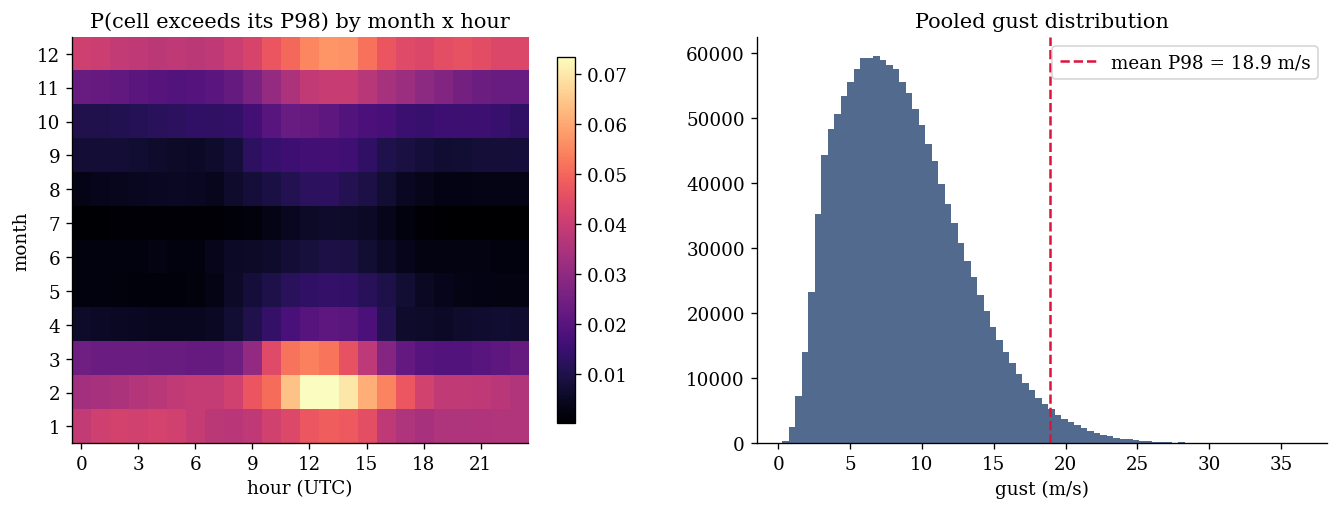

   [GBT cell 13] done in 2s
Events per cell: median 260  [213 - 301]
ADI  : median 385 h  | CV2: median 0.76
   [GBT cell 16] done in 1s
Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Train P98 threshold: mean=19.08 m/s [16.8, 23.9]
   [GBT cell 21] done in 1s
T=100,772 hours | 520 scored cells | test hours 15,116


In [5]:
banner("SECTION 2  ERA5 base, A2, A3 backtest, A4, A5", "no", "20-35 min")
from scipy.stats import genpareto
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score, average_precision_score
S2 = {}

G = new_ns()
run_src("GBT", [2, 4, 6, 7, 8, 9, 13, 16, 21], G)          # imports, config, loader, fields, land mask, cell_events, split
times, gust, thr = G["times"], G["gust_cells"], G["thr_train"]
T, NC = gust.shape
tstamp = G["tstamp"]; is_tr = G["is_train_t"]; val_end = G["val_end"]; train_end = G["train_end"]
cell_ii, cell_jj, nlon, lats, lons = G["cell_ii"], G["cell_jj"], len(G["lons"]), G["lats"], G["lons"]
grid_of = (cell_ii * nlon + cell_jj).astype(np.int64)     # land-cell index k -> flat grid index
H0 = int(np.asarray(tstamp[0]).astype("datetime64[h]").astype(np.int64))
HOURS = np.asarray(tstamp).astype("datetime64[h]").astype(np.int64)
is_te = tstamp > val_end
print(f"T={T:,} hours | {NC} scored cells | test hours {int(is_te.sum()):,}")

# forward window max over (t, t+24] and backward max over [t-12, t]
fm = np.full_like(gust, -np.inf)
for dd in range(1, 25):
    fm[:T - dd] = np.maximum(fm[:T - dd], gust[dd:])
pm = gust.copy()
for dd in range(1, 13):
    pm[dd:] = np.maximum(pm[dd:], gust[:-dd])

In [6]:
DATA = load_exports()
S2["key_check"], S2["A2_onset"] = {}, {}
for tag, d in DATA.items():
    ti = d["t"] - H0; k = d["cell"]
    y_rebuilt = (fm[ti, k] > thr[k]).astype(np.int8)
    match = float((y_rebuilt == d["y"]).mean())
    S2["key_check"][tag] = dict(label_match=match, rows=int(d["y"].size))
    print(f"key check {tag:<12} labels rebuilt from the gust field agree on {match*100:.4f}% of rows")
    onset = (gust[ti, k] < thr[k]) & (pm[ti, k] <= thr[k])
    blk = block_ids(d["t"]); ub, bidx = np.unique(blk, return_inverse=True); nb = ub.size
    ys = d["y"][onset].astype(np.float64); bs = bidx[onset]
    npos_b = np.bincount(bs, weights=ys, minlength=nb); n_b = np.bincount(bs, minlength=nb).astype(float)
    pres = {nm: prep_binned(d["P"][i][onset], d["y"][onset], bs, nb) for i, nm in enumerate(d["names"])}
    exact = {nm: dict(PR_AUC=float(average_precision_score(d["y"][onset], d["P"][i][onset])),
                      ROC_AUC=float(roc_auc_score(d["y"][onset], d["P"][i][onset])))
             for i, nm in enumerate(d["names"]) if 0 < d["y"][onset].mean() < 1}
    reps_ap = {nm: [] for nm in pres}; reps_auc = {nm: [] for nm in pres}; reps_br = []
    for w in boot_weights(nb):
        reps_br.append(float(npos_b @ w / max(n_b @ w, 1e-12)))
        for nm, pre in pres.items():
            reps_ap[nm].append(ap_binned(pre, w)); reps_auc[nm].append(auc_binned(pre, w))
    S2["A2_onset"][tag] = dict(
        n_rows=int(onset.sum()), share_of_rows=float(onset.mean()), base_rate=float(ys.mean()),
        base_rate_ci=pct(reps_br), full_base_rate=float(d["y"].mean()),
        series={nm: dict(PR_AUC=exact.get(nm, {}).get("PR_AUC"), PR_AUC_ci=pct(reps_ap[nm]),
                         ROC_AUC=exact.get(nm, {}).get("ROC_AUC"), ROC_AUC_ci=pct(reps_auc[nm]))
                for nm in pres})
    print(f"  onset origins: {onset.mean()*100:.1f}% of rows, base rate {ys.mean()*100:.2f}% "
          f"[{S2['A2_onset'][tag]['base_rate_ci'][0]*100:.2f}, {S2['A2_onset'][tag]['base_rate_ci'][1]*100:.2f}]")
    for nm, r in S2["A2_onset"][tag]["series"].items():
        if r["PR_AUC"] is not None:
            print(f"    {nm:<38} PR {r['PR_AUC']:.3f} [{r['PR_AUC_ci'][0]:.3f}, {r['PR_AUC_ci'][1]:.3f}]  "
                  f"ROC {r['ROC_AUC']:.3f} [{r['ROC_AUC_ci'][0]:.3f}, {r['ROC_AUC_ci'][1]:.3f}]")
S2["A2_definition"] = "onset: gust(t) < u(i) and no exceedance (gust > u) in [t-12 h, t]; scored on each export's own rows"
save_section("S2_era5", S2)

key check CIGB_v3      labels rebuilt from the gust field agree on 100.0000% of rows
  onset origins: 94.8% of rows, base rate 5.51% [3.84, 7.41]
    Climatology                            PR 0.055 [0.038, 0.074]  ROC 0.500 [0.500, 0.500]
    Persistence                            PR 0.224 [0.173, 0.280]  ROC 0.742 [0.699, 0.789]
    Logistic Reg                           PR 0.339 [0.267, 0.413]  ROC 0.867 [0.831, 0.897]
    CIGB (ours)                            PR 0.375 [0.302, 0.452]  ROC 0.882 [0.850, 0.909]
    Croston                                PR 0.062 [0.041, 0.085]  ROC 0.551 [0.494, 0.603]
    SBA                                    PR 0.062 [0.042, 0.085]  ROC 0.551 [0.494, 0.603]
    TSB                                    PR 0.068 [0.047, 0.091]  ROC 0.567 [0.519, 0.612]
key check HEICH_CR_v2  labels rebuilt from the gust field agree on 100.0000% of rows
  onset origins: 94.8% of rows, base rate 5.52% [3.84, 7.43]
    Climatology                            PR 0.055 [0.03

In [7]:
cell_events = G["cell_events"]
te_idx = np.flatnonzero(is_te); tr_idx = np.flatnonzero(is_tr)
train_years = tr_idx.size / (24 * 365.25); test_years = te_idx.size / (24 * 365.25)
pk_tr = [cell_events(gust[tr_idx, k], thr[k], G["CFG"].DECLUS_HRS) for k in range(NC)]
pk_te = [cell_events(gust[te_idx, k], thr[k], G["CFG"].DECLUS_HRS) for k in range(NC)]
exc_pool = np.concatenate([gust[tr_idx[p], k] - thr[k] for k, p in enumerate(pk_tr) if len(p)])
exc_pool = exc_pool[exc_pool > 0]
xi_p, _, sg_p = genpareto.fit(exc_pool, floc=0)
lam = np.array([len(p) for p in pk_tr]) / train_years
bt = {}
for Tr in (1, 5):
    rl = thr + genpareto.ppf(1 - 1 / (lam * Tr), xi_p, 0, sg_p)
    obs = int(sum(int((gust[te_idx[p], k] > rl[k]).sum()) for k, p in enumerate(pk_te)))
    exp_ = NC * test_years / Tr
    bt[f"{Tr}yr"] = dict(observed=obs, expected=exp_, ratio=obs / exp_)
    print(f"  {Tr}-year level: observed {obs} test peaks above it, expected {exp_:.1f}, ratio {obs/exp_:.2f}")
S2["A3_backtest"] = dict(xi=float(xi_p), sigma=float(sg_p), n_train_excesses=int(exc_pool.size),
                         train_years=train_years, test_years=test_years, n_cells=NC, levels=bt,
                         n_test_peaks=int(sum(len(p) for p in pk_te)))
print(f"  pooled training GPD: xi {xi_p:.3f}, sigma {sg_p:.3f}, n {exc_pool.size:,}")
save_section("S2_era5", S2)

  1-year level: observed 698 test peaks above it, expected 896.7, ratio 0.78
  5-year level: observed 207 test peaks above it, expected 179.3, ratio 1.15
  pooled training GPD: xi -0.152, sigma 3.634, n 94,723

>>> saved S2_era5 -> /content/drive/MyDrive/MSc Dissertation/results/revision/S2_era5.json and merged into revision_results.json


In [8]:
V = new_ns()
V.update({k: G[k] for k in ("CFG", "times", "lats", "lons", "FIELDS", "np", "gc")})
V["CFG"].SURV_H = 48; V["CFG"].SAMPLE_STRIDE = 3
V["T"] = T
run_src("V4", [16], V)                                   # -> cause_flat (T, 825): 1 conv, 2 syn
cause_flat = V["cause_flat"]
lab = cause_flat[:, grid_of]                             # (T, NC) label per land cell and hour

exceed = gust > thr[None, :]
BIG = T + 100
nexind = np.full((T, NC), BIG, dtype=np.int32); run_ = np.full(NC, BIG, dtype=np.int32)
for t in range(T - 1, -1, -1):
    run_ = np.where(exceed[t], t, run_); nexind[t] = run_
origins = np.arange(47, T - 48, 3)                       # Survival_Wind_v3 cell 33
o_split = np.where(tstamp[origins] <= train_end, 0, np.where(tstamp[origins] <= val_end, 1, 2))

def first_crossings(sel):
    o = origins[sel]
    ei = nexind[o + 1]                                    # (n_o, NC)
    ev = (ei - o[:, None]) <= 48
    ei = np.where(ev, ei, -1)
    kk = np.broadcast_to(np.arange(NC), ei.shape)
    u = np.unique(np.stack([ei[ev], kk[ev]], 1), axis=0)  # one entry per physical exceedance (hour, cell)
    return u[:, 0], u[:, 1]

def gpd_nll_w(theta, y, w):
    ls, xi = theta; s = np.exp(ls); z = 1.0 + xi * y / s
    if np.any(z <= 0):
        return 1e18, np.zeros(2)
    W = w.sum()
    if abs(xi) < 1e-6:
        nll = ls + y / s
        g_ls = 1 - y / s
        g_xi = np.zeros_like(y)
    else:
        lz = np.log(z)
        nll = ls + (1 + 1 / xi) * lz
        g_ls = 1 - (1 + 1 / xi) * (xi * y / s) / z
        g_xi = -lz / xi ** 2 + (1 + 1 / xi) * (y / s) / z
    return float(w @ nll / W), np.array([w @ g_ls / W, w @ g_xi / W])

def gpd_fit_w(y, w, x0):
    r = minimize(gpd_nll_w, x0, args=(y, w), jac=True, method="L-BFGS-B",
                 bounds=[(-5, 5), (-0.9, 1.5)])
    return r.x

def cause_tails(hours, cells, name):
    y = np.clip(gust[hours, cells] - thr[cells], 1e-3, None)
    c = lab[hours, cells]
    out = {}
    blk = ((HOURS[hours] - HOURS[hours].min()) // (24 * BLOCK_DAYS)).astype(np.int64)
    ub, bidx = np.unique(blk, return_inverse=True); nb = ub.size
    fits = {}
    for cc, nm in ((1, "convective"), (2, "synoptic")):
        m = c == cc
        xi_s, _, sg_s = genpareto.fit(y[m], floc=0)
        th = gpd_fit_w(y[m], np.ones(m.sum()), np.array([np.log(sg_s), xi_s]))
        fits[cc] = (y[m], bidx[m], th)
        out[nm] = dict(n=int(m.sum()), xi=float(xi_s), sigma=float(sg_s),
                       xi_weighted_check=float(th[1]), sigma_weighted_check=float(np.exp(th[0])))
    t0 = time.time(); d = []
    for w in boot_weights(nb):
        xs = []
        for cc in (1, 2):
            yy, bb, th = fits[cc]
            xs.append(gpd_fit_w(yy, w[bb], th)[1])
        d.append(xs[0] - xs[1])
    lo, hi = pct(d)
    dxi = out["convective"]["xi"] - out["synoptic"]["xi"]
    out["delta_xi"] = dict(point=dxi, ci=[lo, hi], excludes_zero=bool(lo > 0 or hi < 0), blocks=int(nb))
    print(f"  {name}: xi_conv {out['convective']['xi']:+.3f} (n {out['convective']['n']:,}) | "
          f"xi_syn {out['synoptic']['xi']:+.3f} (n {out['synoptic']['n']:,}) | "
          f"dxi {dxi:+.3f} [{lo:+.3f}, {hi:+.3f}] ({time.time()-t0:.0f}s, {nb} blocks)")
    return out

h_tr, k_tr = first_crossings(o_split == 0)
h_te, k_te = first_crossings(o_split == 2)
S2["A4"] = {"first_crossings_train": cause_tails(h_tr, k_tr, "first crossings, training")}
pkh = np.concatenate([tr_idx[p] for p in pk_tr]); pkk = np.concatenate([np.full(len(p), k) for k, p in enumerate(pk_tr)])
S2["A4"]["declustered_peaks_train"] = cause_tails(pkh, pkk, "declustered peaks, training")
try:
    sj = json.loads((BASE / "heich_cr_summary.json").read_text())
    S2["A4"]["network_learned"] = dict(xi_conv=sj.get("xi_conv"), xi_syn=sj.get("xi_syn"))
    print(f"  network's learned shapes (heich_cr_summary.json): xi_conv {sj.get('xi_conv'):+.3f}, xi_syn {sj.get('xi_syn'):+.3f}")
except Exception as e:
    print("  heich_cr_summary.json not readable:", e)
save_section("S2_era5", S2)

Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Convective share of hours: 62.6%
   [V4 cell 16] done in 11s
  first crossings, training: xi_conv +0.052 (n 136,334) | xi_syn +0.011 (n 199,827) | dxi +0.042 [-0.028, +0.099] (395s, 189 blocks)
  declustered peaks, training: xi_conv -0.153 (n 46,513) | xi_syn -0.153 (n 48,210) | dxi +0.001 [-0.049, +0.060] (257s, 192 blocks)
  network's learned shapes (heich_cr_summary.json): xi_conv +0.069, xi_syn +0.036

>>> saved S2_era5 -> /content/drive/MyDrive/MSc Dissertation/results/revision/S2_era5.json and merged into revision_results.json


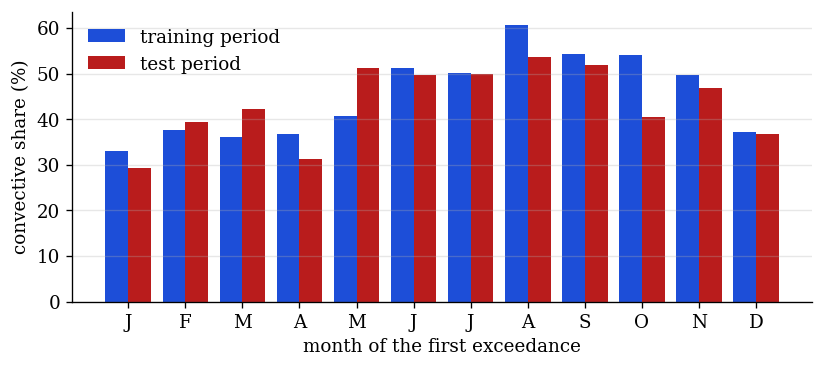

  convective share: train 40.6% | test 38.7% | training peak month 8 (May-Sep: True)


In [9]:
import matplotlib.pyplot as plt
mo_tr = times.month.values[h_tr]; mo_te = times.month.values[h_te]
lt = lab[h_tr, k_tr]; le = lab[h_te, k_te]
share_tr = [float((lt[mo_tr == m] == 1).mean()) if (mo_tr == m).any() else None for m in range(1, 13)]
share_te = [float((le[mo_te == m] == 1).mean()) if (mo_te == m).any() else None for m in range(1, 13)]
peak_m = int(np.nanargmax([np.nan if v is None else v for v in share_tr])) + 1
S2["A5_monthly"] = dict(convective_share_train=share_tr, convective_share_test=share_te,
                        overall_train=float((lt == 1).mean()), overall_test=float((le == 1).mean()),
                        n_train=int(lt.size), n_test=int(le.size), peak_month_train=peak_m,
                        peak_in_may_sep=bool(5 <= peak_m <= 9),
                        definition="share of labelled first crossings (one per exceedance hour and cell) that are convective, by calendar month")
fig, ax = plt.subplots(figsize=(7, 3.2))
xm = np.arange(1, 13)
ax.bar(xm - 0.2, [np.nan if v is None else 100 * v for v in share_tr], 0.4, label="training period", color="#1d4ed8")
ax.bar(xm + 0.2, [np.nan if v is None else 100 * v for v in share_te], 0.4, label="test period", color="#b91c1c")
ax.set_xticks(xm); ax.set_xticklabels(list("JFMAMJJASOND")); ax.set_ylabel("convective share (%)")
ax.set_xlabel("month of the first exceedance"); ax.legend(frameon=False); ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT / "storm_label_monthly.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT / "storm_label_monthly.pdf", bbox_inches="tight"); plt.show()
print(f"  convective share: train {S2['A5_monthly']['overall_train']*100:.1f}% | test {S2['A5_monthly']['overall_test']*100:.1f}% "
      f"| training peak month {peak_m} (May-Sep: {S2['A5_monthly']['peak_in_may_sep']})")

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
F = G["FIELDS"]; GRID_KM = G["CFG"].GRID * 111.32
dlon_km = np.maximum(GRID_KM * np.cos(np.deg2rad(lats)), 1e-3)

def origin_features(o, k):
    ii, jj = cell_ii[k], cell_jj[k]
    cape = F["cape"][o, ii, jj]; shear = F["ws100"][o, ii, jj] - F["ws10"][o, ii, jj]
    wms = np.sqrt(2 * np.clip(cape, 0, None)) * shear
    uo, inv = np.unique(o, return_inverse=True)
    msl = F["msl"][uo]
    gy = np.gradient(msl, axis=1) / GRID_KM; gx = np.gradient(msl, axis=2) / dlon_km[None, :, None]
    pgf = np.sqrt(gx * gx + gy * gy)[inv, ii, jj]
    return np.column_stack([cape, shear, wms, pgf]).astype(np.float64)

def event_rows(sel):
    o = origins[sel]; ei = nexind[o + 1]; ev = (ei - o[:, None]) <= 48
    oo = np.broadcast_to(o[:, None], ev.shape)[ev]; kk = np.broadcast_to(np.arange(NC), ev.shape)[ev]
    y = (lab[ei[ev], kk] == 1).astype(np.int8)
    return oo, kk, y

o_a, k_a, y_a = event_rows(o_split == 0)
rng = np.random.default_rng(SEED)
sub = np.sort(rng.choice(o_a.size, min(o_a.size, 1_000_000), replace=False))
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(origin_features(o_a[sub], k_a[sub]), y_a[sub])
o_b, k_b, y_b = event_rows(o_split == 2)
p_b = lr.predict_proba(origin_features(o_b, k_b))[:, 1]
auc_lr = float(roc_auc_score(y_b, p_b))
np.savez_compressed(OUT / "a5_logit_test_rows.npz", t_hours=HOURS[o_b], cell=grid_of[k_b], y=y_b, p=p_b.astype(np.float32))
S2["A5_logit"] = dict(features=["cape", "shear_100m_minus_10m", "wmaxshear", "pgf"], n_train=int(sub.size),
                      n_train_available=int(o_a.size), n_test=int(o_b.size), test_conv_share=float(y_b.mean()),
                      test_auc=auc_lr, rows_file="a5_logit_test_rows.npz")
print(f"  logistic baseline on origin-time variables: test AUC {auc_lr:.3f} on {o_b.size:,} test event rows")
save_section("S2_era5", S2)
del G, V, F, fm, pm, nexind, cause_flat, lab, exceed; gc.collect()

  logistic baseline on origin-time variables: test AUC 0.631 on 330,924 test event rows

>>> saved S2_era5 -> /content/drive/MyDrive/MSc Dissertation/results/revision/S2_era5.json and merged into revision_results.json


40

In [11]:
banner("SECTION 3  survival: gate, A6, Fig 4.17, A5, A1 rows", "yes (CPU fallback ~1 h)", "8-12 min on A100")
S3 = {}
V = new_ns()
run_src("V4", [2, 4], V)
V["CKPT"] = BASE / V["CFG"].CKPT_NAME
V["CLIM_PATH"] = BASE / "clim_wmax_train_v4.npy"
V["MAPS_DIR"] = (Path("/content/_nb05_maps") if IN_COLAB else OUT / "_nb05_maps")
V["IN_COLAB"] = IN_COLAB
run_src("V4", [7, 8], V)                                             # model classes; loads heich_cr_best.pt, frozen
run_src("V4", [10, 11, 12, 13, 14, 15, 16, 17, 19, 20], V,
        patches={19: [("np.save(CLIM_PATH, CLIM_WMAX)", "pass")]})    # labels, maps, loaders; no write to BASE

SECTION 3  survival: gate, A6, Fig 4.17, A5, A1 rows
  needs GPU: yes (CPU fallback ~1 h) | estimated time: 8-12 min on A100 | started 13:14:24
torch 2.11.0+cu128 | device cuda | amp torch.bfloat16
GPU: NVIDIA A100-SXM4-80GB
   [V4 cell 2] done in 0s
Config ready | RUN_MODE auto | SURV_H 48 | RAW_DIR /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full
   [V4 cell 4] done in 0s
   [V4 cell 7] done in 0s
loaded heich_cr_best.pt | frozen 40,891 params | trainable 200 (lin_wq + ai_wq only)
   [V4 cell 8] done in 0s
NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276
   [V4 cell 10] done in 0s
   [V4 cell 11] done in 0s
   [V4 cell 12] done in 0s
ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']
   [V4 cell 13] done in 100s
NaN cleaning: 1,849,650 ->

{'__name__': '__main__',
 'BASE': PosixPath('/content/drive/MyDrive/MSc Dissertation'),
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__(name, globals=None, locals=None, fromlist=(), level=0)>,
  'abs': <function abs(x, /)>,
  'all': <function all(iterable, /)>,
  'any': <function a

In [12]:
import torch
from sklearn.metrics import average_precision_score, roc_auc_score
model, DEVICE, CFG = V["model"], V["DEVICE"], V["CFG"]
LMt = V["LAND_MASK"].to(DEVICE); LMnp = V["LAND_MASK"].numpy(); H = CFG.SURV_H; DT = CFG.DT_HOURS
te_i, tr_i, origins, T = V["te_i"], V["tr_i"], V["origins"], V["T"]
ET, EC = V["ET"], V["EC"]
assert origins.max() + H <= T - 1, "an origin's horizon runs past the record: censoring inside the horizon"
S3["censoring_check"] = dict(max_origin=int(origins.max()), horizon=H, T=int(T), censored_inside_horizon=False,
                             note="origins stop at T - SURV_H (v3 FIX 07); a window without an exceedance is a non-event")
AMP = dict(device_type=DEVICE.type, dtype=V["AMP_DTYPE"], enabled=DEVICE.type == "cuda")
cif_c = np.zeros(H); cif_s = np.zeros(H); n_rows = 0
bs_sum = np.zeros(H); p24, y24, Cc, Cs, ECr, keys_t, keys_c = [], [], [], [], [], [], []
grid_land = np.flatnonzero(LMnp.ravel())
t0 = time.time(); model.eval()
with torch.no_grad():
    for bi, (x, et, ec, xw, mw, s) in enumerate(V["make_loader"](te_i)):
        with torch.autocast(**AMP):
            haz = model(x.to(DEVICE, non_blocking=True))[0]
        lam, Lam = V["cumhazard"](haz.float(), DT); S = torch.exp(-Lam)          # (B,H,[2],lat,lon)
        F_t = (1 - S)[:, :, LMt]                                                # P(T <= t), (B,H,NL)
        c1 = (torch.cumsum(lam[:, :, 0] * S, 1) * DT)[:, :, LMt]; c2 = (torch.cumsum(lam[:, :, 1] * S, 1) * DT)[:, :, LMt]
        cif_c += c1.sum((0, 2)).cpu().numpy(); cif_s += c2.sum((0, 2)).cpu().numpy()
        etl = et[:, LMnp].numpy(); ecl = ec[:, LMnp].numpy()
        obs = ((etl[:, None, :] <= np.arange(1, H + 1)[None, :, None]) & (ecl[:, None, :] > 0)).astype(np.float32)
        bs_sum += ((obs - F_t.cpu().numpy()) ** 2).sum((0, 2))
        n_rows += etl.size
        p24.append(F_t[:, CFG.COLLAPSE_L - 1].cpu().numpy().ravel())
        y24.append(((etl <= CFG.COLLAPSE_L) & (ecl > 0)).ravel())
        # v3 cell 43: CIF at the horizon as a plain sum over steps
        Cc.append(((lam[:, :, 0] * S).sum(1) * DT)[:, LMt].cpu().numpy().ravel())
        Cs.append(((lam[:, :, 1] * S).sum(1) * DT)[:, LMt].cpu().numpy().ravel())
        ECr.append(ecl.ravel())
        keys_t.append(np.repeat(V["O_HOURS"][s.numpy()], LMnp.sum())); keys_c.append(np.tile(grid_land, len(s)))
        if bi % 100 == 0:
            print(f"  batch {bi+1} | {time.time()-t0:.0f}s", flush=True)
p24 = np.concatenate(p24); y24 = np.concatenate(y24).astype(int)
Cc, Cs, ECr = np.concatenate(Cc), np.concatenate(Cs), np.concatenate(ECr)
keys_t, keys_c = np.concatenate(keys_t), np.concatenate(keys_c)
ap24 = float(average_precision_score(y24, np.clip(p24, 1e-6, 1 - 1e-6)))
ev = ECr > 0
ptype = Cc[ev] / (Cc[ev] + Cs[ev] + 1e-9)
auc_type = float(roc_auc_score((ECr[ev] == 1).astype(int), ptype))
g_ok = (f"{ap24:.3f}" == EXPECTED["occ_pr"]["HEICH_CR_v2"]) and (f"{auc_type:.3f}" == EXPECTED["storm_type_auc"])
S3["gate"] = dict(pr_auc_24=ap24, storm_type_auc=auc_type, expected_pr=EXPECTED["occ_pr"]["HEICH_CR_v2"],
                  expected_auc=EXPECTED["storm_type_auc"], passed=g_ok, seconds=time.time() - t0)
print(f"GATE survival: PR-AUC@24 {ap24:.4f} (expect {EXPECTED['occ_pr']['HEICH_CR_v2']}) | "
      f"storm-type AUC {auc_type:.4f} (expect {EXPECTED['storm_type_auc']}) -> {'OK' if g_ok else 'MISMATCH'}")
save_section("S3_survival", S3)
if not g_ok:
    raise SystemExit("STOP: the survival checkpoint does not reproduce the published values; Section 3 ends here.")

  batch 1 | 7s
  batch 101 | 12s
  batch 201 | 16s
  batch 301 | 20s
  batch 401 | 24s
  batch 501 | 28s
  batch 601 | 32s
GATE survival: PR-AUC@24 0.5701 (expect 0.570) | storm-type AUC 0.6601 (expect 0.660) -> OK

>>> saved S3_survival -> /content/drive/MyDrive/MSc Dissertation/results/revision/S3_survival.json and merged into revision_results.json


  at 48 h: empirical conv 5.07% syn 7.60% total 12.67% | predicted conv 4.44% syn 6.51% total 10.94%
  IBS 0.04780 | climatology 0.06977 | skill 31.5%
  event rate within 48 h: all origins & all cells 12.52% | test period, scored cells 12.67%


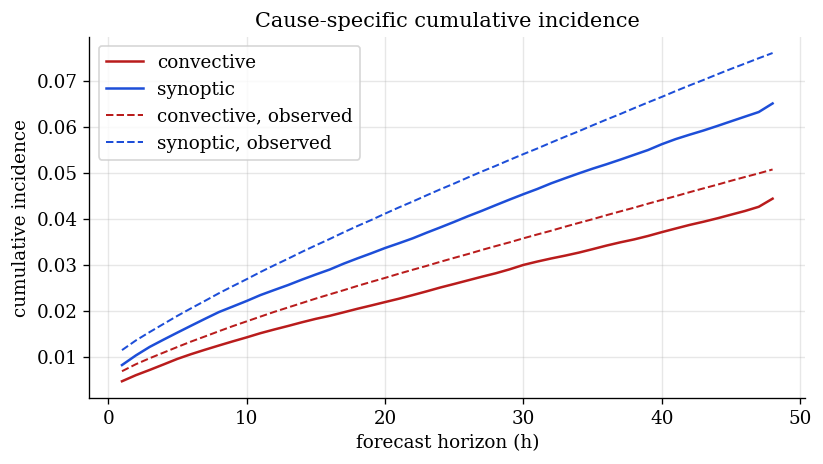


>>> saved S3_survival -> /content/drive/MyDrive/MSc Dissertation/results/revision/S3_survival.json and merged into revision_results.json


In [13]:
ets = ET[te_i][:, LMnp]; ecs = EC[te_i][:, LMnp]; etr = ET[tr_i][:, LMnp]; ecr = EC[tr_i][:, LMnp]
tt = np.arange(1, H + 1)
emp_c = np.array([((ecs == 1) & (ets <= t)).mean() for t in tt])
emp_s = np.array([((ecs == 2) & (ets <= t)).mean() for t in tt])
pred_c, pred_s = cif_c / n_rows, cif_s / n_rows
F_clim = np.array([((ecr > 0) & (etr <= t)).mean() for t in tt])          # training-period P(T <= t)
bs = bs_sum / n_rows
bs_clim = np.array([float(((((ecs > 0) & (ets <= t)).astype(float) - F_clim[t - 1]) ** 2).mean()) for t in tt])
ibs, ibs_clim = float(bs.mean()), float(bs_clim.mean())
S3["A6"] = dict(
    empirical_cif_conv=emp_c, empirical_cif_syn=emp_s, mean_predicted_cif_conv=pred_c, mean_predicted_cif_syn=pred_s,
    at_48h=dict(emp_conv=float(emp_c[-1]), emp_syn=float(emp_s[-1]), pred_conv=float(pred_c[-1]),
                pred_syn=float(pred_s[-1]), emp_total=float(emp_c[-1] + emp_s[-1]),
                pred_total=float(pred_c[-1] + pred_s[-1]),
                diff_total_pp=float(100 * ((pred_c[-1] + pred_s[-1]) - (emp_c[-1] + emp_s[-1]))),
                diff_conv_pp=float(100 * (pred_c[-1] - emp_c[-1])), diff_syn_pp=float(100 * (pred_s[-1] - emp_s[-1]))),
    brier_by_t=bs, brier_clim_by_t=bs_clim, ibs=ibs, ibs_clim=ibs_clim, ibs_skill=float(1 - ibs / ibs_clim),
    climatology="training-period empirical P(T <= t) over scored cells, one value per t",
    rate_12_7_check=dict(all_origins_all_cells=float((EC > 0).mean()),
                         test_scored_cells_48h=float((ecs > 0).mean()),
                         note="heich_cr_summary 'event_rate_%' = (EC>0).mean() over train+val+test origins and all 825 cells"))
a = S3["A6"]["at_48h"]
print(f"  at 48 h: empirical conv {a['emp_conv']*100:.2f}% syn {a['emp_syn']*100:.2f}% total {a['emp_total']*100:.2f}% | "
      f"predicted conv {a['pred_conv']*100:.2f}% syn {a['pred_syn']*100:.2f}% total {a['pred_total']*100:.2f}%")
print(f"  IBS {ibs:.5f} | climatology {ibs_clim:.5f} | skill {S3['A6']['ibs_skill']*100:.1f}%")
print(f"  event rate within 48 h: all origins & all cells {S3['A6']['rate_12_7_check']['all_origins_all_cells']*100:.2f}% | "
      f"test period, scored cells {S3['A6']['rate_12_7_check']['test_scored_cells_48h']*100:.2f}%")

import matplotlib.pyplot as plt                     # Fig 4.17, v3 cell 49 plot + empirical curves dashed
plt.figure(figsize=(7, 4))
plt.plot(tt, pred_c, label="convective", color="#b91c1c")
plt.plot(tt, pred_s, label="synoptic", color="#1d4ed8")
plt.plot(tt, emp_c, "--", label="convective, observed", color="#b91c1c", lw=1.2)
plt.plot(tt, emp_s, "--", label="synoptic, observed", color="#1d4ed8", lw=1.2)
plt.xlabel("forecast horizon (h)"); plt.ylabel("cumulative incidence"); plt.title("Cause-specific cumulative incidence")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(OUT / "cumulative_incidence.png", bbox_inches="tight"); plt.show()
save_section("S3_survival", S3)

In [14]:
fA5 = OUT / "a5_logit_test_rows.npz"
if fA5.exists():
    z = np.load(fA5)
    k_s = keys_t[ev] * 100000 + keys_c[ev]; k_l = z["t_hours"] * 100000 + z["cell"]
    common, i_s, i_l = np.intersect1d(k_s, k_l, return_indices=True)
    y_c = z["y"][i_l].astype(np.int8); assert np.array_equal(y_c, (ECr[ev][i_s] == 1).astype(np.int8)), "labels differ"
    ps, pl = ptype[i_s], z["p"][i_l]
    th = (common // 100000); blk = block_ids(th); ub, bidx = np.unique(blk, return_inverse=True); nb = ub.size
    pre_s, pre_l = prep_binned(ps, y_c, bidx, nb), prep_binned(pl, y_c, bidx, nb)
    r_s, r_l = [], []
    for w in boot_weights(nb):
        r_s.append(auc_binned(pre_s, w)); r_l.append(auc_binned(pre_l, w))
    r_s, r_l = np.array(r_s), np.array(r_l)
    S3["A5_same_rows"] = dict(n_rows=int(common.size), rows_matched_of_logit=float(common.size / k_l.size),
                              survival_auc=float(roc_auc_score(y_c, ps)), survival_auc_ci=pct(r_s),
                              logistic_auc=float(roc_auc_score(y_c, pl)), logistic_auc_ci=pct(r_l),
                              diff_survival_minus_logistic=float(roc_auc_score(y_c, ps) - roc_auc_score(y_c, pl)),
                              diff_ci=pct(r_s - r_l))
    r = S3["A5_same_rows"]
    print(f"  same {r['n_rows']:,} rows: survival AUC {r['survival_auc']:.3f} {np.round(r['survival_auc_ci'],3)} | "
          f"logistic on origin variables {r['logistic_auc']:.3f} {np.round(r['logistic_auc_ci'],3)} | "
          f"diff {r['diff_survival_minus_logistic']:+.3f} {np.round(r['diff_ci'],3)}")
else:
    print("  a5_logit_test_rows.npz not found: run Section 2 first. Skipped.")
save_section("S3_survival", S3)

  same 330,924 rows: survival AUC 0.660 [0.621 0.696] | logistic on origin variables 0.631 [0.597 0.663] | diff +0.029 [-0.007  0.062]

>>> saved S3_survival -> /content/drive/MyDrive/MSc Dissertation/results/revision/S3_survival.json and merged into revision_results.json


In [15]:
sd4 = torch.load(BASE / "heich_cr_best_wmax_v4.pt", map_location="cpu", weights_only=True)
model.load_state_dict(sd4, strict=True); model.to("cpu"); model.eval()
V["model"] = model
zc = np.load(BASE / "wmax_cache_v4_test.npz")
with torch.no_grad():
    ql = torch.cat([V["head_from_features"](torch.from_numpy(zc["xlin"][i:i + 65536].astype(np.float32)),
                                            torch.from_numpy(zc["h"][i:i + 65536].astype(np.float32)))
                    for i in range(0, len(zc["y_log"]), 65536)]).numpy()
q = np.sort(np.exp(np.clip(ql, -20, 20)), axis=1); yv = np.exp(np.clip(zc["y_log"], -20, 20))
TAU = np.asarray(CFG.QLEVELS, float); clim = np.load(BASE / "clim_wmax_train_v4.npy"); cq = np.quantile(clim, TAU)
_tr = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

def crps_rows(obs, qq):
    d = obs[:, None] - qq
    return 2.0 * _tr(np.maximum(TAU[None] * d, (TAU[None] - 1) * d), TAU, axis=1)

cr = crps_rows(yv, q); crc = crps_rows(yv, np.repeat(cq[None], yv.size, 0))
skill = 100 * (1 - cr.mean() / crc.mean()); cov = float(((yv >= q[:, 0]) & (yv <= q[:, -1])).mean())
ok = f"{skill:.1f}" == EXPECTED["surv_sev"]["skill"] and f"{cov:.3f}" == EXPECTED["surv_sev"]["cov"]
np.savez_compressed(OUT / "sev_rows_survival.npz", t_hours=zc["t_hours"], cell=zc["cell"], obs=yv, q=q,
                    crps=cr, crps_clim=crc)
S3["A1_rows"] = dict(n=int(yv.size), crps_skill=float(skill), coverage=cov, gate_passed=ok,
                     expected=EXPECTED["surv_sev"], file="sev_rows_survival.npz",
                     tail_quantiles="not available: the window-maximum head has only the 0.10-0.90 quantiles")
print(f"  survival frozen-trunk head: CRPS skill {skill:.2f}% coverage {cov:.3f} "
      f"(expect {EXPECTED['surv_sev']}) -> {'OK' if ok else 'MISMATCH'}")
save_section("S3_survival", S3)
try:
    del V["MAPS_MM"]; gc.collect(); V["MAPS_FILE"].unlink()
except Exception:
    pass
del V, zc; gc.collect()

  survival frozen-trunk head: CRPS skill 8.87% coverage 0.799 (expect {'skill': '8.9', 'cov': '0.799'}) -> OK

>>> saved S3_survival -> /content/drive/MyDrive/MSc Dissertation/results/revision/S3_survival.json and merged into revision_results.json


0

In [16]:
banner("SECTION 4  hybrid: severity gate, A1 rows, A3 tail", "yes (CPU fallback >1 h)", "8-12 min on A100")
S4 = {}
Hy = new_ns()
run_src("HYB", [2, 4, 6, 7, 8, 9, 10, 26, 27, 28, 30, 32, 33, 35, 36, 38, 42, 50, 51], Hy,
        patches={4: [("CFG.CACHE.mkdir(parents=True,exist_ok=True)", "pass")], 51: [NO_CSV]},
        cut={42: "model.load_state_dict(torch.load(CKPT"})
tab = Hy["_S_TABLE"]; cov_col = [c for c in tab.columns if c.startswith("cover")][0]
row = tab.loc["ConvGRU hybrid: shifted"]
skill, cov = float(row["CRPS skill %"]), float(row[cov_col])
ok = f"{skill:.1f}" == EXPECTED["hyb_sev"]["skill"] and f"{cov:.3f}" == EXPECTED["hyb_sev"]["cov"]
S4["gate"] = dict(crps_skill_shifted=skill, coverage_shifted=cov, expected=EXPECTED["hyb_sev"], passed=ok,
                  raw_row=dict(crps_skill=float(tab.loc["ConvGRU hybrid: raw", "CRPS skill %"]),
                               coverage=float(tab.loc["ConvGRU hybrid: raw", cov_col])))
print(f"GATE hybrid severity (shifted): skill {skill:.2f}% coverage {cov:.3f} (expect {EXPECTED['hyb_sev']}) -> "
      f"{'OK' if ok else 'MISMATCH'}")
save_section("S4_hybrid", S4)

SECTION 4  hybrid: severity gate, A1 rows, A3 tail
  needs GPU: yes (CPU fallback >1 h) | estimated time: 8-12 min on A100 | started 13:19:22
torch 2.11.0+cu128 | device cuda | amp torch.bfloat16
GPU: NVIDIA A100-SXM4-80GB
   [HYB cell 2] done in 0s
Config ready | RUN_MODE auto | RAW_DIR /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full
   [HYB cell 4] done in 0s
NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276
   [HYB cell 6] done in 0s
   [HYB cell 7] done in 0s
   [HYB cell 8] done in 0s
ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']
   [HYB cell 9] done in 102s
NaN cleaning: 1,849,650 -> 0 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=9.26  max=44.62 m/s
   [HYB cell 10] done in 50s
Synoptic + kine

In [17]:
if ok:
    LMnp = Hy["LMnp"]; te_o = Hy["te_o"]; NL = int(LMnp.sum())
    hrs = np.asarray(Hy["tstamp"][te_o]).astype("datetime64[h]").astype(np.int64)
    pt = Hy["_pt"]
    keys_t = np.repeat(hrs, NL)[pt]; keys_c = np.tile(np.flatnonzero(LMnp.ravel()), len(te_o))[pt]
    MC = Hy["MAG_CAL"]["ConvGRU hybrid"]
    obs = np.asarray(MC["obs"], float); q = np.asarray(MC["q_shift"], float)
    TAU = np.asarray(Hy["QT_LEVELS"], float); trn = np.asarray(Hy["_S_TRAIN"], float)
    cq = np.quantile(trn, TAU); _tr = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

    def crps_rows(o, qq):
        d = o[:, None] - qq
        return 2.0 * _tr(np.maximum(TAU[None] * d, (TAU[None] - 1) * d), TAU, axis=1)

    cr = crps_rows(obs, q); crc = crps_rows(obs, np.repeat(cq[None], obs.size, 0))
    assert abs(100 * (1 - cr.mean() / crc.mean()) - skill) < 1e-6, "per-row CRPS does not add up to the table"
    tail_t = np.array([0.95, 0.99])
    qt = Hy["gpd_quant"](Hy["_st"][pt], Hy["_XIm"], tail_t)
    ct = np.quantile(trn, tail_t)
    tail = {}
    for j, tau in enumerate(tail_t):
        d = obs - qt[:, j]; dc = obs - ct[j]
        qs = np.mean(np.maximum(tau * d, (tau - 1) * d)); qsc = np.mean(np.maximum(tau * dc, (tau - 1) * dc))
        tail[str(tau)] = dict(qs=float(qs), qs_clim=float(qsc), skill_pct=float(100 * (1 - qs / qsc)))
        print(f"  hybrid tail tau {tau}: quantile score {qs:.4f} vs climatology {qsc:.4f} -> skill {100*(1-qs/qsc):+.1f}%")
    np.savez_compressed(OUT / "sev_rows_hybrid.npz", t_hours=keys_t, cell=keys_c, obs=obs, q=q, crps=cr,
                        crps_clim=crc, q_tail=qt)
    S4["A1_rows"] = dict(n=int(obs.size), file="sev_rows_hybrid.npz", crps_skill=skill, coverage=cov)
    S4["A3_tail"] = dict(method="Hybrid_Wind_v3 gpd_quant(sigma, xi) of the magnitude checkpoint; climatology = the notebook's own training positives",
                         xi=float(Hy["_XIm"]), taus=tail)
else:
    S4["A1_rows"] = "not available: severity gate failed"; S4["A3_tail"] = "not available: severity gate failed"
save_section("S4_hybrid", S4)
del Hy; gc.collect()

  hybrid tail tau 0.95: quantile score 0.3581 vs climatology 0.3729 -> skill +4.0%
  hybrid tail tau 0.99: quantile score 0.1264 vs climatology 0.1156 -> skill -9.3%

>>> saved S4_hybrid -> /content/drive/MyDrive/MSc Dissertation/results/revision/S4_hybrid.json and merged into revision_results.json


1322

SECTION 5  gradient-boosted trees
  needs GPU: no (CPU-bound) | estimated time: 60-90 min | started 13:23:34
LightGBM 4.6.0 | NumPy 2.1.3 | Pandas 2.2.3
   [GBT cell 2] done in 0s
Config ready. RUN_MODE = auto
RAW_DIR = /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full
Tip: on a low-RAM runtime set CFG.TIME_STRIDE=3 and CFG.MAX_CELLS=250 before running on.
   [GBT cell 4] done in 0s
NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276
   [GBT cell 6] done in 0s
Synthetic generator defined.
   [GBT cell 7] done in 0s
ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']
   [GBT cell 8] done in 102s
NaN cleaning: 1,849,650 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=8.71  max=44.62 m/s
   [GBT cell 9] done in 47s

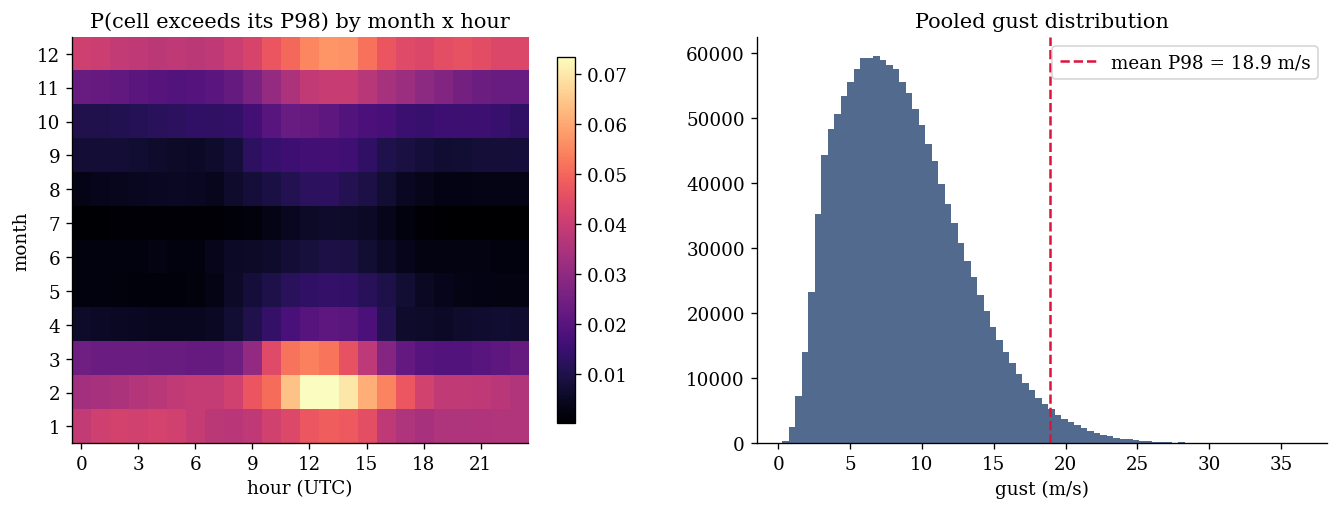

   [GBT cell 13] done in 2s
Events per cell: median 260  [213 - 301]
ADI  : median 385 h  | CV2: median 0.76
   [GBT cell 16] done in 1s
Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Train P98 threshold: mean=19.08 m/s [16.8, 23.9]
   [GBT cell 21] done in 1s
Synoptic grid features computed: (100772, 25, 33)
   [GBT cell 23] done in 3s
Base features: 20
   [GBT cell 24] done in 6s
Spatial neighbourhood features added: ['gust_nmax5', 'cape_nmean5', 'wmaxshear_nmax5', 'pgf_nmax5', 'adv_gust']
   [GBT cell 25] done in 12s
Intermittency features ready. Train event rate: 22.6 events/cell/year
   [GBT cell 26] done in 4s
Regime prior - convective share of hours: 55.7%
Total features: 69  |  (T,N) array memory: 12.4 GB
Families: {'intermittency': 8, 'convective': 15, 'synoptic': 13, 'kinematic': 22, 'spatial': 5, 'temporal': 6}
   [GBT cell 27] done in 46s
Base occurrence rate (all cells/hours): 8.10%
   [GBT cell 29] done in 3s
Samples - train 12,218,960 | val 2,620,280 | test 

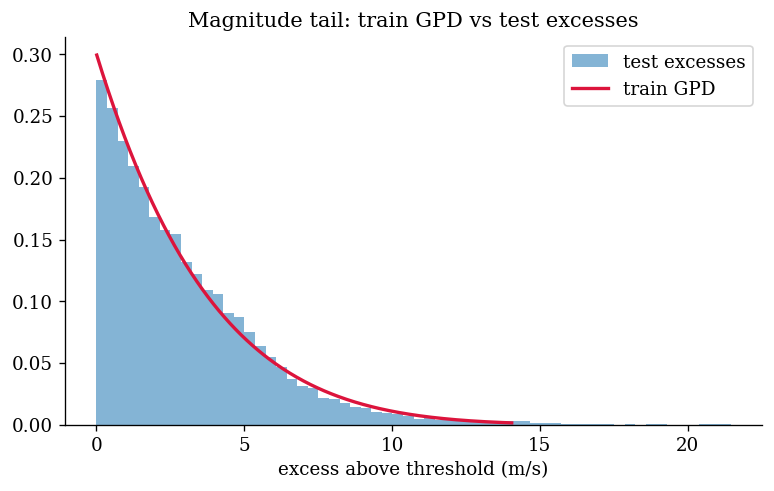

   [GBT cell 37] done in 2s
STRENGTH ON TRUE EVENTS  (n=201,360 exceedances, excess in m/s)
reference: climatology of 506,090 training-period excesses, median 2.24 m/s
             MAE m/s  MAE skill %  CRPS[10-90]  CRPS skill %  cover [0.10,0.90]  nominal
Model                                                                                   
CIGB          1.7303       9.9824       1.1026        9.5322              0.777      0.8
Climatology   1.9222       0.0000       1.2187        0.0000                NaN      0.8

Pinball loss by quantile (m/s excess, lower is better)
         pinball skill_%
Model       CIGB    CIGB
quantile                
0.10      0.2597  6.3043
0.25      0.5632  9.3075
0.50      0.8651  9.9824
0.75      0.8186  9.4472
0.90      0.5221  9.5837

written -> /content/drive/MyDrive/MSc Dissertation/strength_verification.csv
   [GBT cell 49] done in 0s
GATE trees severity refit: skill 9.53% MAE 1.730 coverage 0.777 (expect {'skill': '9.5', 'mae': '1.73', 'cov': '0.

In [18]:
banner("SECTION 5  gradient-boosted trees", "no (CPU-bound)", "60-90 min")
S5 = {"threads": NTHREADS}
Gb = new_ns(); Gb["NTHREADS"] = NTHREADS
run_src("GBT", [2, 4, 6, 7, 8, 9, 13, 16, 21, 23, 24, 25, 26, 27, 29, 30, 31], Gb)
DET = "random_state=SEED, n_jobs=NTHREADS, deterministic=True, verbosity=-1)"
run_src("GBT", [36, 37, 49], Gb, patches={36: [("random_state=SEED, n_jobs=-1, verbosity=-1)", DET)], 49: [NO_CSV]})
tab = Gb["_S_TABLE"]; cov_col = [c for c in tab.columns if c.startswith("cover")][0]
sk, mae, cov = float(tab.loc["CIGB", "CRPS skill %"]), float(tab.loc["CIGB", "MAE m/s"]), float(tab.loc["CIGB", cov_col])
e = EXPECTED["gbt_sev"]
ok = f"{sk:.1f}" == e["skill"] and f"{mae:.2f}" == e["mae"] and f"{cov:.3f}" == e["cov"]
S5["severity_gate"] = dict(crps_skill=sk, mae=mae, coverage=cov, expected=e, passed=ok)
print(f"GATE trees severity refit: skill {sk:.2f}% MAE {mae:.3f} coverage {cov:.3f} (expect {e}) -> {'OK' if ok else 'MISMATCH'}")
if ok:
    t_idx, c_idx, pos_te = Gb["t_idx"], Gb["c_idx"], Gb["pos_te"]
    nlon = len(Gb["lons"]); ci, cj = Gb["cell_ii"], Gb["cell_jj"]
    hrs = np.asarray(Gb["tstamp"][t_idx[pos_te]]).astype("datetime64[h]").astype(np.int64)
    cells = (ci[c_idx[pos_te]] * nlon + cj[c_idx[pos_te]]).astype(np.int64)
    obs = np.exp(Gb["mte"]).astype(float); q = np.sort(np.exp(Gb["mq_te"]).astype(float), axis=1)
    trn = np.exp(Gb["mtr"]).astype(float)
    TAU = np.asarray(Gb["CFG"].QUANTILES, float); cq = np.quantile(trn, TAU)
    _tr = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

    def crps_rows(o, qq):
        d = o[:, None] - qq
        return 2.0 * _tr(np.maximum(TAU[None] * d, (TAU[None] - 1) * d), TAU, axis=1)

    cr = crps_rows(obs, q); crc = crps_rows(obs, np.repeat(cq[None], obs.size, 0))
    assert abs(100 * (1 - cr.mean() / crc.mean()) - sk) < 1e-6, "per-row CRPS does not add up to the table"
    from scipy.stats import genpareto
    tail_t = np.array([0.95, 0.99]); tq = genpareto.ppf(tail_t, Gb["xi_tr"], 0, Gb["sg_tr"])   # cell 37 rule
    ct = np.quantile(trn, tail_t); tail = {}
    for j, tau in enumerate(tail_t):
        d = obs - tq[j]; dc = obs - ct[j]
        qs = np.mean(np.maximum(tau * d, (tau - 1) * d)); qsc = np.mean(np.maximum(tau * dc, (tau - 1) * dc))
        tail[str(tau)] = dict(qs=float(qs), qs_clim=float(qsc), skill_pct=float(100 * (1 - qs / qsc)),
                              forecast_quantile=float(tq[j]), clim_quantile=float(ct[j]))
        print(f"  trees tail tau {tau}: GPD quantile {tq[j]:.2f} m/s vs climatological {ct[j]:.2f} | "
              f"skill {100*(1-qs/qsc):+.1f}%")
    np.savez_compressed(OUT / "sev_rows_gbt.npz", t_hours=hrs, cell=cells, obs=obs, q=q, crps=cr, crps_clim=crc)
    S5["A1_rows"] = dict(n=int(obs.size), file="sev_rows_gbt.npz")
    S5["A3_tail"] = dict(method="XGBoost_Wind_v2 cell 37: beyond q90 the training-period GPD quantile, the same for every row",
                         xi=float(Gb["xi_tr"]), sigma=float(Gb["sg_tr"]), taus=tail)
else:
    S5["A1_rows"] = "not available: severity refit did not reproduce Table 4.4 (log the mismatch)"
    S5["A3_tail"] = "not available: severity refit did not reproduce Table 4.4"
save_section("S5_gbt", S5)

In [19]:
from sklearn.metrics import average_precision_score, roc_auc_score
S5["A7_seeds"] = {}
SEEDS = (42, 43, 44)
patch33 = [("random_state=SEED, n_jobs=-1, verbosity=-1)",
            "random_state=_RUN_SEED, n_jobs=NTHREADS, deterministic=True, verbosity=-1)")]
KEEP = None
for s in SEEDS:
    Gb["_RUN_SEED"] = s
    t0 = time.time()
    run_src("GBT", [33, 34], Gb, patches={33: patch33})
    pr = float(average_precision_score(Gb["yte"], Gb["p_te"])); pr_raw = float(average_precision_score(Gb["yte"], Gb["p_te_raw"]))
    S5["A7_seeds"][str(s)] = dict(pr_auc_calibrated=pr, pr_auc_raw=pr_raw, roc_auc=float(roc_auc_score(Gb["yte"], Gb["p_te"])),
                                  best_iteration=int(Gb["clf"].best_iteration_ or 0), minutes=(time.time() - t0) / 60)
    print(f"  seed {s}: test PR-AUC {pr:.4f} (raw {pr_raw:.4f}) | {S5['A7_seeds'][str(s)]['minutes']:.1f} min")
    if s == 42:
        g42 = f"{pr:.3f}" == EXPECTED["gbt_pr_seed42"]
        S5["seed42_gate"] = dict(pr_auc=pr, expected=EXPECTED["gbt_pr_seed42"], passed=g42)
        print(f"GATE seed-42 refit PR-AUC {pr:.4f} (expect {EXPECTED['gbt_pr_seed42']}) -> {'OK' if g42 else 'MISMATCH'}")
        if g42:
            run_src("GBT", [41, 42], Gb)
            KEEP = dict(clf=Gb["clf"], iso=Gb["iso"], op_thr=Gb["op_thr"])
    save_section("S5_gbt", S5)
prs = [S5["A7_seeds"][str(s)]["pr_auc_calibrated"] for s in SEEDS]
S5["A7_summary"] = dict(seeds=list(SEEDS), pr_auc=prs, sd=float(np.std(prs, ddof=1)), mean=float(np.mean(prs)),
                        two_sd=float(2 * np.std(prs, ddof=1)))
print(f"  seed SD of test PR-AUC: {S5['A7_summary']['sd']:.4f} (2 SD = {S5['A7_summary']['two_sd']:.4f})")
save_section("S5_gbt", S5)

scale_pos_weight = 10.9
monotone constraints: 16 increasing, 1 decreasing, 52 free of 69 features
[200]	valid_0's average_precision: 0.566618
[400]	valid_0's average_precision: 0.583025
[600]	valid_0's average_precision: 0.586937
[800]	valid_0's average_precision: 0.588671
[1000]	valid_0's average_precision: 0.589367
[1200]	valid_0's average_precision: 0.589847
[1400]	valid_0's average_precision: 0.590171
[1600]	valid_0's average_precision: 0.590446
[1800]	valid_0's average_precision: 0.590676
[2000]	valid_0's average_precision: 0.590977
[2200]	valid_0's average_precision: 0.590459
Trained in 15.2 min | best iteration: 1983
Raw val PR-AUC: 0.5910 (prevalence 6.85%)
   [GBT cell 33] done in 1012s
Calibrated Brier - val: raw 0.0901 -> cal 0.0411
Mean predicted vs observed (val): 6.85% vs 6.85%

Top-15 features by split importance:
msl_tend24     3634
sin_m          3462
cos_m          3326
msl            3312
tsl            2908
wdir_sin       2415
tcwv           2229
wdir_cos       2165

  Storm case: cell 471 (55.50, -5.25) | first exceedance 2025-01-24 03:00:00 | P 24 h before = 0.077 | alarm 4 h before


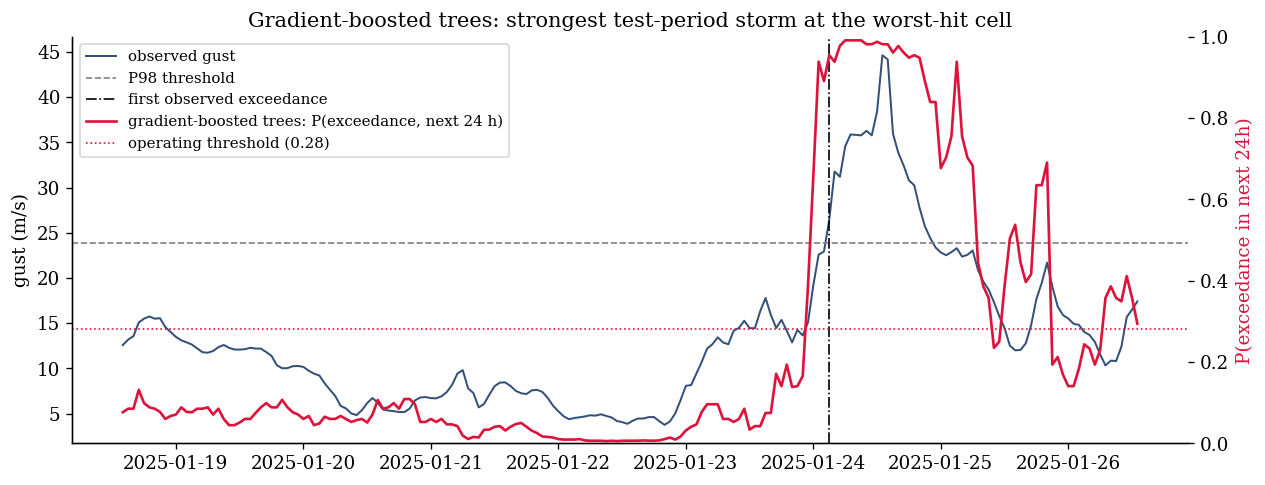

  F1 written -> /content/drive/MyDrive/MSc Dissertation/results/revision/storm_case_study.png

>>> saved S5_gbt -> /content/drive/MyDrive/MSc Dissertation/results/revision/S5_gbt.json and merged into revision_results.json


38

In [20]:
if KEEP is not None:
    import matplotlib.pyplot as plt
    FEAT, TFEAT, SFEAT = Gb["FEAT"], Gb["TFEAT"], Gb["SFEAT"]
    times, gust_cells, thr_train, CFG = Gb["times"], Gb["gust_cells"], Gb["thr_train"], Gb["CFG"]
    t_idx, c_idx, te_sel, FMX, T = Gb["t_idx"], Gb["c_idx"], Gb["te_sel"], Gb["FMX"], Gb["T"]
    cols = Gb["Xtr"].columns
    clf, iso, op_thr = KEEP["clf"], KEEP["iso"], KEEP["op_thr"]

    def predict_hours(hh, k):
        X = pd.DataFrame({**{n: a[hh, k] for n, a in FEAT.items()}, **{n: v[hh] for n, v in TFEAT.items()},
                          **{n: np.full(len(hh), v[k], np.float32) for n, v in SFEAT.items()}}).astype(np.float32)[cols]
        return iso.predict(clf.predict_proba(X)[:, 1])

    # cell 51, unchanged selection of storm and window
    te_t = t_idx[te_sel]; te_c = c_idx[te_sel]
    i_worst = int(np.argmax(FMX[te_sel])); k_star, t_star = int(te_c[i_worst]), int(te_t[i_worst])
    w0, w1 = max(t_star - 120, CFG.HIST), min(t_star + 72, T - CFG.LEAD - 1)
    ts_win = np.arange(w0, w1); pw = predict_hours(ts_win, k_star)
    # first observed exceedance of the episode that contains the storm's peak (24 h runs rule)
    g = gust_cells[:, k_star]; th = float(thr_train[k_star])
    t_pk = t_star + 1 + int(np.argmax(g[t_star + 1:t_star + 1 + CFG.LEAD]))
    exc_h = np.flatnonzero(g > th); t_e = t_pk
    while True:
        prev = exc_h[(exc_h < t_e) & (exc_h >= t_e - CFG.DECLUS_HRS)]
        if prev.size == 0:
            break
        t_e = int(prev.min())
    hh = np.arange(t_e - 72, t_e + 1); ph = predict_hours(hh, k_star)
    p_24 = float(ph[hh == t_e - 24][0])
    above = np.flatnonzero(ph >= op_thr)
    alarm_h = int(hh[above[0]]) if above.size else None
    S5["A2_case"] = dict(cell=k_star, lat=float(Gb["cell_lat"][k_star]), lon=float(Gb["cell_lon"][k_star]),
                         threshold_ms=th, operating_threshold=float(op_thr),
                         peak_hour=str(times[t_pk]), first_exceedance=str(times[t_e]),
                         prob_24h_before_first_exceedance=p_24,
                         first_alarm=str(times[alarm_h]) if alarm_h is not None else None,
                         hours_alarm_to_first_exceedance=(t_e - alarm_h) if alarm_h is not None else None,
                         prob_by_hour_before=dict(zip([int(v) for v in (t_e - hh)], [float(v) for v in ph])),
                         definition="first exceedance = start of the exceedance episode containing the window peak, "
                                    "episodes split by gaps of 24 h (the declustering rule); alarm = first hour in the "
                                    "72 h before it with P >= operating threshold")
    print(f"  Storm case: cell {k_star} ({S5['A2_case']['lat']:.2f}, {S5['A2_case']['lon']:.2f}) | first exceedance "
          f"{times[t_e]} | P 24 h before = {p_24:.3f} | alarm {S5['A2_case']['hours_alarm_to_first_exceedance']} h before")
    # F1: cell 51 figure, adding a legend entry for the threshold, the model name, and the first-exceedance marker
    fig, ax1 = plt.subplots(figsize=(12, 4.4))
    ax1.plot(times[ts_win], gust_cells[ts_win, k_star], color="#33507a", lw=1.2, label="observed gust")
    ax1.axhline(thr_train[k_star], color="gray", ls="--", lw=1, label="P98 threshold")
    ax1.axvline(times[t_e], color="k", ls="-.", lw=1, label="first observed exceedance")
    ax1.set_ylabel("gust (m/s)")
    ax2 = ax1.twinx()
    ax2.plot(times[ts_win], pw, color="crimson", lw=1.6, label="gradient-boosted trees: P(exceedance, next 24 h)")
    ax2.axhline(op_thr, color="crimson", ls=":", lw=1, label=f"operating threshold ({op_thr:.2f})")
    ax2.set_ylabel("P(exceedance in next 24h)", color="crimson"); ax2.set_ylim(0, 1)
    l1 = ax1.get_legend_handles_labels(); l2 = ax2.get_legend_handles_labels()
    ax1.legend(l1[0] + l2[0], l1[1] + l2[1], loc="upper left", fontsize=9)
    ax1.set_title("Gradient-boosted trees: strongest test-period storm at the worst-hit cell")
    plt.show()
    fig.savefig(OUT / "storm_case_study.png", dpi=150, bbox_inches="tight")
    print("  F1 written ->", OUT / "storm_case_study.png")
else:
    S5["A2_case"] = "not available: the seed-42 refit did not reproduce the published model, so F1 is not regenerated"
save_section("S5_gbt", S5)
del Gb; gc.collect()

In [21]:
banner("SECTION 6  A1 paired severity bootstrap", "no", "2-5 min")
S6 = {"note": "Transformer: not available (no fine-tuned checkpoint was saved by Transformer_Wind_v3)"}
ROWS = {}
for nm, f in (("Gradient-boosted trees", "sev_rows_gbt.npz"), ("Competing-risks survival", "sev_rows_survival.npz"),
              ("Linear hazard + ConvGRU", "sev_rows_hybrid.npz")):
    p = OUT / f
    if p.exists():
        z = np.load(p); ROWS[nm] = dict(key=z["t_hours"].astype(np.int64) * 100000 + z["cell"].astype(np.int64),
                                        t=z["t_hours"].astype(np.int64), crps=z["crps"], clim=z["crps_clim"])
    else:
        print(f"  {nm}: {f} missing -> not available")
S6["available"] = list(ROWS)
names = list(ROWS); S6["pairs"] = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = ROWS[names[i]], ROWS[names[j]]
        common, ia, ib = np.intersect1d(a["key"], b["key"], return_indices=True)
        blk = block_ids(a["t"][ia]); ub, bidx = np.unique(blk, return_inverse=True); nb = ub.size
        sa = lambda w: 100 * (1 - (w[bidx] @ a["crps"][ia]) / (w[bidx] @ a["clim"][ia]))
        sb = lambda w: 100 * (1 - (w[bidx] @ b["crps"][ib]) / (w[bidx] @ b["clim"][ib]))
        one = np.ones(nb); d0 = sa(one) - sb(one)
        reps = np.array([sa(w) - sb(w) for w in boot_weights(nb)])
        lo, hi = pct(reps)
        rec = dict(A=names[i], B=names[j], n_common=int(common.size), n_A=int(a["key"].size), n_B=int(b["key"].size),
                   skill_A=float(sa(one)), skill_B=float(sb(one)), diff=float(d0), ci=[lo, hi],
                   p_A_better=float(np.mean(reps > 0)),
                   verdict="A better" if lo > 0 else ("B better" if hi < 0 else "not separable"))
        S6["pairs"].append(rec)
        print(f"  {names[i]} vs {names[j]}: n {common.size:,} | skills {rec['skill_A']:.2f} vs {rec['skill_B']:.2f} | "
              f"diff {d0:+.2f} [{lo:+.2f}, {hi:+.2f}] -> {rec['verdict']}")
save_section("S6_pairing", S6)

SECTION 6  A1 paired severity bootstrap
  needs GPU: no | estimated time: 2-5 min | started 14:07:34
  Gradient-boosted trees vs Competing-risks survival: n 201,360 | skills 9.53 vs 8.87 | diff +0.66 [-0.82, +2.28] -> not separable
  Gradient-boosted trees vs Linear hazard + ConvGRU: n 201,360 | skills 9.53 vs 5.91 | diff +3.62 [+1.77, +5.91] -> A better
  Competing-risks survival vs Linear hazard + ConvGRU: n 201,360 | skills 8.87 vs 5.91 | diff +2.96 [+0.95, +5.32] -> A better

>>> saved S6_pairing -> /content/drive/MyDrive/MSc Dissertation/results/revision/S6_pairing.json and merged into revision_results.json


In [22]:
R = json.loads(RESULTS_JSON.read_text())
print("sections present:", sorted(k for k in R))
def g(*path):
    x = R
    for p in path:
        if not isinstance(x, dict) or p not in x:
            return "n/a"
        x = x[p]
    return x
print("\n[Table 4.2 baselines, trees' test rows]")
for nm in ("TSB", "SBA", "Croston", "Persistence", "Logistic Reg", "Climatology"):
    r = g("S1_gate", "table42_baselines", nm)
    if isinstance(r, dict):
        print(f"  {nm:<13} ROC {r['ROC_AUC']:.3f}  PR {r['PR_AUC']:.3f}  BSS {r['BrierSkill']:.3f}")
print("\n[A2 onset PR-AUC, headline models]")
for tag in ("CIEW_v5b", "CIGB_v3", "HEICH_CR_v2", "HEICH_v3"):
    r = g("S2_era5", "A2_onset", tag)
    if isinstance(r, dict):
        s = r["series"][MAIN[tag]]
        print(f"  {LABEL[tag]:<28} onset PR {s['PR_AUC']:.3f} [{s['PR_AUC_ci'][0]:.3f}, {s['PR_AUC_ci'][1]:.3f}] | "
              f"base rate {r['base_rate']*100:.2f}% | share of rows {r['share_of_rows']*100:.1f}%")
print("\n[A3 backtest]", json.dumps(g("S2_era5", "A3_backtest", "levels")))
print("[A3 tails] trees:", json.dumps(g("S5_gbt", "A3_tail")), "\n            hybrid:", json.dumps(g("S4_hybrid", "A3_tail")))
print("\n[A4]", json.dumps(g("S2_era5", "A4"), indent=1)[:3000])
print("\n[A5 monthly]", json.dumps({k: v for k, v in g("S2_era5", "A5_monthly").items()} if isinstance(g("S2_era5", "A5_monthly"), dict) else "n/a"))
print("[A5 same rows]", json.dumps(g("S3_survival", "A5_same_rows")))
print("\n[A6]", json.dumps({k: v for k, v in g("S3_survival", "A6").items() if not isinstance(v, list)} if isinstance(g("S3_survival", "A6"), dict) else "n/a", indent=1))
print("\n[A1 pairs]", json.dumps(g("S6_pairing", "pairs"), indent=1))
print("\n[A7]", json.dumps(g("S5_gbt", "A7_summary")))
print("[Fig 4.10 case]", json.dumps({k: v for k, v in g("S5_gbt", "A2_case").items() if k != "prob_by_hour_before"} if isinstance(g("S5_gbt", "A2_case"), dict) else g("S5_gbt", "A2_case")))
print("\nWrite-back files in", OUT, ":", sorted(p.name for p in OUT.iterdir()))

sections present: ['S1_gate', 'S2_era5', 'S3_survival', 'S4_hybrid', 'S5_gbt', 'S6_pairing']

[Table 4.2 baselines, trees' test rows]
  TSB           ROC 0.691  PR 0.279  BSS 0.123
  SBA           ROC 0.549  PR 0.086  BSS -0.003
  Croston       ROC 0.549  PR 0.085  BSS -0.003
  Persistence   ROC 0.808  PR 0.476  BSS 0.242
  Logistic Reg  ROC 0.893  PR 0.524  BSS -0.713
  Climatology   ROC 0.500  PR 0.077  BSS -0.000

[A2 onset PR-AUC, headline models]
  Transformer (pretrained)     onset PR 0.455 [0.379, 0.527] | base rate 5.51% | share of rows 94.8%
  Gradient-boosted trees       onset PR 0.375 [0.302, 0.452] | base rate 5.51% | share of rows 94.8%
  Competing-risks survival     onset PR 0.360 [0.278, 0.450] | base rate 5.52% | share of rows 94.8%
  Linear hazard + ConvGRU      onset PR 0.344 [0.274, 0.417] | base rate 5.51% | share of rows 94.8%

[A3 backtest] {"1yr": {"observed": 698, "expected": 896.682637462925, "ratio": 0.7784247969548314}, "5yr": {"observed": 207, "expected": 17